# SK Hynix four-leg book, held static: long `xyz:SKHY` / short `xyz:SKHX`, each hedged by its own stock

## S0 · Summary

**Research question.** Is it profitable to run the SKHY / SKHX book with each perp hedged by its own stock, to collect funding? How much does each hedge leak? How much can we make?

| Trade set-up | |
|---|---|
| What is the trade | Short the Seoul perp `xyz:SKHX` against long Seoul shares `000660`, and long the New York perp `xyz:SKHY` against short Nasdaq ADS. Four legs of equal USD, to collect the net funding differential |
| Venue | Hyperliquid (xyz) for the two perps, Interactive Brokers for the two stocks |
| Type of risk | Basis, once per hedge: basis A (SKHX perp against 000660) and basis B (SKHY perp against the ADS). Together they are the spread between the two premia |
| Rules | Each perp goes on the hour its own stock can fill, held through every funding print, all four legs exit at the end of the window. No early exit is simulated. The stock legs stay matched one for one to the perps and are never re-struck: this is the held long / short on the basis, its P&L the funding plus whatever the basis does. Its sibling, `2026-09-22-xasset-skhynix-four-leg-ratio-hedge`, is the rule-hedged version that re-hedges the basis |
| Base test | Does funding net of the stock carry beat the T-bill at 1x? (S3) |
| Test 1 | Is it real: out of sample, statistically significant, after costs? (S4) |
| Test 2 | What if we exit on a rule: hold only while the trailing 7-day differential is above the bar, or above zero? (S4) |
| Test 3 | How much of the result is the entry hour? (S4) |
| Test 1d | Is the basis alone, and the total P&L, distinguishable from luck? (S4) |
| Rolling carry | Is the carry steady through the window, or does it come and go? (S4) |

**What the study cannot say.** `2026-09-22-equities-skhynix-perp-pair`, `2026-09-22-xasset-skhynix-four-leg-ratio-hedge` and this study, `2026-10-04-xasset-skhynix-four-leg-static-hold`, read the same two perps and the same cash legs over one window in one regime: they are ONE result, not three (`app/library/law/how-we-know.md#a-shared-window-is-one-result`). What did not vary between them: the perp funding and prices, the cash prices, the window, the regime, the carry model. What varied: only how the stock leg is hedged (none in the pair, re-struck by rule in the ratio-hedge study, held static here). Every return below names its mark: the book's return is the fair-value one (each stock leg re-struck on every hourly IBKR print); the close-marked figure, which prices two clocks, is named wherever it appears. Eighty days in one regime cannot separate an edge from luck: a p or an interval here describes this window and nothing after it.

## S1 · Setup

### S1.1 · Assumptions

| Assumption | Value | From |
|---|---|---|
| **Equity** | USD 1,000,000 across two accounts: the stock legs' cash and margin at IBKR, the rest as the perp pool's collateral at Hyperliquid | custom |
| Base book | 1x = four legs of USD 250,000 | custom |
| Reserve | 0 | custom |
| Entry | staggered: each perp goes on when its own stock fills (000660 at the KRX close, the ADS at the US close) | custom |
| Stock sizing | matched units: one share or ADS per perp unit | custom |
| Perp slippage | 2 bp per fill; 10 bp on unwind; liquidation fee 7.5 bp | custom |
| Stock funding | both stock legs are paid for with cash held at IBKR, no margin loan: the long 000660 costs what that cash would have earned, the T-bill 4.11% a year; the short ADS pays a 3% borrow, no credit on its proceeds, on the marked value | custom [U] |
| Broker margin | 25% of the short ADS's notional, netted against the long 000660 inside the one IBKR account with a 5% currency buffer (above the worst 5-day USD/KRW move of the window); S6 also shows no netting and 50% | custom [U] |
| **Premium stop** | 10 premium points of room | custom |
| Drawdown limit | 15% of equity | custom |
| T-bill hurdle | 4.11% a year | custom choice (US Treasury [V]) |
| Test settings | split 2026-08-20 · 2,000 shuffles · p cut 0.10 · 5-day blocks · entry sweep every hour · rolling carry window 14 days | custom |
| Perp taker fee | 0.9 bp per fill (growth tier); 9 bp standard tier | Hyperliquid [V] |
| Maintenance margin, max leverage | 5% flat; 10x | Hyperliquid [V] |
| Funding | hourly, as published, on oracle notional | Hyperliquid [V] |
| Liquidation | equity below maintenance, on the mark | Hyperliquid [V] |
| KRX costs | 1.4 bp commission per side, 20 bp sell tax on the sale | KRX [V] |
| Won conversion | 5 bp per side | Interactive Brokers [V] |
| US stock costs | USD 0.005 a share, minimum USD 1, capped at 1% of the trade | Interactive Brokers [V] |
| Dividend | 000660 ex 2026-08-28, KRW 375; 22% withholding on the long leg | exchange [V] |
| ADS ratio | 10 SKHY = 1 Korean share | fact [V] |

### S1.2 · Data

| Source | Data | Period |
|---|---|---|
| Hyperliquid | funding (hourly, settled), 1h candles, published premium, for `xyz:SKHX` and `xyz:SKHY` | 2026-07-15 to 2026-10-03 |
| EODHD | daily bars for 000660, SKHY ADS and USD/KRW: every fill and every close mark | 2026-07-06 to 2026-10-02 |
| IBKR (Gateway, delayed) | HOURLY bars, extended hours, for 000660 (KRW), the SKHY ADS and USD/KRW: every cash-line chart and the fair-value mark; pulled once and cached; a shut exchange keeps its last price | from 2026-07-08 |
| Hyperliquid (live) | margin table, max leverage and the order book | NIL |

### S1.3 · Code

In [1]:
# ---- S1.1 parameters: every knob that is OURS (owner-set, study-set or [U]); never a venue number ----
RUN_ID = None                                       # not registered in the ledger: research-005 is the run of `2026-09-22-xasset-skhynix-four-leg-ratio-hedge` (then named four-leg), this study has no pre-flight row
STEM_PAIR, STEM_RATIO, STEM_THIS = "2026-09-22-equities-skhynix-perp-pair", "2026-09-22-xasset-skhynix-four-leg-ratio-hedge", "2026-10-04-xasset-skhynix-four-leg-static-hold"   # the three studies of this one result, by their stems
EQUITY, LEV, RESERVE = 1_000_000.0, 1.0, 0.0       # owner 2026-09-22: USD 1M of equity, the base book 1x, no reserve
COIN_A, COIN_B, VENUE, DAYS = "xyz:SKHX", "xyz:SKHY", "Hyperliquid", 120
START_DATE, START_HOUR, SPLIT_DATE = "2026-07-15", 7, "2026-08-20"
ENTRY_MODE, ADS_FILL = "staggered", "close"          # owner 2026-09-27: STAGGERED is the registered entry (each perp with its own hedge)
STOCK_SIZING, SIZING_BESIDE = "units", "usd"         # research-005: each stock leg at its perp's own units (B-0246); USD sizing run beside it
CASH_HOURLY = {"A": ("000660.KS", "krx"), "B": ("SKHY", "us")}   # the in-session hourly prints the fair-value mark reads (B-0244)
LEVS, RESV = (1, 2, 3), (0.0,)                    # the rungs the capital can fund, no reserve: S6 shows the larger rungs as not fitting
RUNGS_ALL = (1, 2, 3, 4, 6, 10, 20)               # the margin table's rungs (20x = a perp collateral split of 10x, the venue's cap)
STOP_PTS, DD_LIMIT_PCT = 10.0, 15.0                  # [U] desk stop (premium points of room) and drawdown limit
MIN_HOLD_SHARE = 0.25                                # a rule that almost never trades is not a rule
NSHUF, SEED = 2000, 7
BOOT_BLOCK_D = 5                                     # [U] stationary-bootstrap mean block length, days
MC_PATHS, MC_HOLD_D = 2000, 30                       # [U] premium paths simulated, and the hold they cover, days
SWEEP_STEP_H, SWEEP_MIN_D, EXIT_STEP_H = 1, 14, 3    # entry sweep every hour, each kept >= 14 d; exit sweep every 3 h
VOL_WIN_H, VOL_WIN_D = 168, 10                       # realized-vol windows: 7 d of hourly perp closes, 10 daily cash closes
OUTLIER_PCT = 5.0                                    # an hour whose perp close moves more than this is listed
FIN_PAIRS = ((0.02, 0.02), (0.02, 0.03), (0.03, 0.03), (0.02, 0.05), (0.03, 0.05), (0.05, 0.05))   # [U] (borrow, margin) pairs
BORROW_BASE, BORROW_REBATE = 0.03, 0.0               # [U] F9: the short stock leg's borrow fee and the rebate on its proceeds (B-0248)
BORROW_SWEEP = (0.005, 0.01, 0.03, 0.05, 0.10, 0.20, 0.30)   # [U] F9: the fees the borrow sweep prices
XFER_RUNGS, XFER_DELAYS_H = (6, 10, 20), (24, 48, 72)  # [U] F10: rungs and KRW -> USDC transfer delays stressed
STOCK_FUNDING = "cash"      # custom: the stock legs are paid for with cash held at IBKR, not a margin loan
IB_MARGIN = 0.25            # custom [U]: IBKR margin on the short ADS leg, as a fraction of its notional
NETTING = True              # custom [U]: the long and the short stock leg net inside the one IBKR account; S6 also shows no netting
FX_BUF = 0.05               # custom [U]: the currency buffer on the netted legs, above the worst 5-day USD/KRW move of this window (asserted below)
KRW_LOAN = 0.07705          # custom [1]: IBKR's KRW margin loan, BM + 3.5% on 2026-09-27 (fact card margin.loan.krw): the long leg's cost if it were financed instead of paid in cash
END_UTC, WINDOW_HOURS = "2026-10-03 09:00", 1923       # custom: window end and its hours, pinned so the study reads the same hours as `2026-09-22-equities-skhynix-perp-pair`
P_CUT = 0.10                 # [U] a p-value (one-sided, against the hurdle or zero) must be below this
CI_LEVEL = 0.95              # [U] the level of the block-bootstrap interval of the mean daily P&L (Test 1d)
REGIMES = 1                  # declared: this window is one regime (the manifest says the same)
ROLL_D = 14                  # [U] the rolling window of the carry chart (Test 1a, beside the split), days: the ratio-hedge study's window, so the two books compare

In [2]:
import datetime as dt, json, os, textwrap, time
from dataclasses import replace
import matplotlib.pyplot as plt, matplotlib.dates as mdates, matplotlib.colors as mcolors
from matplotlib.patches import Patch, Rectangle
from matplotlib.colors import LinearSegmentedColormap, to_hex
import numpy as np, pandas as pd
from IPython import get_ipython
from IPython.display import HTML, Markdown, display
from fundplat.quant.core import figstyle, summary_card
from fundplat.quant.core import refdata
from fundplat.quant.crypto.backtest import hip3_pair as HP
from fundplat.quant.crypto.backtest.carry import hip3_four as F
from fundplat.quant.core import stats as ST
import fundplat.data as DATA
from fundplat.data.tradfi import intraday as INTRA
from fundplat.quant.core import report as REPORT

# ---- S1.2 + S1.3: the configuration the parameters imply, the assumptions held to the code (PROSE), the data ----
MMR = 0.05                                    # the venue's maintenance margin, asserted against refdata below
HOUR = 3_600_000
START = int((dt.datetime.fromisoformat(START_DATE).replace(tzinfo=dt.timezone.utc) + dt.timedelta(hours=START_HOUR)).timestamp() * 1000)
SPLIT = int(dt.datetime.fromisoformat(SPLIT_DATE).replace(tzinfo=dt.timezone.utc).timestamp() * 1000)
FEE_SWEEP = ((refdata.XYZ_TAKER_BPS, 2.0), (refdata.XYZ_TAKER_BPS, 5.0), (refdata.XYZ_TAKER_BPS, 10.0),
             (refdata.XYZ_STANDARD_TAKER_BPS, 2.0), (refdata.XYZ_STANDARD_TAKER_BPS, 10.0))
# [U] stock financing per year, each leg at its OWN rate since B-0248: the short leg pays the borrow b
# (`short_borrow_ann`), the long leg its margin loan m (`stock_fin_ann`). The cost sweep runs every
# (b, m) pair in FIN_PAIRS through the engine.
BOOK, CTRL = "the book", "the control"
DIRS = (BOOK,)
# the engine EXPORTS which direction is which; this notebook passes the key EXPLICITLY in every run
# rather than relying on `FourParams.direction`'s default, and labels its columns off `res["role"]`.
DKEY = {BOOK: F.BOOK_DIRECTION, CTRL: F.CONTROL_DIRECTION}
ROLE = {BOOK: "book", CTRL: "control"}
assert (F.BOOK_DIRECTION, F.CONTROL_DIRECTION) == ("short_a", "long_a")
OTHER = {BOOK: CTRL, CTRL: BOOK}
SIDE = {BOOK: -1.0, CTRL: 1.0}               # the SKHX perp's side: -1 = SHORT it, so LONG the premium
NSIGN = {BOOK: 1.0, CTRL: -1.0}              # sign of the net funding differential against the BOOK's own reading
CARRY = "funding net of all stock carry"     # ONE name for the metric every gate in steps 1 to 3 is read on


def ib_cash(N, netting=None, frac=None):
    """Cash the IBKR account holds for the two stock legs, USD: the long leg is PAID in cash (N); the short leg adds its broker margin, on its whole notional
    when the legs do not net, or on the currency buffer alone when they do (two equal-notional legs net to zero, the won leg keeps its currency risk)."""
    netting = NETTING if netting is None else netting
    frac = IB_MARGIN if frac is None else frac
    return N + frac * (FX_BUF * N if netting else N)


def fp(L=LEV, R=RESERVE, d=BOOK, netting=None, frac=None, **kw):
    """One rung, one direction. gross of the FOUR legs = equity x L; the stock legs and their margin sit at IBKR in cash, the rest of the
    equity is the perp pool's collateral at Hyperliquid (the pool's leverage setting is its gross over that collateral)."""
    assert R == 0.0
    N = L * EQUITY / 4.0
    pool = EQUITY - ib_cash(N, netting, frac)
    assert pool > 0, f"{L}x does not fit USD {EQUITY:,.0f}: the IBKR account alone needs USD {ib_cash(N, netting, frac):,.0f}"
    netting = NETTING if netting is None else netting
    frac = IB_MARGIN if frac is None else frac
    kw.setdefault("entry_mode", ENTRY_MODE); kw.setdefault("ads_fill", ADS_FILL)
    kw.setdefault("stock_sizing", STOCK_SIZING)
    kw.setdefault("stock_fin_ann", refdata.HURDLE_ANN if STOCK_FUNDING == "cash" else KRW_LOAN)       # cash that buys the stock would have earned the T-bill
    kw.setdefault("short_borrow_ann", BORROW_BASE); kw.setdefault("short_rebate_ann", BORROW_REBATE)
    return F.FourParams(notional_usd=N, direction=DKEY[d], leverage=2.0 * N / pool, reserve_mult=0.0,
                        margin_mode="cross", equity_usd=EQUITY, stock_margin_frac=frac * (FX_BUF if netting else 1.0), **kw)


PAR = {lab: fp(d=lab) for lab in DIRS}
p1 = PAR[BOOK]
assert p1.equity_usd == EQUITY and p1.notional_usd == EQUITY / 4 and abs(p1.leverage * (EQUITY - ib_cash(p1.notional_usd)) - 2 * p1.notional_usd) < 1e-6
assert p1.reserve_mult == RESERVE == 0.0 and p1.margin_mode == "cross" and abs(p1.stock_margin_frac - IB_MARGIN * FX_BUF) < 1e-12
assert p1.direction == F.BOOK_DIRECTION and not p1.regime
assert p1.stock_fin_ann == refdata.HURDLE_ANN and p1.stock_capital_frac == 1.0
assert (p1.stock_sizing, p1.short_borrow_ann, p1.short_rebate_ann) == (STOCK_SIZING, BORROW_BASE, BORROW_REBATE)
assert (p1.stock_fill, p1.fin_basis, p1.dividend_mode) == ("after_decision", "marked", "exdate")   # B-0247, the engine defaults
assert F.UNITS_PER_PERP == {"A": 1.0, "B": 1.0}
assert p1.krx_close_utc_h == 6.5                    # 15:30 KST, no DST in Korea, a fixed UTC hour all year
US_PER_DATE = p1.us_close_utc_h is None            # None = the engine derives 16:00 America/New_York per date
assert US_PER_DATE or p1.us_close_utc_h == 20.0
assert (p1.krx_commission_bps, p1.krx_sell_tax_bps, p1.fx_spread_bps) == (
    refdata.KRX_COMMISSION_BPS, refdata.KRX_SELL_TAX_BPS, refdata.FX_SPREAD_BPS)
assert (p1.us_per_share, p1.us_min_usd, p1.us_max_pct) == (
    refdata.IBKR_US_FIXED_USD_PER_SHARE, refdata.IBKR_US_FIXED_MIN_USD, refdata.IBKR_US_FIXED_MAX_PCT)
assert p1.dividend_yield_ann == F.H.SKHX_DIVIDEND_YIELD_ANN == 0.00155
assert p1.dividend_withholding == F.H.DIVIDEND_WITHHOLDING == 0.22
assert p1.hold_days_for_amortisation == 30.0        # the engine's ANALYTIC carry amortises one round trip over this
assert p1.hurdle_ann == refdata.HURDLE_ANN
_pp = HP.pair_params_simple(1_000_000.0, p1.leverage, p1.reserve_mult, "cross", "equal_usd", DKEY[BOOK],
                            gross_usd=2.0 * p1.notional_usd)
assert _pp.fee_taker_bps == refdata.XYZ_TAKER_BPS == 0.9 and _pp.exec_slippage_bps == 2.0 and not _pp.maker
assert _pp.wick_mode == "joint_adverse" and _pp.liq_fee_bps == 7.5

# ---- the venue's own margin spec: max leverage is the SETTING cap, not the desk's split ----
SPEC_A, SPEC_B = refdata.spec_for(VENUE, COIN_A, EQUITY), refdata.spec_for(VENUE, COIN_B, EQUITY)
assert SPEC_A[0] == SPEC_B[0] == MMR
MAXLEV = int(min(SPEC_A[1], SPEC_B[1]))
ENTRY_BPS = _pp.fee_taker_bps + _pp.exec_slippage_bps

# ---- the numbers the two opening tables STATE, held to the code. A table that parts from the run goes red
# ---- here. It cannot catch a table edited on its own: the right-hand values are the tables' own words.
PROSE = {"equity USD 1,000,000": (EQUITY, 1_000_000.0), "1x = four legs of USD 250,000": (p1.notional_usd, 250_000.0),
         "reserve 0": (p1.reserve_mult, 0.0), "taker 0.9 bp, growth tier": (refdata.XYZ_TAKER_BPS, 0.9),
         "standard tier 9 bp": (refdata.XYZ_STANDARD_TAKER_BPS, 9.0), "slippage 2 bp": (_pp.exec_slippage_bps, 2.0),
         "round trip 11.6 bp": (round(4 * ENTRY_BPS, 1), 11.6), "unwind 10 bp": (_pp.unwind_slippage_bps, 10.0),
         "liquidation fee 7.5 bp": (_pp.liq_fee_bps, 7.5), "KRX commission 1.4 bp": (refdata.KRX_COMMISSION_BPS, 1.4),
         "KRX sell tax 20 bp": (refdata.KRX_SELL_TAX_BPS, 20.0), "FX 5 bp per side": (refdata.FX_SPREAD_BPS, 5.0),
         "IBKR USD 0.005 / share, min USD 1, cap 1%": ((refdata.IBKR_US_FIXED_USD_PER_SHARE, refdata.IBKR_US_FIXED_MIN_USD,
                                                      refdata.IBKR_US_FIXED_MAX_PCT), (0.005, 1.0, 1.0)),
         "the long leg costs the T-bill 4.11%": (p1.stock_fin_ann, 0.0411), "broker margin 25% netted with a 5% currency buffer": (round(p1.stock_margin_frac, 6), 0.0125), "stock legs paid in cash": (STOCK_FUNDING, "cash"),
         "borrow 3% less a rebate of 0%": ((p1.short_borrow_ann, p1.short_rebate_ann), (0.03, 0.0)),
         "financing on the MARKED value": (p1.fin_basis, "marked"),
         "ex-date 2026-08-28 at KRW 375": (tuple(tuple(e_) for e_ in p1.dividend_events_krw), (("2026-08-28", 375.0),)),
         "dividend lands at the ex-date": (p1.dividend_mode, "exdate"), "withholding 22%": (p1.dividend_withholding, 0.22),
         "a stock order fills AFTER its decision": (p1.stock_fill, "after_decision"),
         "matched units, one share / one ADS per perp unit": ((p1.stock_sizing, F.UNITS_PER_PERP["A"], F.UNITS_PER_PERP["B"]), ("units", 1.0, 1.0)),
         "maintain trigger 10%": (_pp.maintain_trigger_pct, 10.0), "maintenance 5%": (MMR, 0.05), "max leverage 10x": (MAXLEV, 10),
         "hurdle 4.11%": (refdata.HURDLE_ANN, 0.0411), "stop 10 pts": (STOP_PTS, 10.0), "drawdown limit 15%": (DD_LIMIT_PCT, 15.0),
         "split 2026-08-20": (SPLIT, int(dt.datetime(2026, 8, 20, tzinfo=dt.timezone.utc).timestamp() * 1000)),
         "2,000 sign shuffles": (NSHUF, 2000),
         "fee/slip 0.9/2 0.9/5 0.9/10 9.0/2 9.0/10": (FEE_SWEEP, ((0.9, 2.0), (0.9, 5.0), (0.9, 10.0), (9.0, 2.0), (9.0, 10.0))),
         "(borrow, margin) pairs 2/2, 2/3, 3/3, 2/5, 3/5, 5/5%": (tuple((round(b_ * 100, 2), round(m_ * 100, 2)) for b_, m_ in FIN_PAIRS),
                                                                  ((2.0, 2.0), (2.0, 3.0), (3.0, 3.0), (2.0, 5.0), (3.0, 5.0), (5.0, 5.0))),
         "leverage 1 2 3 in the runs, 1 2 3 4 6 10 20 in the margin table": ((LEVS, RUNGS_ALL), ((1, 2, 3), (1, 2, 3, 4, 6, 10, 20))), "no reserve": (RESV, (0.0,)),
         "168 h warm-up": (p1.regime_warmup_h, 168), "24 h minimum hold": (p1.min_hold_h, 24),
         "block bootstrap, mean block 5 d": (BOOT_BLOCK_D, 5), "2,000 premium paths over 30 d": ((MC_PATHS, MC_HOLD_D), (2000, 30)),
         "entry sweep every hour, at least 14 d; exit sweep every 3 h": ((SWEEP_STEP_H, SWEEP_MIN_D, EXIT_STEP_H), (1, 14, 3)),
         "entry staggered, ADS at the close": ((p1.entry_mode, p1.ads_fill), ("staggered", "close")),
         "borrow base 3%, rebate 0, swept 0.5-30%": ((BORROW_BASE, BORROW_REBATE, BORROW_SWEEP[0], BORROW_SWEEP[-1]), (0.03, 0.0, 0.005, 0.30)),
         "transfer delays 24 / 48 / 72 h at 6x / 10x / 20x": ((XFER_DELAYS_H, XFER_RUNGS), ((24, 48, 72), (6, 10, 20))),
         "outlier hours above 5%": (OUTLIER_PCT, 5.0),
         "vol windows 168 h and 10 closes": ((VOL_WIN_H, VOL_WIN_D), (168, 10)),
         "p cut 0.10, 95% interval": ((P_CUT, CI_LEVEL), (0.10, 0.95)),
         "rolling carry window 14 days": (ROLL_D, 14)}
BAD = {k_: v_ for k_, (v_, w_) in PROSE.items() if v_ != w_}
assert not BAD, f"the opening tables no longer describe this run: {BAD}"

# ---- what would change our mind, per test: the words the S7 table prints beside each reading ----
WOULD_CHANGE = {
    "Base test": f"the carry net of all stock costs ends above the {refdata.HURDLE_ANN * 100:.2f}% T-bill at 1x",
    "Test 1a": "the out-of-sample carry is above the T-bill",
    "Test 1b": f"p below {P_CUT:.2f} on the carry's excess over the T-bill (the stricter of sign shuffle and block bootstrap)",
    "Test 1c": "the carry turns negative in no cost cell",
    "Test 1d": f"a basis whose {CI_LEVEL * 100:.0f}% interval of the daily mean excludes zero on a longer window",
    "Test 2": f"a rule improves the carry and the drawdown together and holds {MIN_HOLD_SHARE * 100:.0f}% of the hours",
    "Test 3": "a window in which the entry hour no longer moves the result",
    "Sizing": "every gate before sizing passes; then the highest rung with room above the stop plus the worst joint wick, drawdown inside the limit, no liquidation",
    "Fill": "the live round trip at the clip is within the assumed slippage and fills",
}

SURF, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
S1, S2, S3, S4, S5, S7 = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#4a3aa7"
GOOD, CRIT = "#0ca30c", "#d03b3b"
C_A, C_B, C_NET, C_BAS, C_FX, C_COST = S4, S1, S7, S5, "#8a6bbf", MUTED   # FX is signed both ways: never green
C_DIR = {BOOK: INK, CTRL: S2}                # DIRECTION by hue
C_HL, C_IB = "#22185f", "#c07a00"            # ACCOUNT by hue: Hyperliquid pool, IBKR broker
RAMP = LinearSegmentedColormap.from_list("lev", ["#8d82d6", "#5a49bd", "#1b1350"])
C_LEV = {L: to_hex(RAMP(i / (len(LEVS) - 1))) for i, L in enumerate(LEVS)}
LEG = dict(frameon=True, facecolor=SURF, edgecolor="none", framealpha=0.9)
# figure.dpi is 100 (it was 110): the notebook held 2.95 MB and two figures were added, and nbstructure's size rule is 3 MB
plt.rcParams.update({"figure.dpi": 100,"figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
                     "font.size": 9.5, "axes.axisbelow": True, "axes.edgecolor": AXIS, "axes.labelcolor": INK2,
                     "axes.titlecolor": INK, "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.7, "xtick.color": MUTED, "ytick.color": MUTED,
                     "legend.frameon": False, "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 1.8})
ANN, A_PCT = 8760 * 100, 100.0 / EQUITY
num = lambda s: pd.to_numeric(s, errors="coerce")
fmt = lambda ms: dt.datetime.fromtimestamp(ms / 1000, dt.timezone.utc).strftime("%Y-%m-%d %H:%M UTC")

# ---- ONE money format: full digits in tables, USD 1.5M style in chart text ----
usd = lambda v: f"USD {v:,.0f}"
kusd = lambda v: f"{v:,.0f}"


def usdm(v):
    unit, d = ("B", v / 1e9) if abs(v) >= 1e9 else ("M", v / 1e6)
    s = f"{d:,.2f}"
    return "USD " + (s.rstrip("0").rstrip(".") if "." in s else s) + unit


def cell_ink(cmap, v, vmin, vmax):
    """White or black text, decided by the LUMINANCE of the cell colour it sits on."""
    t = 0.5 if vmax == vmin else (v - vmin) / (vmax - vmin)
    return _ink_at(cmap, t)


def cell_ink_n(cmap, v, nrm):
    """The same, for a colour map driven by a Normalize (a diverging split off zero)."""
    return _ink_at(cmap, float(nrm(v)))


def _ink_at(cmap, t):
    r_, g_, b_, _ = plt.get_cmap(cmap)(min(max(float(t), 0.0), 1.0))
    return "#ffffff" if (0.299 * r_ + 0.587 * g_ + 0.114 * b_) < 0.5 else INK


def mdt(d, name="", note=""):
    """Every results table renders as Markdown: pandas wraps a wide frame into blocks,
    Markdown does not, and a row label is never truncated."""
    D = d.reset_index()
    cols = [" ".join(str(x) for x in c) if isinstance(c, tuple) else str(c) for c in D.columns]
    if name:
        cols[0] = name
    cell = lambda v_: ("" if v_ is None or (isinstance(v_, float) and v_ != v_) else str(v_).replace("|", "/"))
    body = [chr(124) + " " + " | ".join(cell(v_) for v_ in r_) + " |" for r_ in D.astype(object).values]
    display(Markdown(chr(10).join([chr(124) + " " + " | ".join(cols) + " |", chr(124) + "---|" * len(cols)]
                                  + body + ([""] + [note] if note else []))))


# ---- room in premium points: the ENGINE's exact conversion, never a notebook formula ----
# `hip3_pair.premium_room_pts` is the pure helper `run_four` itself calls for
# `room_premium_pts_exact`. Both perp legs adverse by the same fraction x move a premium P by
# (1 + P) 2x/(1 + x) for THE BOOK - short SKHX / long SKHY, so the adverse co-move NARROWS
# the premium and this book is LONG it, its liquidation level sitting BELOW the premium
# standing - and by (1 + P) 2x/(1 - x) for THE CONTROL, which is SHORT the premium and is
# liquidated above it. A room whose liquidating level would need a premium below -100%
# (a negative price) or above +200% is UNREACHABLE: no co-move inside a possible premium
# liquidates that rung.
PREM_LO, PREM_HI = -100.0, 200.0


def room_and_level(lab, dist_pct, P_pct):
    """(room in premium points, the premium level that liquidates) or (None, None)."""
    r_ = None if dist_pct is None else HP.premium_room_pts(DKEY[lab], float(dist_pct), float(P_pct))
    if r_ is None or not np.isfinite(r_):
        return None, None
    lvl = P_pct + r_ if SIDE[lab] > 0 else P_pct - r_       # LONG the premium -> the level is BELOW it
    return (None, None) if (lvl <= PREM_LO or lvl > PREM_HI) else (r_, lvl)


# The pool's posted collateral and its gross BOTH scale by 1/(1 + R), so the distance is the
# rung's alone: the off-venue reserve is not account equity and is never credited as posted.
# Verified against the engine: dist_book_pct at the first held hour is the same at every reserve.
x_liq = lambda L, R=0.0, netting=None, frac=None: (2.0 * (EQUITY - ib_cash(L * EQUITY / 4.0, netting, frac)) / (L * EQUITY) - MMR) * 100.0      # % the perp pool can lose at rung L: its collateral over its gross
fpt = lambda v: "unreachable" if v is None else f"{v:,.1f}"
flvl = lambda v: "unreachable" if v is None else f"{v:+.1f}"


def _wrap(sub, w):
    return chr(10).join(textwrap.wrap(sub, w)) if len(sub) > w else sub


def ask(ax, q, sub, w=150):
    t_ = _wrap(sub, w)
    ax.set_title(q, pad=13 + 12 * (t_.count(chr(10)) + 1))
    ax.text(0.0, 1.012, t_, transform=ax.transAxes, color=MUTED, fontsize=8.5, ha="left", va="bottom")


def fig_ask(fig, q, sub, top, w=165):
    fig.suptitle(q, x=0.06, ha="left", fontsize=11.5, fontweight="bold", y=0.985)
    fig.text(0.06, top + (0.985 - top) * 0.42, _wrap(sub, w), color=MUTED, fontsize=8.5, ha="left", va="center")


def frame(r_):
    d = pd.DataFrame(r_["series"])
    d["ts"] = pd.to_datetime(d["time"], unit="ms", utc=True)
    return d.set_index("ts")


def asof(marks, t):
    """The last published close at or before `t`, from the engine's own mark list. No lookahead."""
    v = None
    for s_, px in marks:
        if s_ <= t:
            v = px
        else:
            break
    return v


def daily(d_):
    """Daily deltas of the non-overlapping decomposition. FX is a SUB-component of the
    net basis and is carried alongside, never added twice."""
    cum = pd.DataFrame({"funding": num(d_["cum_funding_net"]), "hedged": num(d_["cum_hedged_basis"]),
                        "unhedged": num(d_["cum_unhedged"]), "fx": num(d_["cum_fx"]),
                        "financing": -num(d_["cum_financing"]), "dividends": num(d_["cum_dividends"]),
                        "costs": -(num(d_["cum_stock_costs"]) + num(d_["cum_perp_fees"])),
                        "total": num(d_["total_pnl"]), "premium_pct": num(d_["implied_premium_pct"]),
                        "net_basis_pct": num(d_["net_basis_pct"])})
    eod = cum.resample("1D").last().ffill()
    day = eod.diff()
    first = {k: 0.0 for k in cum.columns}
    first["premium_pct"], first["net_basis_pct"] = cum["premium_pct"].iloc[0], cum["net_basis_pct"].iloc[0]
    day.iloc[0] = eod.iloc[0] - pd.Series(first)
    day["basis"] = day["hedged"] + day["unhedged"]
    day["premium_level"] = eod["premium_pct"]
    day["net_basis_level"] = eod["net_basis_pct"]
    day["funding_net_carry"] = day["funding"] + day["financing"] + day["costs"] + day["dividends"]
    return day


# ---- carry = funding NET OF ALL stock carry and fees: the metric every gate is read on ----
carry_usd = lambda r_: r_["funding_net"] - r_["financing"] - r_["stock_costs"] - r_["perp_fees"] - r_["perp_liq_fees"] + r_["dividends"]
carry_ann = lambda r_: carry_usd(r_) / EQUITY * 100.0 / r_["days"] * 365.0
eq_ann = lambda r_: r_["ann_pct_equity"]     # the CLOSE-marked annualised return (two clocks): the book's return is fv_ann, built in S3; use this one only where the figure names the close mark


# ---- verification: EVERY check the engine returns, on EVERY book, or the notebook stops ----
ENGINE_OPEN = set()          # no check is exempt; a failure is an error, never a footnote


def vfour(r_, rw, tag):
    c_ = F.verify_four(r_, rw)
    f_ = {k: v[1] for k, v in c_.items() if not v[0]}
    assert not (set(f_) - ENGINE_OPEN), (tag, f_)
    return c_


# The pool's distance to liquidation AT the hour's adverse wick, the hour it was measured on,
# its exact conversion into premium points and the same slack in DOLLARS are all engine output
# (`hip3_four` 2026-09-22). `dist_book_pct` is the same distance on the CLOSES and is always the
# roomier of the two; the whole-book `margin_headroom` is a different quantity again.
wick_series = lambda r_: r_["series"]["dist_wick_pct"]
min_wick = lambda r_: r_["min_dist_wick_pct"]
wick_time = lambda r_: r_["min_dist_wick_time"]
wick_k = lambda r_: r_["series"]["time"].index(r_["min_dist_wick_time"])


def wick_room(r_, lab):
    """The ENGINE's own exact room at the binding wick, and the premium level that liquidates."""
    at_ = r_["room_premium_pts_exact_at"] or {}
    rm, P_ = r_["room_premium_pts_exact"], at_.get("implied_premium_pct")
    if rm is None or P_ is None:
        return None, None, P_
    lvl = P_ + rm if SIDE[lab] > 0 else P_ - rm
    return (None, None, P_) if (lvl <= PREM_LO or lvl > PREM_HI) else (rm, lvl, P_)


rows, krx, ads, fx = F.load_four(start=START_DATE, start_hour_utc=START_HOUR)
# the in-session hourly cash prints (B-0244, store-first through fundplat.data): the fair-value mark re-strikes each leg's
# basis at every one of them; they never fill a leg. From a week before the entry, as load_four's daily bars.
H_FROM = (dt.date.fromisoformat(START_DATE) - dt.timedelta(days=7)).isoformat()
# the cash prices are IBKR's HOURLY bars (extended hours), pulled once from the Gateway and cached: handle.pull tops the store up, then reads it
import asyncio, concurrent.futures
from fundplat.data import handle as HND


def _gateway(fn):
    """The Gateway client runs its own event loop; a notebook kernel already has one, so the read runs in a worker thread with a fresh loop."""
    def run():
        asyncio.set_event_loop(asyncio.new_event_loop())
        return fn()
    with concurrent.futures.ThreadPoolExecutor(1) as ex:
        return ex.submit(run).result()


IB_SERIES = {"A": (17382246, "TRADES"), "B": (899700992, "TRADES"), "FX": (36363302, "MIDPOINT")}   # 000660 (KRX, KRW), SKHY (Nasdaq ADS, USD), USD/KRW (IDEALPRO mid)


def _ib_rows(conid, what):
    h_ = HND.pull("contract_bars", "ibkr", symbol=str(conid), interval="1h", start=H_FROM, end=END_UTC, what=what)
    return HND.rows(h_.id)


IBH = _gateway(lambda: {k_: _ib_rows(c_, w_) for k_, (c_, w_) in IB_SERIES.items()})
# an hourly bar is stamped at its START and its close is known at its END; a shut exchange prints nothing, so asof() keeps its last price constant
hmarks = lambda rows_: sorted((int(b_["t"]) + HOUR, float(b_["c"])) for b_ in rows_ if b_.get("c") is not None and b_["c"] > 0 and b_.get("closed") is not False)
MKH, MAH, MFH = hmarks(IBH["A"]), hmarks(IBH["B"]), hmarks(IBH["FX"])
CH = {"A": MKH, "B": MAH}                      # the fair-value mark re-strikes each leg on every one of these prints
assert all(len(v_) > 500 for v_ in (MKH, MAH, MFH)), {k_: len(v_) for k_, v_ in IBH.items()}
# the currency buffer sits above the worst 5-day USD/KRW move of this window (IBKR hourly mids); a netted pair is only as safe as its currency leg
_fxs = pd.Series({pd.Timestamp(t_, unit="ms", tz="UTC"): px_ for t_, px_ in MFH})
FX_MOVE5 = float(_fxs.rolling("5D").apply(lambda x: abs(x.iloc[-1] / x.iloc[0] - 1)).max())
assert FX_BUF >= FX_MOVE5, (FX_BUF, FX_MOVE5)


def run4(rw, p):
    """THE engine call of this notebook: `hip3_four.run_four` on the daily cash bars, with the in-session hourly prints."""
    return F.run_four(rw, krx, ads, fx, p, cash_hourly=CH)


assert rows[0]["time"] == START, fmt(rows[0]["time"])
assert {float(r.get("interval_h", 1.0)) for r in rows} == {1.0}    # the cadence is READ, never assumed
P_ENTRY = rows[0]["B_perp"] * 10 / rows[0]["A_perp"] * 100 - 100

globals().update(figstyle.NAMES)                      # ONE palette (figstyle); the notebook's own colour names above are overwritten by it
get_ipython().run_line_magic("config", "InlineBackend.print_figure_kwargs = {'bbox_inches': None}")   # the picture is the figure, not a tight crop of it
END_MS = int(dt.datetime.fromisoformat(END_UTC).replace(tzinfo=dt.timezone.utc).timestamp() * 1000)
rows = [r for r in rows if r["time"] <= END_MS]           # the window end of `2026-09-22-equities-skhynix-perp-pair`, so the studies read the same hours
FIGURES = []                  # every cell that draws lists itself here through figstyle.show; the manifest reads it

In [3]:
RUNS, NCHK = {}, None
for lab in DIRS:
    r_ = run4(rows, PAR[lab])
    c_ = vfour(r_, rows, f"base {lab}")
    NCHK = len(c_) if NCHK is None else NCHK
    assert len(c_) == NCHK >= 13, (lab, len(c_), NCHK)
    # the LABEL comes from the run, not from this notebook: the engine stamps its own role
    assert r_["direction"] == DKEY[lab] and r_["role"] == ROLE[lab], (lab, r_["direction"], r_["role"])
    assert r_["stock_sizing"] == STOCK_SIZING and r_["cash_hourly"] == sorted(CASH_HOURLY), (r_["stock_sizing"], r_["cash_hourly"])
    RUNS[lab] = r_
res = RUNS[BOOK]
df = frame(res)
DF = {BOOK: df}
MK, MA, MF = res["_marks"]              # the engine's OWN daily cash marks; step 0 re-derives and asserts them
assert abs(res["perp_capital"] - (EQUITY - ib_cash(res["notional_usd"]))) < 1e-6 and res["reserve_usd"] == 0.0
assert abs(4 * res["notional_usd"] - LEV * EQUITY) < 1e-6
assert res["series"]["dist_wick_pct"] == res["perp"]["series"]["dist_wick_pct"]
assert res["min_dist_wick_pct"] == res["perp"]["min_dist_wick_pct"] and res["min_dist_wick_time"] is not None
assert res["venue_feasible"]["venue_initial_margin_usd"] == res["venue_feasible"]["gross_usd"] / MAXLEV
# the POOL's own slack in USD is the quantity the venue tests, and its reported minimum IS the series minimum
for lab in DIRS:
    ph_ = [v for v in RUNS[lab]["series"]["pool_headroom_wick_usd"] if v is not None]
    assert abs(min(ph_) - RUNS[lab]["min_pool_headroom_wick_usd"]) < 1e-6, lab
prem = num(df["implied_premium_pct"])
P0 = prem.iloc[0]
DAY = daily(df)
DAYS_ = {BOOK: DAY}
# ---- the SAME P&L cut two ways, both asserted EVERY HOUR ----
# by BASIS: basis A = the SKHX perp price + the 000660 leg + the won · basis B = the SKHY perp
#           price + the ADS leg. The book is SHORT A and LONG B, and A + B is the engine's net basis.
# by ACCOUNT: the HYPERLIQUID pool = the two perps' funding, price and fees (the engine's own
#           `perp_total`) · the IBKR broker = both stock legs, the won, dividends, financing and the
#           stock round trips. The two accounts sum to the book.
BA, BB, HLP, IBP = {}, {}, {}, {}
for lab in DIRS:
    d_ = DF[lab]
    BA[lab] = num(d_["cum_price_A"]) + num(d_["cum_stock_A"]) + num(d_["cum_fx"])
    BB[lab] = num(d_["cum_price_B"]) + num(d_["cum_stock_B"])
    HLP[lab] = num(d_["perp_total"])
    IBP[lab] = (num(d_["cum_stock_A"]) + num(d_["cum_stock_B"]) + num(d_["cum_fx"])
                + num(d_["cum_dividends"]) - num(d_["cum_financing"]) - num(d_["cum_stock_costs"]))
    tot_ = num(d_["total_pnl"])
    nbp_ = num(d_["net_basis_pnl"])
    assert float((BA[lab] + BB[lab] - nbp_).abs().max()) < 1e-6, lab
    assert float((HLP[lab] + IBP[lab] - tot_).abs().max()) < 1e-6, lab
    assert abs(float((BA[lab] + BB[lab]).iloc[-1]) - RUNS[lab]["net_basis_pnl"]) < 1e-6, lab
ACC = {lab: {"hyperliquid": float(HLP[lab].iloc[-1]), "ibkr": float(IBP[lab].iloc[-1])} for lab in DIRS}
BAS = {lab: {"A": float(BA[lab].iloc[-1]), "B": float(BB[lab].iloc[-1])} for lab in DIRS}


def daily_cum(s_):
    """Daily deltas of a cumulative series, on the same convention as `daily()`."""
    eod = s_.resample("1D").last().ffill()
    d_ = eod.diff()
    d_.iloc[0] = eod.iloc[0]
    return d_


DBAS = {}
for lab in DIRS:
    DBAS[lab] = pd.DataFrame({"basis_A": daily_cum(BA[lab]), "basis_B": daily_cum(BB[lab])})
    DAYS_[lab]["carry"] = DAYS_[lab]["financing"] + DAYS_[lab]["costs"] + DAYS_[lab]["dividends"]
    assert float((DBAS[lab].sum(axis=1) - DAYS_[lab]["basis"]).abs().max()) < 1e-6, lab
    assert float((DAYS_[lab]["funding"] + DAYS_[lab]["basis"] + DAYS_[lab]["carry"]
                 - DAYS_[lab]["total"]).abs().max()) < 1e-6, lab
for lab in DIRS:
    assert abs(DAYS_[lab]["total"].sum() - RUNS[lab]["total_pnl"]) < 1e-6
    S_ = RUNS[lab]["series"]
    w_ = max(abs(S_["cum_funding_net"][i] + S_["cum_hedged_basis"][i] + S_["cum_unhedged"][i] - S_["cum_financing"][i]
                 - S_["cum_stock_costs"][i] - S_["cum_perp_fees"][i] + S_["cum_dividends"][i] - S_["total_pnl"][i])
             for i in range(RUNS[lab]["n_hours"]))
    assert w_ < 1e-6, (lab, w_)
FS = res["perp"]["funding_stats"]
assert FS["direction"] == DKEY[BOOK]          # the engine signs `net` in the direction it was run
D7, DMEAN = FS["net"]["last7d_mean_ann_pct"], FS["net"]["mean_ann_pct"]   # THE BOOK's own net: positive = receives
W = (f"{df.index[0]:%Y-%m-%d %H:%M} -> {df.index[-1]:%Y-%m-%d %H:%M} UTC · {res['n_hours']:,} h ({res['days']:.1f} d) · "
     f"equity {usd(EQUITY)} · 1x = four legs of {usd(res['notional_usd'])} · cross · reserve 0 · costs on")
WS = f"{df.index[0]:%b %d} - {df.index[-1]:%b %d} · {res['n_hours']:,}h · 1x · cross · reserve 0 · costs on"
HURDLE_PCT = p1.hurdle_ann * 100
# TWO carry conventions, labelled: the engine's ANALYTIC forward run rate (one round trip
# amortised over hold_days_for_amortisation = 30 d), and what this window REALLY paid.
STOCK_CARRY_PCT = res["stock_carry_ann_pct"]
# the REALIZED carry is everything the gate metric nets off the funding, per leg notional: the stock legs'
# financing, round trips and dividends PLUS the perp fees. ONE number, used by every line that says
# "realized carry" (the breakeven in S5.6 included); its two parts are printed beside it.
carry_stock = lambda r_: ((r_["financing"] + r_["stock_costs"] - r_["dividends"])
                          / r_["notional_usd"] * 100.0 / r_["days"] * 365.0)
carry_perp = lambda r_: ((r_["perp_fees"] + r_["perp_liq_fees"]) / r_["notional_usd"] * 100.0 / r_["days"] * 365.0)
carry_real = lambda r_: carry_stock(r_) + carry_perp(r_)
STOCK_CARRY_REAL = {lab: carry_real(r_) for lab, r_ in RUNS.items()}
for lab, r_ in RUNS.items():        # the realized carry IS the gate metric's cost side: funding - carry = the gate metric
    assert abs(r_["funding_net"] / r_["notional_usd"] * 100.0 / r_["days"] * 365.0 - carry_real(r_)
               - carry_ann(r_) * EQUITY / r_["notional_usd"]) < 1e-9, lab
DRIFT = (res["funding_net"] / res["days"] * 365.0) / (res["notional_usd"] * DMEAN / 100.0)


def book(L, R=0.0, d=BOOK):
    """One rung's arithmetic in the engine's own conventions. The funding rows are
    ANALYTIC (rate x entry notional); the engine booked DRIFT x of them."""
    N_ = L * EQUITY / 4.0 / (1.0 + R)
    rm_, lvl_ = room_and_level(d, x_liq(L, R), P0)
    d7_, dm_ = NSIGN[d] * D7, NSIGN[d] * DMEAN
    fr_ = F.stock_fin_rates(p1)
    fin_ = (fr_["long"] + fr_["short_net"]) * N_
    return {"rung": f"{L}x", "per leg USD (each of the four)": kusd(N_),
            "perp pool collateral USD": kusd(EQUITY / (1.0 + R)), "reserve USD": kusd(EQUITY * R / (1.0 + R)),
            "perp collateral split": f"{L/2:g}x", "venue initial margin (gross/10) USD": kusd(2 * N_ / MAXLEV),
            "maintenance (5% x perp gross) USD": kusd(MMR * 2 * N_),
            "room at entry, pts": fpt(rm_),
            "liquidation premium %": flvl(lvl_),
            "USD per premium point": kusd(abs(N_ / (1 + P0 / 100) / 100)),
            "funding a year at the 7d rate USD": kusd(N_ * d7_ / 100),
            "funding a year at the window mean USD": kusd(N_ * dm_ / 100),
            f"stock financing, long {fr_['long']*100:g}% + short {fr_['short_net']*100:g}% net, USD per year": kusd(-fin_)}
assert res["n_hours"] == WINDOW_HOURS, f"the pinned window holds {WINDOW_HOURS} hours, this run read {res['n_hours']}"

In [4]:
# ---- the venue-published assert: every engine hour IS Hyperliquid's own funding rate, to the digit; then broken once on purpose ----
from fundplat.data.crypto import venue_truth as VT
def venue_funding(coin, a, b):
    out = VT.hl_funding_history(coin, a, b)
    return {(t // HOUR) * HOUR: r for t, r in out.items()}
rows_v, meta_v = HP.load_pair_rows(COIN_A, COIN_B, days=DAYS, with_meta=True)
t0, t1 = meta_v["window"]
VEN = {"A": venue_funding(COIN_A, t0 - HOUR, t1 + HOUR), "B": venue_funding(COIN_B, t0 - HOUR, t1 + HOUR)}
bad = [(r["time"], leg) for r in rows_v for leg in ("A", "B") if r[f"{leg}_rate"] != VEN[leg].get((r["time"] // HOUR) * HOUR)]
assert not bad, bad[:3]
sub = {r["time"] for r in rows}; assert sub <= {r["time"] for r in rows_v}
rows_bad = [dict(r) for r in rows_v]; rows_bad[100]["A_rate"] = rows_bad[100]["A_rate"] + 1e-9
assert sum(1 for r in rows_bad for leg in ("A", "B") if r[f"{leg}_rate"] != VEN[leg].get((r["time"] // HOUR) * HOUR)) == 1, "the venue assert did not see a planted fault"
display(Markdown("#### Base book, 1x\n\n| | |\n|---|---|\n" + f"| Per leg | USD {res['notional_usd']:,.0f} (four legs) |\n| Venue initial margin (perp gross / 10) | USD {2 * res['notional_usd'] / MAXLEV:,.0f} |\n| Verify | `verify_four` {NCHK}/{NCHK} on this book |"))

#### Base book, 1x

| | |
|---|---|
| Per leg | USD 250,000 (four legs) |
| Venue initial margin (perp gross / 10) | USD 50,000 |
| Verify | `verify_four` 22/22 on this book |

### S1.4 · Notebook structure

| Section | What it holds |
|---|---|
| S0 Summary | the question and the trade set-up |
| S1 Setup | assumptions, data, code, this page |
| S2 Data checks · History | how the funding, the two premia and the two bases moved |
| S3 Core result · Base test | does it pay at 1x |
| S4 Robustness | tests 1a to 1c (out of sample, luck, costs), 1d (luck of the basis and the total), test 2 (exit rules), test 3 (the entry hour), and the rolling carry beside test 1a |
| S5 Risk and diagnostics | the hedge, the spread, shut sessions, the clocks |
| S6 Decision | size, margin, fill |
| S7 Verdict | the gates, what would change it |
| A Appendix | the leverage grid |
| Research summary | the card, separate part at the very bottom |

## S2 · Data checks - History

How the funding, the two premia and the two bases moved.

In [5]:
num_ = lambda s: pd.to_numeric(s, errors="coerce")
fA = num_(df["A_rate"]) * ANN                     # THE BOOK is short SKHX: a positive rate is received
fB = -num_(df["B_rate"]) * ANN                    # and long SKHY: a positive rate is paid
d_h = fA + fB                                     # the net differential, ann % of one perp leg's notional
d_7 = d_h.rolling(168).mean()
prem = num_(df["implied_premium_pct"]); P0 = prem.iloc[0]
HURDLE_EQ = p1.hurdle_ann * 100
LEGS_PER_EQ = EQUITY / res["notional_usd"]                       # equity / one leg's notional (4 at 1x)
HURDLE_LEG = HURDLE_EQ * LEGS_PER_EQ                              # the T-bill bar on the leg-notional axis the differential is quoted on
CARRY_LEG = STOCK_CARRY_REAL[BOOK]                                # what the two stock legs and the perp fees cost this window, same axis
BAR_LEG = CARRY_LEG + HURDLE_LEG                                  # the differential must clear BOTH to beat the T-bill after carry
WS = f"{df.index[0]:%b %d} - {df.index[-1]:%b %d} · {len(df):,}h"
ST2 = {"window": WS, "hours": int(len(df)), "hurdle_eq": HURDLE_EQ, "hurdle_leg": HURDLE_LEG, "carry_leg": CARRY_LEG, "bar_leg": BAR_LEG}
KEY = "faint lines: dashed mean, dotted median, dash-dot max"
LSf = figstyle.LS
stat3, tag, yfit = figstyle.stat_lines, figstyle.tag, figstyle.yfit




def finish(fig, lines, top, **kw):
    bm = figstyle.bullets(fig, lines)
    plt.subplots_adjust(top=top, bottom=bm + 0.5 / fig.get_size_inches()[1], **kw)


from fundplat.data.crypto import venue_truth as VT
i_mx = fA.idxmax(); t_mx = int(i_mx.timestamp() * 1000)
_v = VT.hl_funding_history(COIN_A, t_mx - HOUR, t_mx + HOUR)
_vv = {(t // HOUR) * HOUR: r for t, r in _v.items()}
_raw_venue = _vv.get((t_mx // HOUR) * HOUR); _raw_df = float(num_(df.loc[i_mx, "A_rate"]))
assert _raw_venue is not None and _raw_venue == _raw_df, (i_mx, _raw_venue, _raw_df)
UC = {"hour": str(i_mx), "pct_per_hour": _raw_df * 100, "annualised_pct": _raw_df * 8760 * 100, "times_under_cap": 0.04 / _raw_df}

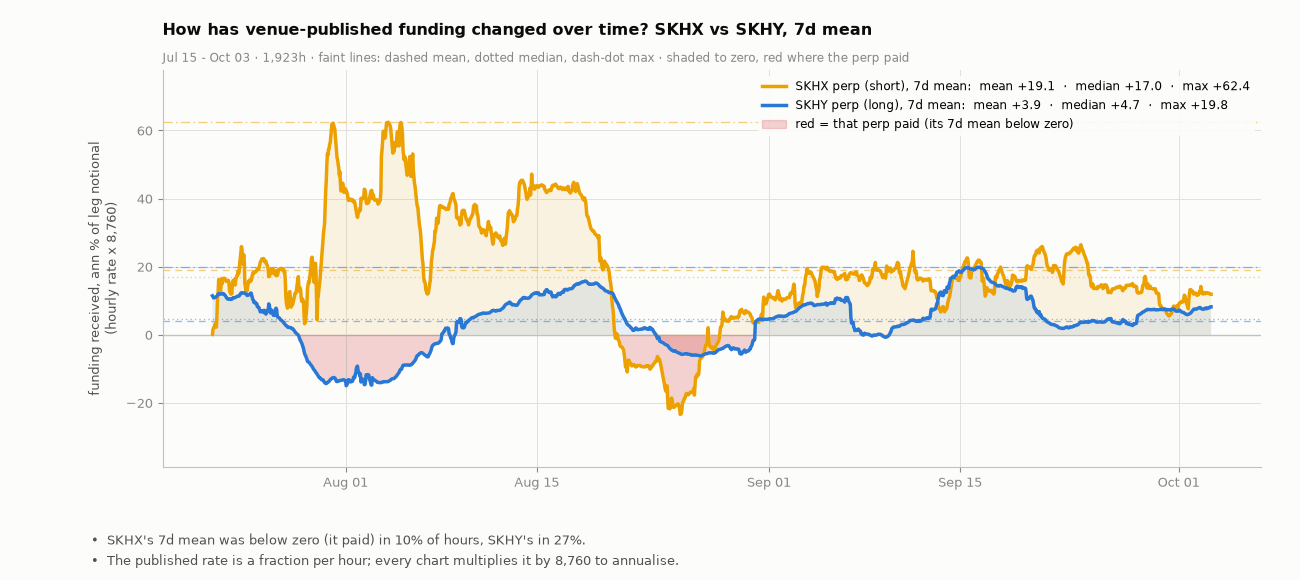

In [6]:
# ---- 1a. SKHX vs SKHY, 7d mean ----
a7, b7 = fA.rolling(168).mean(), fB.rolling(168).mean()
fig, ax = plt.subplots(figsize=(13, 5.8))
ax.plot(a7.index, a7, color=C_A, linewidth=2.5, zorder=4); ax.plot(b7.index, b7, color=C_B, linewidth=2.5, zorder=4)
va, vb = stat3(ax, a7, C_A), stat3(ax, b7, C_B)
ax.plot([], [], color=C_A, linewidth=2.5, label=tag("SKHX perp (short), 7d mean", va)); ax.plot([], [], color=C_B, linewidth=2.5, label=tag("SKHY perp (long), 7d mean", vb))
ax.axhline(0, color=AXIS, linewidth=1, zorder=1)
for s_, col_ in ((a7.dropna(), C_A), (b7.dropna(), C_B)):
    ax.fill_between(s_.index, s_, 0, where=(s_ >= 0), interpolate=True, color=col_, alpha=0.10, linewidth=0, zorder=1)
    ax.fill_between(s_.index, s_, 0, where=(s_ < 0), interpolate=True, color=CRIT, alpha=0.22, linewidth=0, zorder=1)
paid_a, paid_b = float(a7.dropna().lt(0).mean() * 100), float(b7.dropna().lt(0).mean() * 100)
ax.fill_between([], [], color=CRIT, alpha=0.22, label="red = that perp paid (its 7d mean below zero)")
yfit(ax, [a7.dropna(), b7.dropna()], pad=0.18); ax.set_ylabel("funding received, ann % of leg notional\n(hourly rate x 8,760)")
ax.legend(loc="upper right", fontsize=8.5, **LEG); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ask(ax, "How has venue-published funding changed over time? SKHX vs SKHY, 7d mean", f"{WS} · {KEY} · shaded to zero, red where the perp paid")
finish(fig, [f"SKHX's 7d mean was below zero (it paid) in {paid_a:.0f}% of hours, SKHY's in {paid_b:.0f}%.",
             "The published rate is a fraction per hour; every chart multiplies it by 8,760 to annualise."], top=0.88, right=0.97)
figstyle.show(fig, "fig:s2-funding-7d", FIGURES)
ST2["funding7"] = {"A": va, "B": vb, "paid_A_pct": paid_a, "paid_B_pct": paid_b}

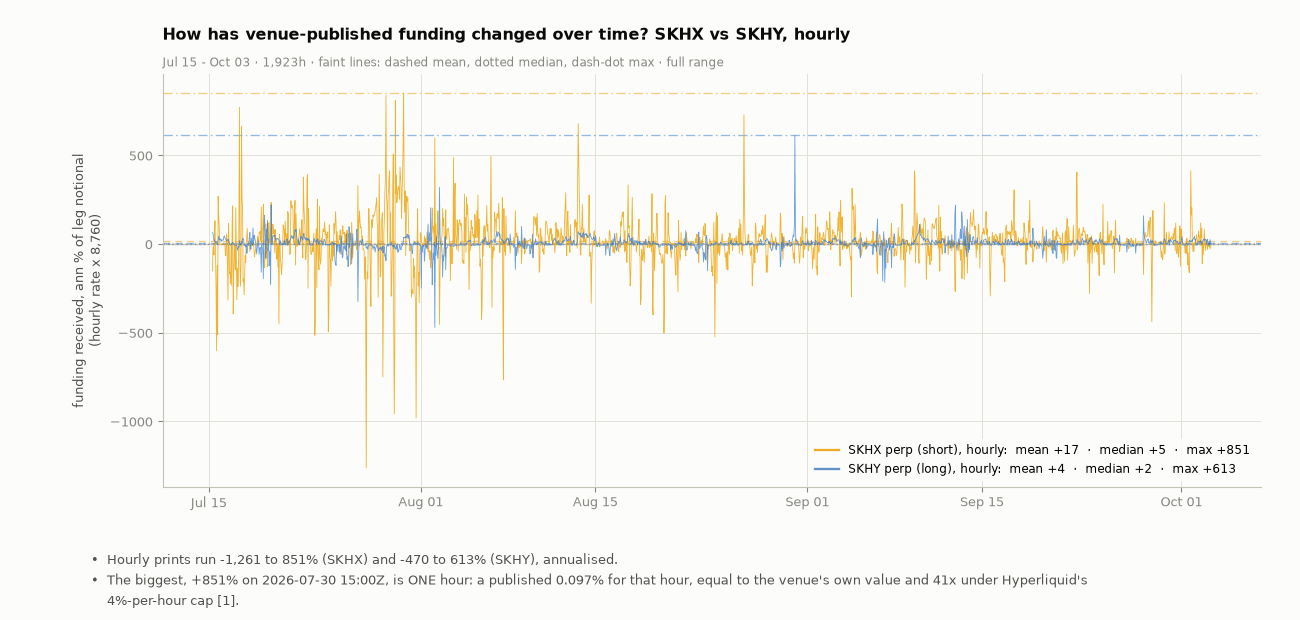

In [7]:
# ---- 1b. hourly ----
fig, ax = plt.subplots(figsize=(13, 6.2))
ax.plot(fA.index, fA, color=C_A, linewidth=0.6, alpha=0.8, zorder=3); ax.plot(fB.index, fB, color=C_B, linewidth=0.6, alpha=0.7, zorder=3)
ha, hb = stat3(ax, fA.iloc[1:], C_A), stat3(ax, fB.iloc[1:], C_B)
ax.plot([], [], color=C_A, linewidth=1.6, label=tag("SKHX perp (short), hourly", ha, 0)); ax.plot([], [], color=C_B, linewidth=1.6, label=tag("SKHY perp (long), hourly", hb, 0))
ax.axhline(0, color=AXIS, linewidth=1, zorder=1)
yfit(ax, [fA, fB], pad=0.05); ax.set_ylabel("funding received, ann % of leg notional\n(hourly rate x 8,760)")
ax.legend(loc="lower right", fontsize=8.5, **LEG); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ask(ax, "How has venue-published funding changed over time? SKHX vs SKHY, hourly", f"{WS} · {KEY} · full range")
finish(fig, [f"Hourly prints run {fA.min():,.0f} to {fA.max():,.0f}% (SKHX) and {fB.min():,.0f} to {fB.max():,.0f}% (SKHY), annualised.",
             f"The biggest, +{UC['annualised_pct']:,.0f}% on {UC['hour'][:16]}Z, is ONE hour: a published {UC['pct_per_hour']:.3f}% for that hour, equal to the venue's own value and {UC['times_under_cap']:.0f}x under Hyperliquid's 4%-per-hour cap [1]."], top=0.88, right=0.97)
figstyle.show(fig, "fig:s2-funding-hourly", FIGURES)
ST2["funding_hourly"] = {"A": ha, "B": hb}

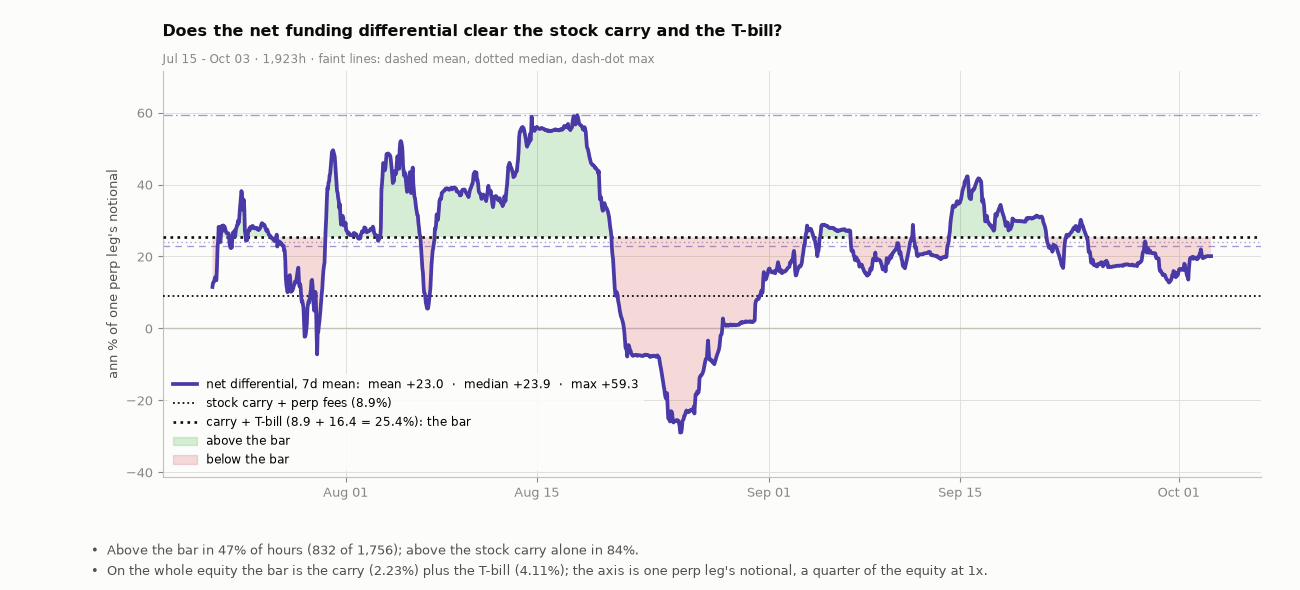

In [8]:
# ---- 2. Does the net differential clear the stock carry AND the T-bill? (7d mean) ----
fig, ax = plt.subplots(figsize=(13, 5.9))
d7c = d_7.dropna()
ax.plot(d7c.index, d7c, color=C_NET, linewidth=2.7, zorder=4)
vn = stat3(ax, d7c, C_NET)
ax.plot([], [], color=C_NET, linewidth=2.7, label=tag("net differential, 7d mean", vn))
ax.axhline(CARRY_LEG, color=INK, linestyle=":", linewidth=1.3, zorder=3, label=f"stock carry + perp fees ({CARRY_LEG:.1f}%)")
ax.axhline(BAR_LEG, color=INK, linestyle=":", linewidth=1.9, zorder=3, label=f"carry + T-bill ({CARRY_LEG:.1f} + {HURDLE_LEG:.1f} = {BAR_LEG:.1f}%): the bar")
ax.axhline(0, color=AXIS, linewidth=1, zorder=2)
ax.fill_between(d7c.index, d7c, BAR_LEG, where=(d7c >= BAR_LEG), interpolate=True, color=GOOD, alpha=0.16, linewidth=0, zorder=2)
ax.fill_between(d7c.index, d7c, BAR_LEG, where=(d7c < BAR_LEG), interpolate=True, color=CRIT, alpha=0.18, linewidth=0, zorder=2)
ax.fill_between([], [], color=GOOD, alpha=0.16, label="above the bar"); ax.fill_between([], [], color=CRIT, alpha=0.18, label="below the bar")
yfit(ax, [d7c, pd.Series([BAR_LEG])], pad=0.14); ax.set_ylabel("ann % of one perp leg's notional")
ax.legend(loc="lower left", fontsize=8.5, **LEG); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
n_up, n_all = int(d7c.gt(BAR_LEG).sum()), int(len(d7c)); n_carry = int(d7c.gt(CARRY_LEG).sum())
share = n_up / n_all * 100
ask(ax, "Does the net funding differential clear the stock carry and the T-bill?", f"{WS} · {KEY}")
finish(fig, [f"Above the bar in {share:.0f}% of hours ({n_up:,} of {n_all:,}); above the stock carry alone in {n_carry / n_all * 100:.0f}%.",
             f"On the whole equity the bar is the carry ({CARRY_LEG / LEGS_PER_EQ:.2f}%) plus the T-bill ({HURDLE_EQ:.2f}%); the axis is one perp leg's notional, a quarter of the equity at 1x."], top=0.88, right=0.97)
figstyle.show(fig, "fig:s2-net-vs-bar", FIGURES)
ST2["net_vs_bar"] = {"share_above": share, "share_carry": n_carry / n_all * 100, "hours_above": n_up, "hours_all": n_all, "stats": vn}

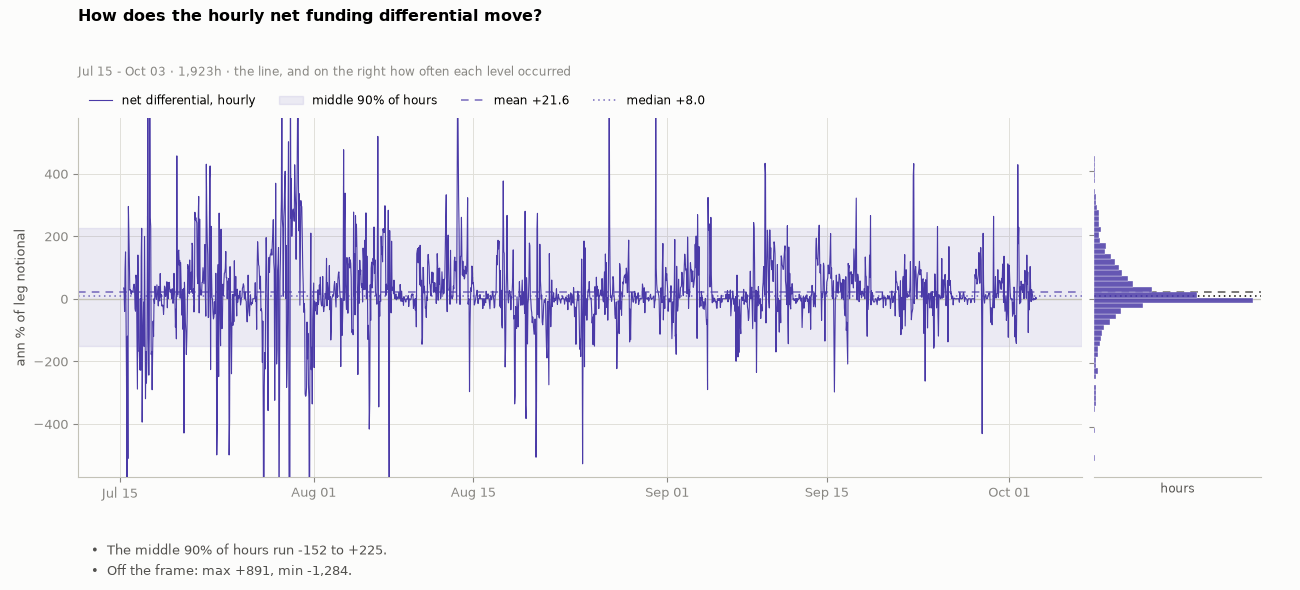

In [9]:
# ---- 3. hourly net differential and its distribution beside it ----
dn = d_h.iloc[1:]
lo_, hi_ = np.nanpercentile(dn, 0.5), np.nanpercentile(dn, 99.5); p5, p95 = np.nanpercentile(dn, 5), np.nanpercentile(dn, 95)
fig = plt.figure(figsize=(13, 5.9))
bm = figstyle.bullets(fig, [f"The middle 90% of hours run {p5:+.0f} to {p95:+.0f}.", f"Off the frame: max {dn.max():+,.0f}, min {dn.min():+,.0f}."])
gs = fig.add_gridspec(1, 2, width_ratios=[6, 1], wspace=0.02, left=0.06, right=0.97, top=0.80, bottom=bm + 0.5 / 5.9)
ax, axh = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])
ax.plot(dn.index, dn, color=C_NET, linewidth=0.8, zorder=3, label="net differential, hourly")
ax.axhspan(p5, p95, color=C_NET, alpha=0.09, zorder=1, label="middle 90% of hours")
ax.axhline(dn.mean(), color=C_NET, linewidth=1.1, linestyle=LSf["mean"], alpha=0.75, zorder=2, label=f"mean {dn.mean():+.1f}")
ax.axhline(dn.median(), color=C_NET, linewidth=1.1, linestyle=LSf["median"], alpha=0.75, zorder=2, label=f"median {dn.median():+.1f}")
ax.axhline(0, color=AXIS, linewidth=1, zorder=1)
ax.set_ylim(lo_ - (hi_ - lo_) * 0.06, hi_ + (hi_ - lo_) * 0.06); ax.set_ylabel("ann % of leg notional")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d")); ax.legend(loc="lower left", bbox_to_anchor=(0.0, 1.0), ncol=4, fontsize=8.5, frameon=False)
axh.hist(dn[(dn >= lo_) & (dn <= hi_)], bins=60, orientation="horizontal", color=C_NET, alpha=0.85, edgecolor=SURF, linewidth=0.3, zorder=3)
axh.axhline(dn.mean(), color=INK2, linewidth=1.1, linestyle=LSf["mean"]); axh.axhline(dn.median(), color=INK, linewidth=1.1, linestyle=LSf["median"])
axh.axhline(0, color=AXIS, linewidth=1); axh.set_xticks([]); axh.tick_params(labelleft=False); axh.grid(False); axh.set_xlabel("hours", fontsize=8.5)
axh.spines["left"].set_visible(False)
figstyle_ask = figstyle.NAMES  # (kept for symmetry with the pair script)
fig_ask(fig, "How does the hourly net funding differential move?", f"{WS} · the line, and on the right how often each level occurred", 0.80)
figstyle.show(fig, "fig:s2-net-hourly", FIGURES)
ST2["net_hourly"] = {"min": float(dn.min()), "max": float(dn.max()), "mean": float(dn.mean()), "median": float(dn.median()), "p5": float(p5), "p95": float(p95)}

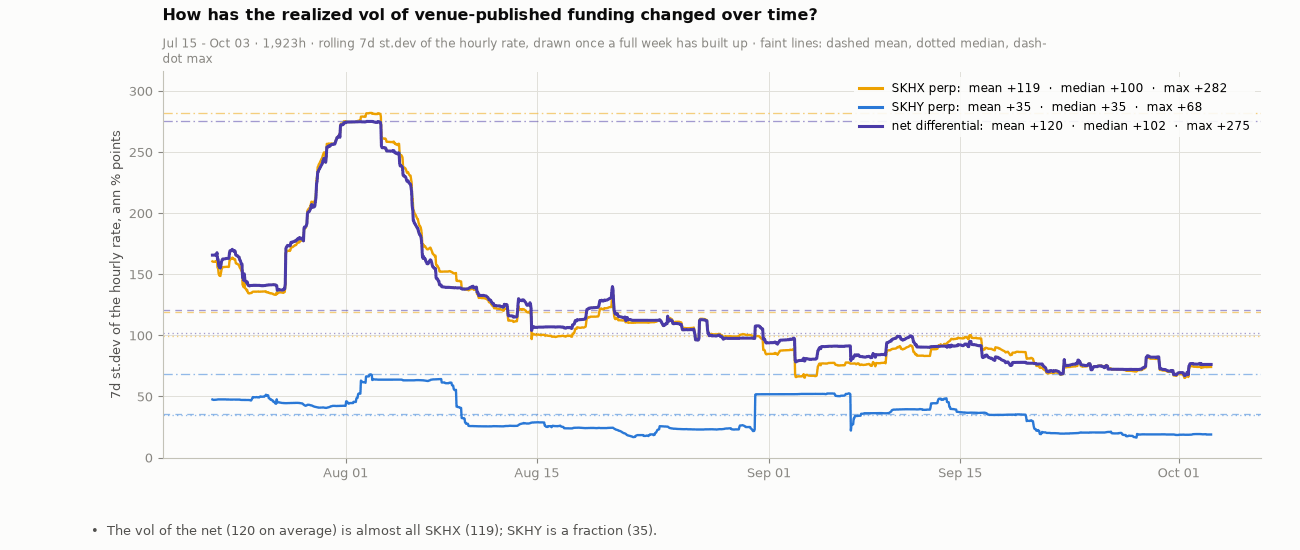

In [10]:
# ---- 4. realized vol of funding ----
fig, ax = plt.subplots(figsize=(13, 5.5))
V, VS = {}, {}
for s, col, lab in ((fA, C_A, "SKHX perp"), (fB, C_B, "SKHY perp"), (d_h, C_NET, "net differential")):
    v7 = s.rolling(168).std(); V[lab] = v7
    ax.plot(v7.index, v7, color=col, linewidth=2.2 if lab == "net differential" else 1.7, zorder=4 if lab == "net differential" else 3)
    VS[lab] = stat3(ax, v7, col); ax.plot([], [], color=col, linewidth=2.2, label=tag(lab, VS[lab], 0))
ax.set_ylabel("7d st.dev of the hourly rate, ann % points"); ax.set_ylim(0, float(max(v.max() for v in V.values())) * 1.12)
ax.legend(loc="upper right", fontsize=8.5, **LEG); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ask(ax, "How has the realized vol of venue-published funding changed over time?", f"{WS} · rolling 7d st.dev of the hourly rate, drawn once a full week has built up · {KEY}")
finish(fig, [f"The vol of the net ({VS['net differential']['mean']:,.0f} on average) is almost all SKHX ({VS['SKHX perp']['mean']:,.0f}); SKHY is a fraction ({VS['SKHY perp']['mean']:,.0f})."], top=0.87, right=0.97)
figstyle.show(fig, "fig:s2-funding-vol", FIGURES)
ST2["funding_vol"] = VS

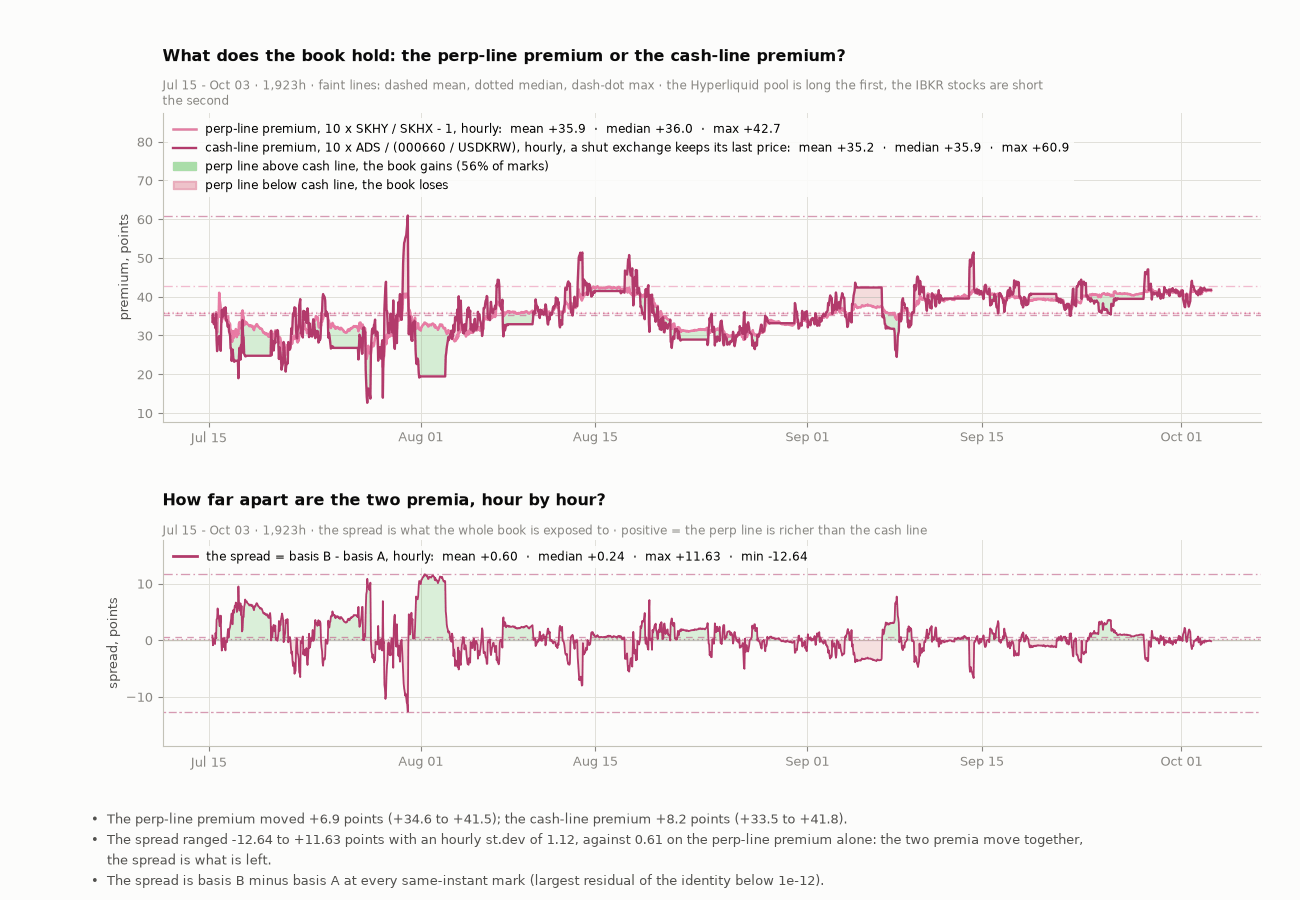

In [11]:
# ---- 5a. the two premia (perp line, cash line) and the spread the book holds ----
IDXT = {t: i for i, t in enumerate(res["series"]["time"])}
t0_, t1_ = res["series"]["time"][0], res["series"]["time"][-1]
hour_of = lambda s_: min((t for t in res["series"]["time"] if t - HOUR < s_ <= t), default=None)
CX, CY, PY, DY, RESID, BAL, BBL = [], [], [], [], [], [], []
RT_ = {r_["time"]: r_ for r_ in rows}
for i_, st in enumerate(res["series"]["time"]):
    kpx, a_, f_ = asof(MKH, st), asof(MAH, st), asof(MFH, st)          # the last hourly print of each cash line, kept constant while its exchange is shut
    rr_ = RT_[st]                                                       # the REAL perp prices: the engine series freezes the late perp before its hedge fills
    pa_, pb_ = rr_["A_perp"], rr_["B_perp"]
    if not (kpx and a_ and f_ and pa_ and pb_):
        continue
    kusd_ = kpx / f_
    cp_ = 10.0 * a_ / kusd_ * 100.0 - 100.0
    pp_ = 10.0 * pb_ / pa_ * 100.0 - 100.0
    bA_si, bB_si = pa_ / kusd_ * 100.0 - 100.0, pb_ / a_ * 100.0 - 100.0
    RESID.append(abs(((1 + bB_si / 100) / (1 + bA_si / 100) - (1 + pp_ / 100) / (1 + cp_ / 100)) * 100))
    CX.append(pd.Timestamp(st, unit="ms", tz="UTC")); CY.append(cp_); PY.append(pp_); DY.append(((1 + pp_ / 100) / (1 + cp_ / 100) - 1) * 100); BAL.append(bA_si); BBL.append(bB_si)
assert max(RESID) < 1e-12, max(RESID)          # the identity: spread = basis B vs basis A, exactly, at every hour
bA, bB = pd.Series(BAL, index=CX), pd.Series(BBL, index=CX)
nb_ = ((1 + bB / 100) / (1 + bA / 100) - 1) * 100
cp_s, pp_s, sp_s = pd.Series(CY, index=CX), pd.Series(PY, index=CX), pd.Series(DY, index=CX)
fig, (b0, b1) = plt.subplots(2, 1, figsize=(13, 9.0), sharex=False, gridspec_kw={"height_ratios": [3, 2]})
b0.fill_between(CX, PY, CY, where=(np.array(PY) >= np.array(CY)), color=GOOD, alpha=0.16, lw=0, zorder=1)
b0.fill_between(CX, PY, CY, where=(np.array(PY) < np.array(CY)), color=CRIT, alpha=0.16, lw=0, zorder=1)
b0.plot(prem.index, prem, color=C_PREM, linewidth=1.8, zorder=4, label=tag("perp-line premium, 10 x SKHY / SKHX - 1, hourly", {"mean": prem.mean(), "median": prem.median(), "max": prem.max()}, 1))
b0.plot(CX, CY, color=C_PREM_DK, linewidth=1.7, zorder=5, label=tag("cash-line premium, 10 x ADS / (000660 / USDKRW), hourly, a shut exchange keeps its last price", {"mean": cp_s.mean(), "median": cp_s.median(), "max": cp_s.max()}, 1))
stat3(b0, prem, C_PREM); stat3(b0, cp_s, C_PREM_DK)
b0.axhline(0, color=AXIS, linewidth=1); b0.set_ylabel("premium, points")
b0.fill_between([], [], color=GOOD, alpha=0.3, label=f"perp line above cash line, the book gains ({np.mean(np.array(DY) > 0) * 100:.0f}% of marks)")
b0.fill_between([], [], color=CRIT, alpha=0.3, label="perp line below cash line, the book loses")
lo_, hi_ = min(min(CY), float(prem.min())), max(max(CY), float(prem.max()))
b0.set_ylim(lo_ - (hi_ - lo_) * 0.10, hi_ + (hi_ - lo_) * 0.55); b0.legend(loc="upper left", fontsize=8.3, **LEG)
b0.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ask(b0, "What does the book hold: the perp-line premium or the cash-line premium?", f"{WS} · {KEY} · the Hyperliquid pool is long the first, the IBKR stocks are short the second")
sd = nb_
b1.plot(sd.index, sd, color=C_PREM_DK, linewidth=1.3, zorder=4)
vs_ = stat3(b1, sd, C_PREM_DK, with_min=True)
b1.plot([], [], color=C_PREM_DK, linewidth=2.0, label=tag("the spread = basis B - basis A, hourly", vs_, 2))
b1.axhline(0, color=AXIS, linewidth=1, zorder=1); b1.set_ylabel("spread, points")
b1.fill_between(sd.index, sd, 0, where=(sd >= 0), interpolate=True, color=GOOD, alpha=0.14, linewidth=0, zorder=1)
b1.fill_between(sd.index, sd, 0, where=(sd < 0), interpolate=True, color=CRIT, alpha=0.14, linewidth=0, zorder=1)
yfit(b1, [sd], pad=0.25); b1.legend(loc="upper left", fontsize=8.5, **LEG); b1.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ask(b1, "How far apart are the two premia, hour by hour?", f"{WS} · the spread is what the whole book is exposed to · positive = the perp line is richer than the cash line")
dS, dP = sd.diff(), prem.diff()
finish(fig, [f"The perp-line premium moved {prem.iloc[-1] - P0:+.1f} points ({P0:+.1f} to {prem.iloc[-1]:+.1f}); the cash-line premium {CY[-1] - CY[0]:+.1f} points ({CY[0]:+.1f} to {CY[-1]:+.1f}).",
             f"The spread ranged {sd.min():+.2f} to {sd.max():+.2f} points with an hourly st.dev of {dS.std():.2f}, against {dP.std():.2f} on the perp-line premium alone: the two premia move together, the spread is what is left.",
             "The spread is basis B minus basis A at every same-instant mark (largest residual of the identity below 1e-12)."], top=0.875, hspace=0.46, right=0.97)
figstyle.show(fig, "fig:s2-premia", FIGURES)
ST2["premia"] = {"perp": {"start": float(P0), "end": float(prem.iloc[-1]), "mean": float(prem.mean())}, "cash": {"start": float(CY[0]), "end": float(CY[-1]), "mean": float(np.mean(CY))},
                   "spread": vs_, "spread_hourly_std": float(dS.std()), "perp_hourly_std": float(dP.std()), "share_with_book": float(np.mean(np.array(DY) > 0) * 100), "max_resid": float(max(RESID))}

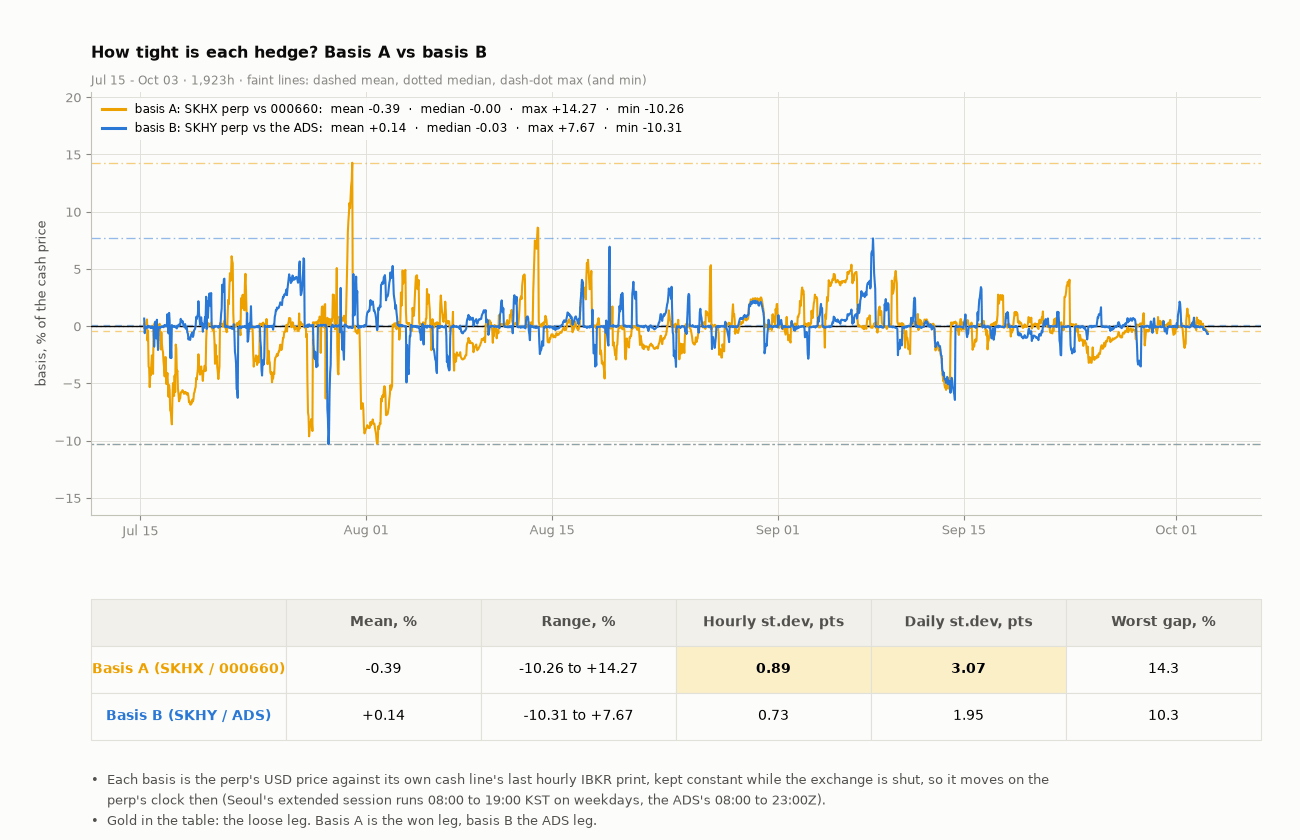

In [12]:
# ---- 5b. each hedge's own basis: SKHX perp vs 000660, SKHY perp vs the ADS ----
fig = plt.figure(figsize=(13, 8.4))
bm = figstyle.bullets(fig, ["Each basis is the perp's USD price against its own cash line's last hourly IBKR print, kept constant while the exchange is shut, so it moves on the perp's clock then (Seoul's extended session runs 08:00 to 19:00 KST on weekdays, the ADS's 08:00 to 23:00Z).",
                            "Gold in the table: the loose leg. Basis A is the won leg, basis B the ADS leg."])
gs = fig.add_gridspec(2, 1, height_ratios=[3.0, 1.0], hspace=0.30, left=0.07, right=0.97, top=0.89, bottom=bm + 0.02)
ax, axt = fig.add_subplot(gs[0]), fig.add_subplot(gs[1]); axt.axis("off")
ax.plot(bA.index, bA, color=C_A, linewidth=1.5, zorder=4); ax.plot(bB.index, bB, color=C_B, linewidth=1.5, zorder=4)
va_, vb_ = stat3(ax, bA, C_A, with_min=True), stat3(ax, bB, C_B, with_min=True)
ax.plot([], [], color=C_A, linewidth=2.2, label=tag("basis A: SKHX perp vs 000660", va_, 2)); ax.plot([], [], color=C_B, linewidth=2.2, label=tag("basis B: SKHY perp vs the ADS", vb_, 2))
ax.axhline(0, color=INK, linewidth=1, zorder=3); ax.set_ylabel("basis, % of the cash price"); ax.legend(loc="upper left", fontsize=8.5, **LEG)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d")); yfit(ax, [bA, bB], pad=0.25)
ask(ax, "How tight is each hedge? Basis A vs basis B", f"{WS} · {KEY} (and min)")
dbA, dbB = bA.diff(), bB.diff()
cells = [["Basis A (SKHX / 000660)", f"{bA.mean():+.2f}", f"{bA.min():+.2f} to {bA.max():+.2f}", f"{dbA.std():.2f}", f"{bA.diff(24).std():.2f}", f"{bA.abs().max():.1f}"],
         ["Basis B (SKHY / ADS)", f"{bB.mean():+.2f}", f"{bB.min():+.2f} to {bB.max():+.2f}", f"{dbB.std():.2f}", f"{bB.diff(24).std():.2f}", f"{bB.abs().max():.1f}"]]
tb = axt.table(cellText=cells, colLabels=["", "Mean, %", "Range, %", "Hourly st.dev, pts", "Daily st.dev, pts", "Worst gap, %"], cellLoc="center", loc="center", bbox=[0, 0, 1, 1])
tb.auto_set_font_size(False); tb.set_fontsize(10); figstyle.style_table(tb)
loose = 0 if bA.diff(24).std() >= bB.diff(24).std() else 1
for r_ in (1, 2):
    tb[(r_, 0)].set_text_props(weight="bold", color=(C_A if r_ == 1 else C_B)); tb[(r_, 0)]._loc = "left"
figstyle.gold(tb, loose + 1, 4); figstyle.gold(tb, loose + 1, 3)
figstyle.show(fig, "fig:s2-bases", FIGURES)
ST2["bases"] = {"A": {"mean": float(bA.mean()), "min": float(bA.min()), "max": float(bA.max()), "h_std": float(dbA.std()), "d_std": float(bA.diff(24).std())},
                  "B": {"mean": float(bB.mean()), "min": float(bB.min()), "max": float(bB.max()), "h_std": float(dbB.std()), "d_std": float(bB.diff(24).std())}}

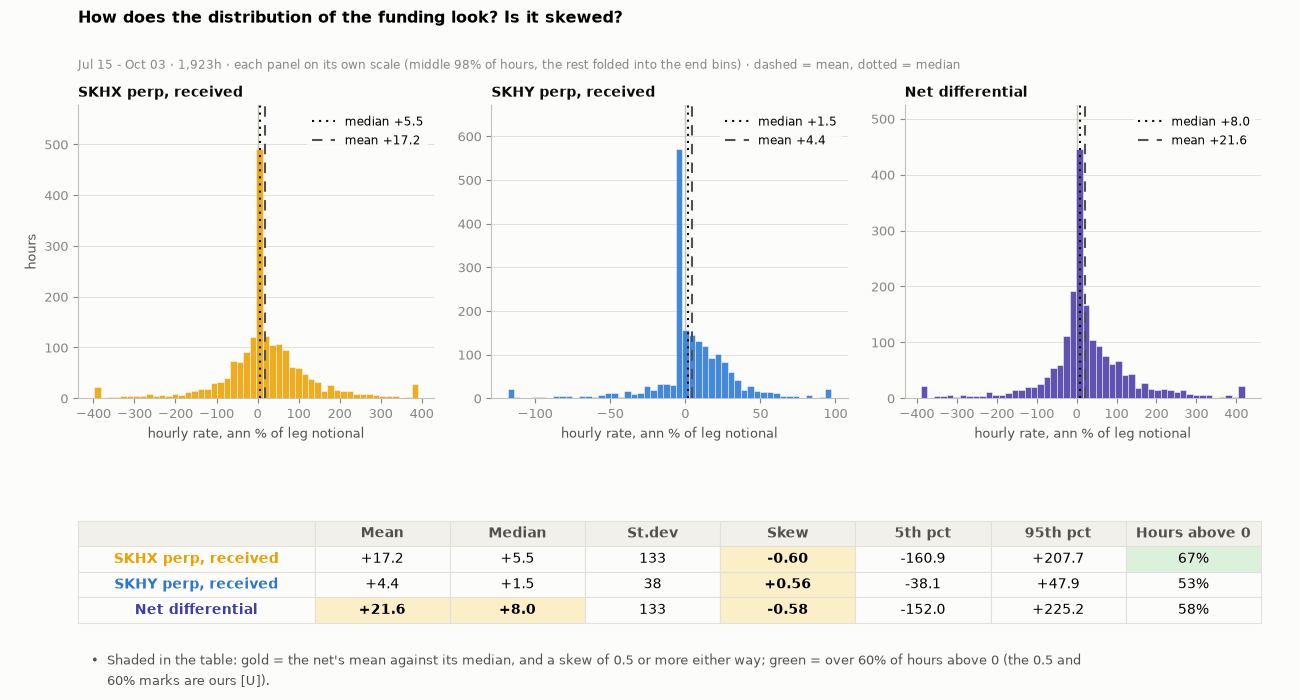

In [13]:
# ---- 6. distribution: three histograms, ONE table ----
from fundplat.quant.crypto.backtest import hip3_pair as HP
rows_pers = rows
PS = HP.funding_persistence(rows_pers, "short_a")
SER = ((fA.iloc[1:], C_A, "SKHX perp, received"), (fB.iloc[1:], C_B, "SKHY perp, received"), (dn, C_NET, "Net differential"))
fig = plt.figure(figsize=(13, 7.0))
bm = figstyle.bullets(fig, ["Shaded in the table: gold = the net's mean against its median, and a skew of 0.5 or more either way; green = over 60% of hours above 0 (the 0.5 and 60% marks are ours [U])."])
gs = fig.add_gridspec(2, 3, height_ratios=[3.3, 1.15], hspace=0.62, wspace=0.16, left=0.06, right=0.97, top=0.85, bottom=bm + 0.02)
axs = [fig.add_subplot(gs[0, i]) for i in range(3)]
axt = fig.add_subplot(gs[1, :]); axt.axis("off")
D = {}
for a_, (s_, col, lab) in zip(axs, SER):
    lo_, hi_ = np.nanpercentile(s_, 1), np.nanpercentile(s_, 99)
    a_.hist(s_.clip(lo_, hi_), bins=np.linspace(lo_, hi_, 51), color=col, alpha=0.88, edgecolor=SURF, linewidth=0.4, zorder=3)
    a_.axvline(0, color=AXIS, linewidth=1, zorder=2)
    a_.axvline(s_.median(), color=INK, linestyle=LSf["median"], linewidth=1.5, zorder=5, label=f"median {s_.median():+.1f}")
    a_.axvline(s_.mean(), color=INK2, linestyle=LSf["mean"], linewidth=1.5, zorder=5, label=f"mean {s_.mean():+.1f}")
    a_.set_title(lab, fontsize=10, loc="left", pad=6); a_.set_xlabel("hourly rate, ann % of leg notional"); a_.legend(loc="upper right", fontsize=8.5, **LEG)
    a_.grid(axis="x", visible=False); a_.set_ylim(top=a_.get_ylim()[1] * 1.12)
    D[lab] = {"mean": s_.mean(), "median": s_.median(), "std": s_.std(), "skew": s_.skew(), "p5": np.nanpercentile(s_, 5), "p95": np.nanpercentile(s_, 95), "min": s_.min(), "max": s_.max(), "pos": float((s_ > 0).mean() * 100)}
axs[0].set_ylabel("hours")
cols = ["", "Mean", "Median", "St.dev", "Skew", "5th pct", "95th pct", "Hours above 0"]
cells = [[lab, f"{d['mean']:+.1f}", f"{d['median']:+.1f}", f"{d['std']:,.0f}", f"{d['skew']:+.2f}", f"{d['p5']:+.1f}", f"{d['p95']:+.1f}", f"{d['pos']:.0f}%"] for lab, d in D.items()]
tb = figstyle.put_table(axt, cells, cols, size=10, first=0.2)
for r_ in (1, 2, 3):
    d_ = list(D.values())[r_ - 1]
    tb[(r_, 0)].set_text_props(weight="bold", color=SER[r_ - 1][1]); tb[(r_, 0)]._loc = "left"
    if abs(d_["skew"]) >= 0.5: figstyle.gold(tb, r_, 4)
    if d_["pos"] > 60: figstyle.tint(tb, r_, 7, "green")
figstyle.gold(tb, 3, 1); figstyle.gold(tb, 3, 2)
fig_ask(fig, "How does the distribution of the funding look? Is it skewed?", f"{WS} · each panel on its own scale (middle 98% of hours, the rest folded into the end bins) · dashed = mean, dotted = median", 0.85)
figstyle.show(fig, "fig:s2-distribution", FIGURES)
ST2["dist"] = D
ST2["persist"] = {"half_life_h": float(PS["half_life_h"]), "acf24": float(PS["acf"][24])}

## S3 · Core result - Base test

Does it pay at 1x, with nothing amplifying it?

In [14]:
LSf = figstyle.LS

r_ = res
DAY = DAYS_[BOOK]
DB = DBAS[BOOK]
yrs = r_["days"] / 365.0
WSH = f"{df.index[0]:%b %d} - {df.index[-1]:%b %d} · {len(df):,}h · 1x cross · always-hold · costs on"
COSTS_USD = r_["financing"] + r_["stock_costs"] + r_["perp_fees"] + r_["perp_liq_fees"] - r_["dividends"]      # everything the gate metric nets off the funding
CARRY_USD = carry_usd(r_)
assert abs(CARRY_USD - (r_["funding_net"] - COSTS_USD)) < 1e-6
ST3 = {"hours": int(r_["n_hours"]), "total": r_["total_pnl"],      # "total", "basis", "basis_A" and "basis_B" here are the engine's CLOSE-marked P&L; the fair-value ones are total_fv and basis_fv (set below)
 "funding": r_["funding_net"], "costs": COSTS_USD, "gate_usd": CARRY_USD, "gate_ann": carry_ann(r_),
         "basis": r_["net_basis_pnl"], "basis_A": BAS[BOOK]["A"], "basis_B": BAS[BOOK]["B"], "financing": r_["financing"], "stock_costs": r_["stock_costs"],
         "perp_fees": r_["perp_fees"] + r_["perp_liq_fees"], "dividends": r_["dividends"], "ann_equity": r_["ann_pct_equity"], "days": r_["days"]}
DD_CUT = -1.0

eq = (EQUITY + num(df["total_pnl"])) / 1e6
uw = (eq / eq.cummax() - 1) * 100
assert abs(uw.min() / 100 - r_["max_drawdown_equity"]) < 1e-6, (uw.min(), r_["max_drawdown_equity"])
eq_fv = (EQUITY + num(df["total_pnl_fv"])) / 1e6
uw_fv = (eq_fv / eq_fv.cummax() - 1) * 100
_cap = (r_["capital"] + num(df["total_pnl_fv"])); assert abs((_cap / _cap.cummax() - 1).min() - r_["max_drawdown_fv"]) < 1e-6      # the engine's own figure is on `capital`; the chart is on the USD 1M of equity, as the close-marked one is
STATS_FV_ENGINE = float(r_["max_drawdown_fv"] * 100)
# ---- the marks, named: the book's return is the FAIR-VALUE one (each stock leg re-struck on every hourly IBKR print); the close-marked figure prices two clocks and is named wherever it is shown ----
FV_TOTAL = float((eq_fv.iloc[-1] - 1.0) * 1e6)                  # USD, derived from the fair-value equity curve
assert abs(FV_TOTAL - r_["total_pnl_fv"]) < 1e-3, (FV_TOTAL, r_["total_pnl_fv"])
FV_ANN = FV_TOTAL / EQUITY * 100.0 / r_["days"] * 365.0         # the book's annualised return on equity, fair-value marked
FV_BASIS = FV_TOTAL - CARRY_USD                                 # the basis P&L on the fair-value mark: the total less funding net of every carry
fv_ann = lambda x_: x_["total_pnl_fv"] / EQUITY * 100.0 / x_["days"] * 365.0     # the same reading for any engine run
assert abs(fv_ann(r_) - FV_ANN) < 1e-6, (fv_ann(r_), FV_ANN)
DAYFV = daily_cum(pd.Series(r_["series"]["total_pnl_fv"], index=df.index, dtype=float))     # daily fair-value P&L, USD
assert abs(DAYFV.sum() - r_["total_pnl_fv"]) < 1e-6, (DAYFV.sum(), r_["total_pnl_fv"])
ST3["ann_equity"], ST3["ann_equity_close"] = FV_ANN, r_["ann_pct_equity"]        # ann_equity is the FAIR-VALUE return everywhere downstream; the close-marked one is named where used
ST3["total_fv"], ST3["basis_fv"] = FV_TOTAL, FV_BASIS
# the episodes are read on the FAIR-VALUE mark (the book); the close-marked line is what a statement prints, two clocks in one number
idx = eq_fv.index
SPELLS = ST.drawdown_spells(list(eq_fv.values), list(idx))          # fundplat's own spells: peak, trough, first stamp back at the peak, depth, days, recovery days
eps = [{"peak": idx[s_["peak_i"]], "trough": idx[s_["trough_i"]], "end": (idx[s_["end_i"]] if s_["end_i"] is not None else idx[-1]), "recovered": s_["end_i"] is not None,
        "depth": float(s_["depth"]) * 100.0, "days_recover": (float(s_["recovery_days"]) if s_["recovery_days"] is not None else (idx[-1] - idx[s_["trough_i"]]).total_seconds() / 86400)} for s_ in SPELLS]
assert abs(min(e_["depth"] for e_ in eps) - uw_fv.min()) < 1e-9, (min(e_["depth"] for e_ in eps), uw_fv.min())      # the deepest spell IS the max drawdown
eps.sort(key=lambda e: e["depth"])
EP = [e for e in eps if e["depth"] <= DD_CUT]
for k, e in enumerate(EP, 1):
    e["rank"] = k
    e["days_down"] = (e["trough"] - e["peak"]).total_seconds() / 86400
LONGEST_DD_DAYS = float(ST.max_dd_days(list(eq_fv.values), list(idx)))        # the longest time under a previous peak, peak to its recovery stamp (or to the last stamp)
RECOVERY_DEEPEST = ST.recovery_days(list(eq_fv.values), list(idx))            # how long the deepest spell took to win back its peak (NaN: not yet)

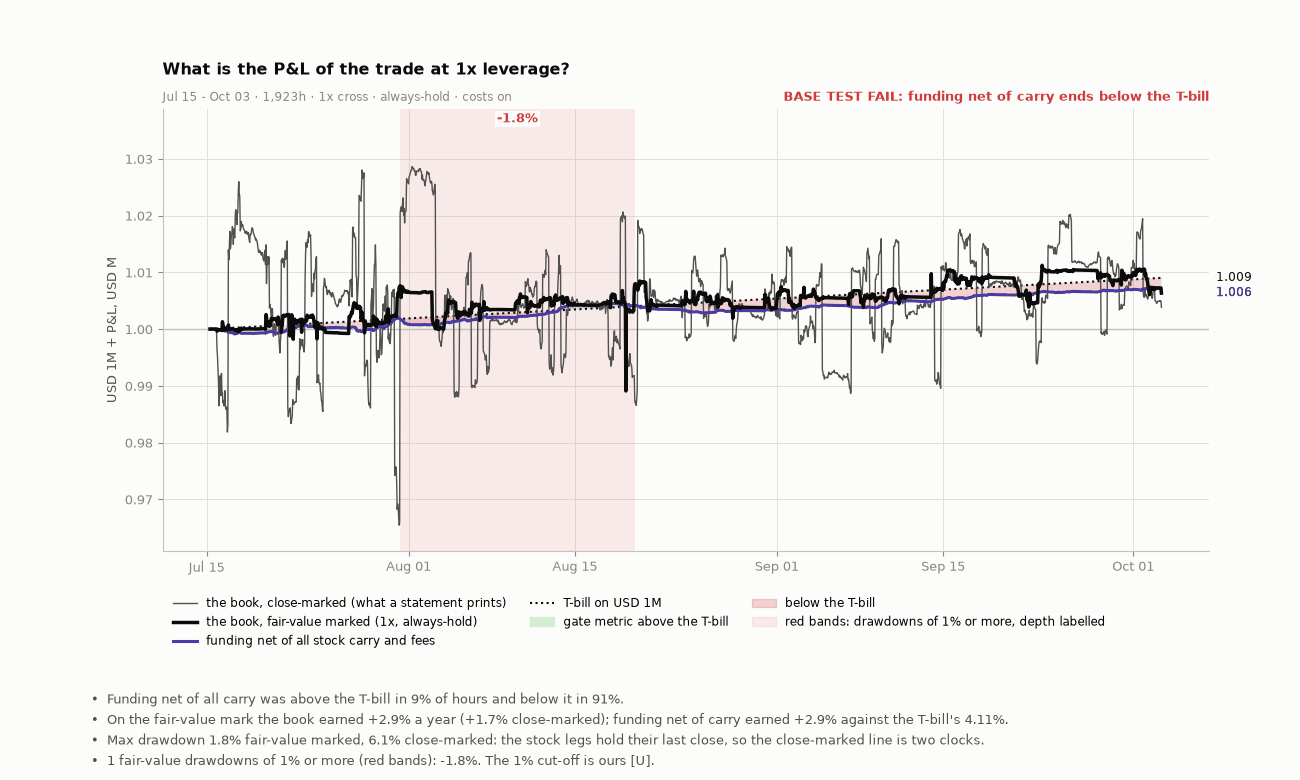

In [15]:
# ---- 1. What is the P&L of the trade at 1x leverage? the book, the gate metric (funding net of all carry), the T-bill ----
gate_line = (EQUITY + num(df["cum_funding_net"]) - num(df["cum_financing"]) - num(df["cum_stock_costs"]) - num(df["cum_perp_fees"]) + num(df["cum_dividends"])) / 1e6
tbill = pd.Series(EQUITY * (1 + p1.hurdle_ann * np.asarray((df.index - df.index[0]).total_seconds()) / (365 * 86400)) / 1e6, index=df.index)
share_up = float((gate_line >= tbill).mean() * 100)
G1a = bool(gate_line.iloc[-1] > tbill.iloc[-1])
H1 = 7.8
fig, ax = plt.subplots(figsize=(13, H1))
for e in EP:
    ax.axvspan(e["peak"], e["end"], color=CRIT, alpha=0.09, linewidth=0, zorder=1)
ax.plot(df.index, eq, color=INK2, linewidth=1.0, zorder=4, label="the book, close-marked (what a statement prints)")
ax.plot(df.index, eq_fv, color=INK, linewidth=2.5, zorder=5, label="the book, fair-value marked (1x, always-hold)")
ax.plot(df.index, gate_line, color=C_NET, linewidth=2.2, zorder=4, label="funding net of all stock carry and fees")
ax.plot(df.index, tbill, color=INK, linewidth=1.5, linestyle=":", zorder=3, label=f"T-bill on {usdm(EQUITY)}")
ax.fill_between(df.index, gate_line, tbill, where=(gate_line >= tbill), interpolate=True, color=GOOD, alpha=0.16, linewidth=0, zorder=2)
ax.fill_between(df.index, gate_line, tbill, where=(gate_line < tbill), interpolate=True, color=CRIT, alpha=0.22, linewidth=0, zorder=2)
ax.axhline(1.0, color=AXIS, linewidth=1, zorder=1)
ylo, yhi = ax.get_ylim(); ax.set_ylim(ylo - (yhi - ylo) * 0.02, yhi + (yhi - ylo) * 0.10)
for k, e in enumerate(EP):
    xm = e["peak"] + (e["end"] - e["peak"]) / 2
    ax.text(xm, yhi + (yhi - ylo) * (0.075 if k % 2 == 0 else 0.035), f"{e['depth']:.1f}%", ha="center", va="center", fontsize=9, color=CRIT, fontweight="bold", bbox=dict(facecolor=SURF, edgecolor="none", pad=1.2), zorder=7)
for s_, c_ in ((eq_fv, INK), (gate_line, C_NET), (tbill, INK)):
    ax.annotate(f" {s_.iloc[-1]:.3f}", xy=(1.003, s_.iloc[-1]), xycoords=("axes fraction", "data"), color=c_, fontsize=8.5, va="center", annotation_clip=False)
ax.fill_between([], [], color=GOOD, alpha=0.16, label="gate metric above the T-bill"); ax.fill_between([], [], color=CRIT, alpha=0.22, label="below the T-bill")
ax.fill_between([], [], color=CRIT, alpha=0.09, label="red bands: drawdowns of 1% or more, depth labelled")
ax.text(1.0, 1.012, ("BASE TEST PASS: funding net of carry ends above the T-bill" if G1a else "BASE TEST FAIL: funding net of carry ends below the T-bill"), transform=ax.transAxes, ha="right", va="bottom", color=(GOOD if G1a else CRIT), fontsize=9.5, fontweight="bold")
ax.set_ylabel("USD 1M + P&L, USD M"); ax.legend(loc="upper left", bbox_to_anchor=(0.0, -0.08), ncol=3, fontsize=8.5, frameon=False); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ask(ax, "What is the P&L of the trade at 1x leverage?", WSH)
bm = figstyle.bullets(fig, [f"Funding net of all carry was above the T-bill in {share_up:.0f}% of hours and below it in {100 - share_up:.0f}%.",
                            f"On the fair-value mark the book earned {FV_ANN:+.1f}% a year ({r_['ann_pct_equity']:+.1f}% close-marked); funding net of carry earned {carry_ann(r_):+.1f}% against the T-bill's {HURDLE_PCT:.2f}%.",
                            f"Max drawdown {abs(uw_fv.min()):.1f}% fair-value marked, {abs(r_['max_drawdown_equity']) * 100:.1f}% close-marked: the stock legs hold their last close, so the close-marked line is two clocks.",
                            f"{len(EP)} fair-value drawdowns of 1% or more (red bands): " + (", ".join(f"{e['depth']:.1f}%" for e in EP) or "none") + ". The 1% cut-off is ours [U]."])
plt.subplots_adjust(top=0.86, right=0.93, bottom=bm + 1.25 / H1)
figstyle.show(fig, "fig:s3-equity", FIGURES)
ST3["equity"] = {"book_end": float(eq_fv.iloc[-1]), "close_end": float(eq.iloc[-1]), "maxdd_fv": float(uw_fv.min()), "gate_end": float(gate_line.iloc[-1]), "tbill_end": float(tbill.iloc[-1]), "share_up": share_up, "pass": G1a, "n_dd_eps": len(EP), "dd_depths": [round(e["depth"], 2) for e in EP], "maxdd": r_["max_drawdown_equity"] * 100}

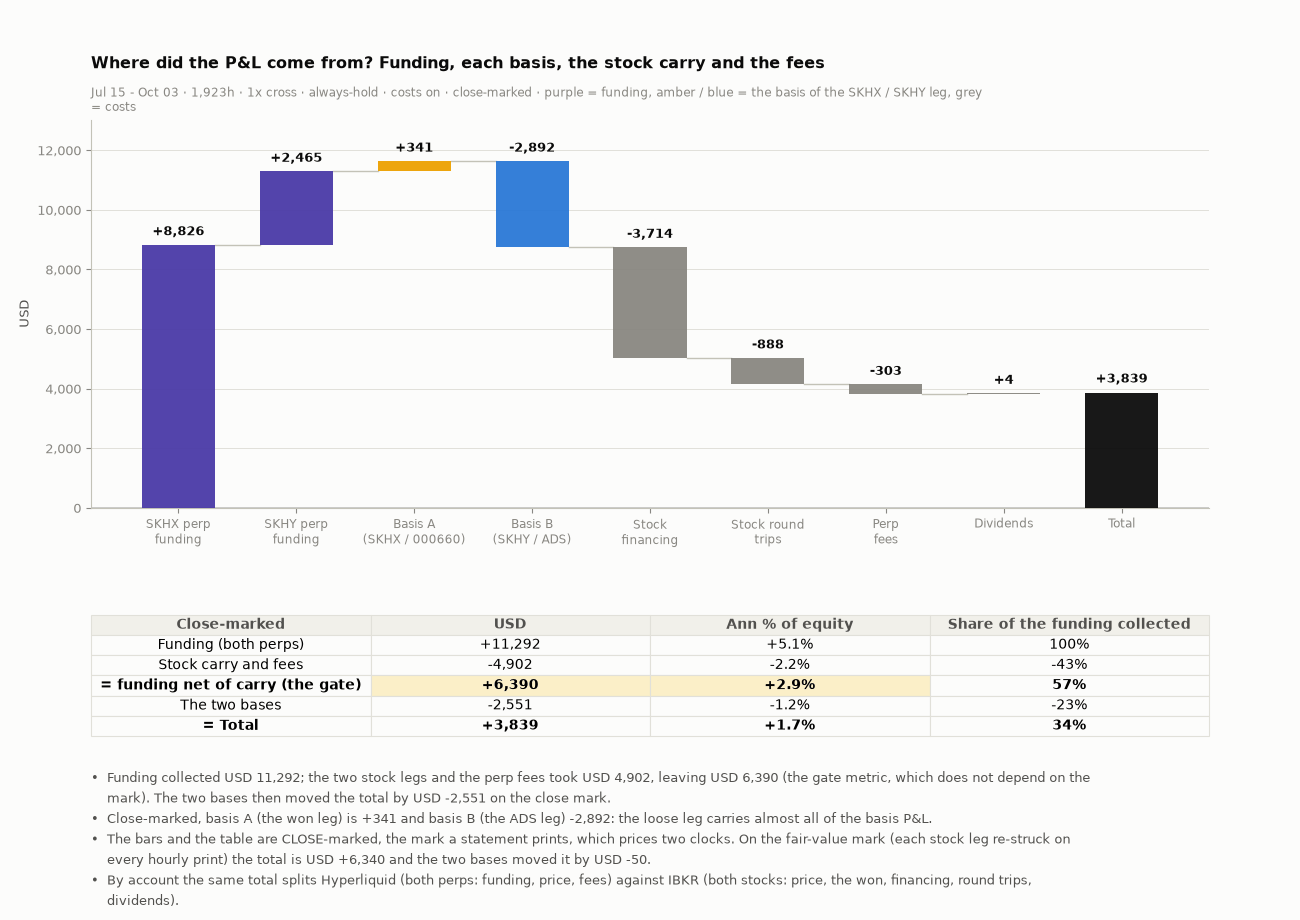

In [16]:
# ---- 2. Where did the P&L come from? a waterfall by source, then the same total by account ----
H2 = 9.2
fig = plt.figure(figsize=(13, H2))
parts = [("SKHX perp\nfunding", r_["funding_A"], C_NET), ("SKHY perp\nfunding", r_["funding_B"], C_NET), ("Basis A\n(SKHX / 000660)", BAS[BOOK]["A"], C_A), ("Basis B\n(SKHY / ADS)", BAS[BOOK]["B"], C_B),
         ("Stock\nfinancing", -r_["financing"], C_COST), ("Stock round\ntrips", -r_["stock_costs"], C_COST), ("Perp\nfees", -(r_["perp_fees"] + r_["perp_liq_fees"]), C_COST), ("Dividends", r_["dividends"], C_COST)]
assert abs(sum(p[1] for p in parts) - r_["total_pnl"]) < 1e-6
bm = figstyle.bullets(fig, [f"Funding collected USD {r_['funding_net']:,.0f}; the two stock legs and the perp fees took USD {COSTS_USD:,.0f}, leaving USD {CARRY_USD:,.0f} (the gate metric, which does not depend on the mark). The two bases then moved the total by USD {r_['net_basis_pnl']:+,.0f} on the close mark.",
                            f"Close-marked, basis A (the won leg) is {BAS[BOOK]['A']:+,.0f} and basis B (the ADS leg) {BAS[BOOK]['B']:+,.0f}: the loose leg carries almost all of the basis P&L.",
                            f"The bars and the table are CLOSE-marked, the mark a statement prints, which prices two clocks. On the fair-value mark (each stock leg re-struck on every hourly print) the total is USD {FV_TOTAL:+,.0f} and the two bases moved it by USD {FV_BASIS:+,.0f}.",
                            "By account the same total splits Hyperliquid (both perps: funding, price, fees) against IBKR (both stocks: price, the won, financing, round trips, dividends)."])
gs = fig.add_gridspec(2, 1, height_ratios=[3.2, 1.0], hspace=0.42, left=0.07, right=0.93, top=0.87, bottom=bm + 0.02)
ax, axt = fig.add_subplot(gs[0]), fig.add_subplot(gs[1]); axt.axis("off")
run = 0.0
for k, (nm, v, col) in enumerate(parts):
    lo_, hi_ = (run, run + v) if v >= 0 else (run + v, run)
    ax.bar(k, hi_ - lo_, bottom=lo_, color=col, alpha=0.95, width=0.62, zorder=3)
    ax.text(k, hi_ + (max(abs(p[1]) for p in parts)) * 0.025, f"{v:+,.0f}", ha="center", va="bottom", fontsize=9, color=INK, fontweight="bold")
    if k < len(parts) - 1:
        ax.plot([k + 0.31, k + 1 - 0.31], [run + v, run + v], color=AXIS, linewidth=1, zorder=2)
    run += v
ax.bar(len(parts), run, color=INK, width=0.62, zorder=3, alpha=0.95); ax.text(len(parts), max(run, 0) + max(abs(p[1]) for p in parts) * 0.03, f"{run:+,.0f}", ha="center", va="bottom", fontsize=9, color=INK, fontweight="bold")
ax.set_xticks(range(len(parts) + 1)); ax.set_xticklabels([p[0] for p in parts] + ["Total"], fontsize=8.8); ax.set_ylim(0, max(np.cumsum([p[1] for p in parts]).max(), 1) * 1.12)
ax.axhline(0, color=INK, linewidth=1, zorder=2); ax.set_ylabel("USD"); ax.grid(axis="x", visible=False)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, p: f"{v:,.0f}"))
ask(ax, "Where did the P&L come from? Funding, each basis, the stock carry and the fees", f"{WSH} · close-marked · purple = funding, amber / blue = the basis of the SKHX / SKHY leg, grey = costs")
cols = ["Close-marked", "USD", "Ann % of equity", "Share of the funding collected"]
rowsT = [["Funding (both perps)", r_["funding_net"], r_["funding_net"] / EQUITY / yrs * 100, 100.0],
         ["Stock carry and fees", -COSTS_USD, -COSTS_USD / EQUITY / yrs * 100, -COSTS_USD / r_["funding_net"] * 100],
         ["= funding net of carry (the gate)", CARRY_USD, CARRY_USD / EQUITY / yrs * 100, CARRY_USD / r_["funding_net"] * 100],
         ["The two bases", r_["net_basis_pnl"], r_["net_basis_pnl"] / EQUITY / yrs * 100, r_["net_basis_pnl"] / r_["funding_net"] * 100],
         ["= Total", r_["total_pnl"], r_["total_pnl"] / EQUITY / yrs * 100, r_["total_pnl"] / r_["funding_net"] * 100]]
cells = [[a, f"{b:+,.0f}", f"{c:+.1f}%", f"{d:.0f}%"] for a, b, c, d in rowsT]
tb = axt.table(cellText=cells, colLabels=cols, cellLoc="center", loc="center", bbox=[0, 0, 1, 1]); tb.auto_set_font_size(False); tb.set_fontsize(9.8); figstyle.style_table(tb)
for r_i in range(1, 6):
    tb[(r_i, 0)]._loc = "left"
for r_i in (3, 5):
    for c_i in range(4): tb[(r_i, c_i)].set_text_props(weight="bold")
figstyle.gold(tb, 3, 1); figstyle.gold(tb, 3, 2)
figstyle.show(fig, "fig:s3-pnl", FIGURES)
ST3["waterfall"] = [[p[0].replace("\n", " "), float(p[1])] for p in parts]
ST3["accounts"] = ACC[BOOK]

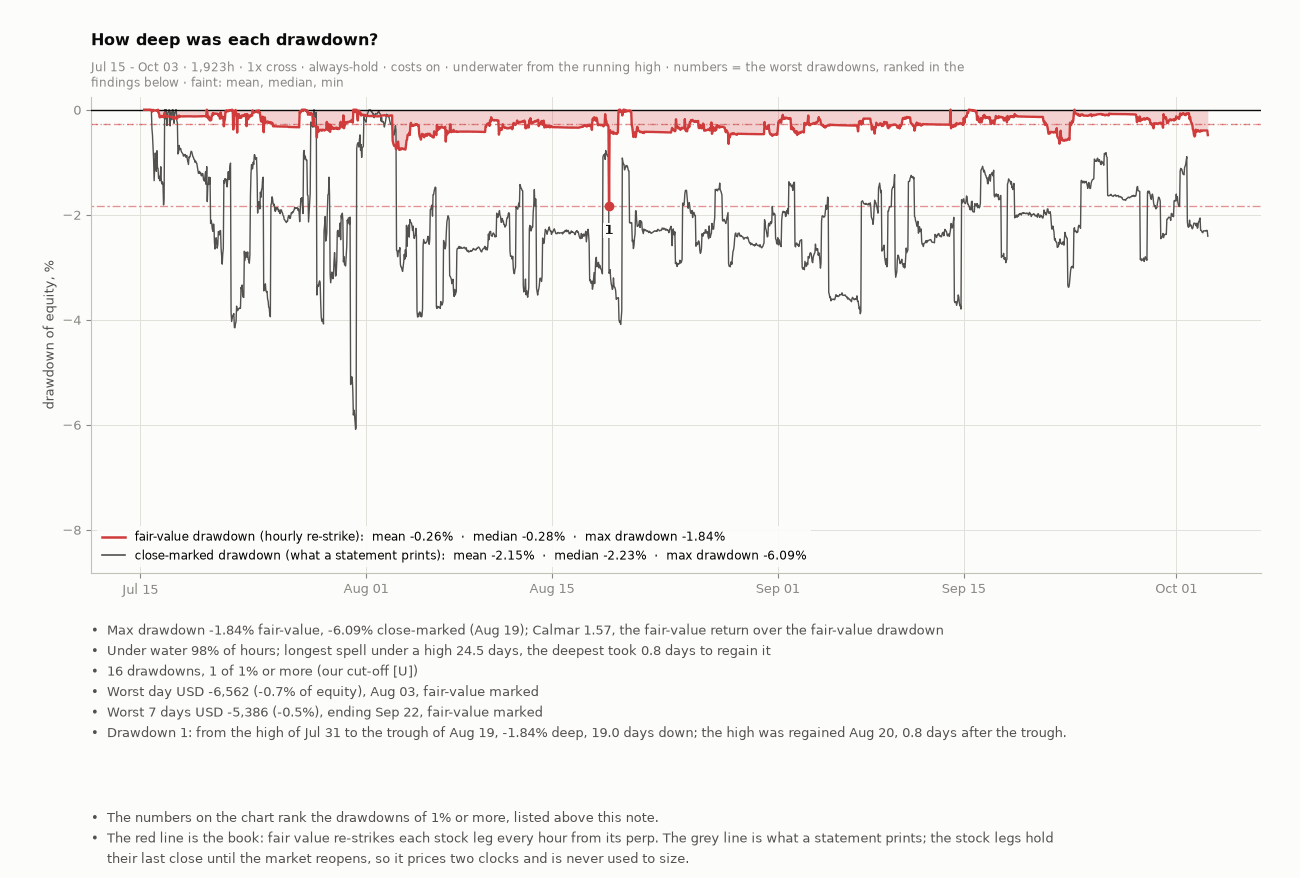

In [17]:
# ---- 3. How deep was each drawdown? close-marked vs fair-value; the episodes are listed in the findings, not in a table ----
under = uw_fv < -1e-9
calmar = FV_ANN / 100 / abs(uw_fv.min() / 100)                  # the return and the drawdown on the SAME mark: fair value
wd = DAYFV.min(); wd_day = DAYFV.idxmin()                       # fair-value days: the mark the tail figure and the verdict read
w7 = DAYFV.rolling(7).sum(); w7min, w7day = w7.min(), w7.idxmin()
EPL = [f"Drawdown {e['rank']}: from the high of {e['peak']:%b %d} to the trough of {e['trough']:%b %d}, {e['depth']:.2f}% deep, {e['days_down']:.1f} days down; "
       + (f"the high was regained {e['end']:%b %d}, {e['days_recover']:.1f} days after the trough." if e["recovered"] else f"not yet regained, {e['days_recover']:.1f} days after the trough.") for e in EP]
LNS = [f"Max drawdown {uw_fv.min():.2f}% fair-value, {uw.min():.2f}% close-marked ({uw_fv.idxmin():%b %d}); Calmar {calmar:.2f}, the fair-value return over the fair-value drawdown",
       f"Under water {under.mean() * 100:.0f}% of hours; longest spell under a high {LONGEST_DD_DAYS:.1f} days, the deepest took " + (f"{RECOVERY_DEEPEST:.1f} days to regain it" if RECOVERY_DEEPEST == RECOVERY_DEEPEST else "no time to regain it: not yet regained"),
       f"{len(eps)} drawdowns, {len(EP)} of 1% or more (our cut-off [U])",
       f"Worst day {usd(wd)} ({wd / EQUITY * 100:+.1f}% of equity), {wd_day:%b %d}, fair-value marked",
       f"Worst 7 days {usd(w7min)} ({w7min / EQUITY * 100:+.1f}%), ending {w7day:%b %d}, fair-value marked"] + EPL
AXB_IN = 0.205 * len(LNS) + 0.25
H3 = 7.3 + AXB_IN
fig = plt.figure(figsize=(13, H3))
bm = figstyle.bullets(fig, ["The numbers on the chart rank the drawdowns of 1% or more, listed above this note.",
                            "The red line is the book: fair value re-strikes each stock leg every hour from its perp. The grey line is what a statement prints; the stock legs hold their last close until the market reopens, so it prices two clocks and is never used to size."])
gs = fig.add_gridspec(2, 1, height_ratios=[4.6, AXB_IN], hspace=0.16, left=0.07, right=0.97, top=0.89, bottom=bm + 0.02)
ax, axb = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])
ax.fill_between(df.index, uw_fv, 0, color=CRIT, alpha=0.22, linewidth=0, zorder=2); ax.plot(df.index, uw_fv, color=CRIT, linewidth=1.7, zorder=4)
ax.plot(df.index, uw, color=INK2, linewidth=1.0, zorder=3)
for k, y in (("mean", uw_fv.mean()), ("median", uw_fv.median()), ("min", uw_fv.min())):
    ax.axhline(y, color=CRIT, linewidth=0.95, linestyle=LSf[k], alpha=0.55, zorder=2)
for e in EP:
    ax.plot([e["trough"]], [e["depth"]], "o", color=CRIT, markersize=6, zorder=6)
    ax.annotate(f"{e['rank']}", xy=(e["trough"], e["depth"]), xytext=(0, -13), textcoords="offset points", ha="center", va="top", fontsize=9, color=INK, fontweight="bold", bbox=dict(facecolor=SURF, edgecolor="none", pad=1.0), zorder=7)
ax.plot([], [], color=CRIT, linewidth=1.8, label=f"fair-value drawdown (hourly re-strike):  mean {uw_fv.mean():+.2f}%  ·  median {uw_fv.median():+.2f}%  ·  max drawdown {uw_fv.min():+.2f}%")
ax.plot([], [], color=INK2, linewidth=1.2, label=f"close-marked drawdown (what a statement prints):  mean {uw.mean():+.2f}%  ·  median {uw.median():+.2f}%  ·  max drawdown {uw.min():+.2f}%")
ax.axhline(0, color=INK, linewidth=1, zorder=3); ax.set_ylabel("drawdown of equity, %"); ax.legend(loc="lower left", fontsize=8.5, **LEG)
ax.set_ylim(min(uw.min(), uw_fv.min()) * 1.45, 0.25); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ask(ax, "How deep was each drawdown?", f"{WSH} · underwater from the running high · numbers = the worst drawdowns, ranked in the findings below · faint: mean, median, min")
figstyle.bullets_ax(axb, LNS)
figstyle.show(fig, "fig:s3-drawdown", FIGURES)
ST3["drawdown"] = {"mean": float(uw_fv.mean()), "median": float(uw_fv.median()), "min": float(uw_fv.min()), "close_min": float(uw.min()), "when": f"{uw_fv.idxmin():%b %d}", "share_under": float(under.mean() * 100),
                     "longest_days": LONGEST_DD_DAYS, "recovery_deepest_days": (None if RECOVERY_DEEPEST != RECOVERY_DEEPEST else float(RECOVERY_DEEPEST)), "calmar": float(calmar), "n_eps": len(eps), "n_cut": len(EP), "worst_day": float(wd), "worst_day_pct": float(wd / EQUITY * 100), "worst_7d": float(w7min), "worst_7d_pct": float(w7min / EQUITY * 100),
                     "eps": [{"rank": e["rank"], "peak": f"{e['peak']:%b %d}", "trough": f"{e['trough']:%b %d}", "end": f"{e['end']:%b %d}", "depth": e["depth"], "days_down": e["days_down"], "days_recover": e["days_recover"]} for e in EP]}

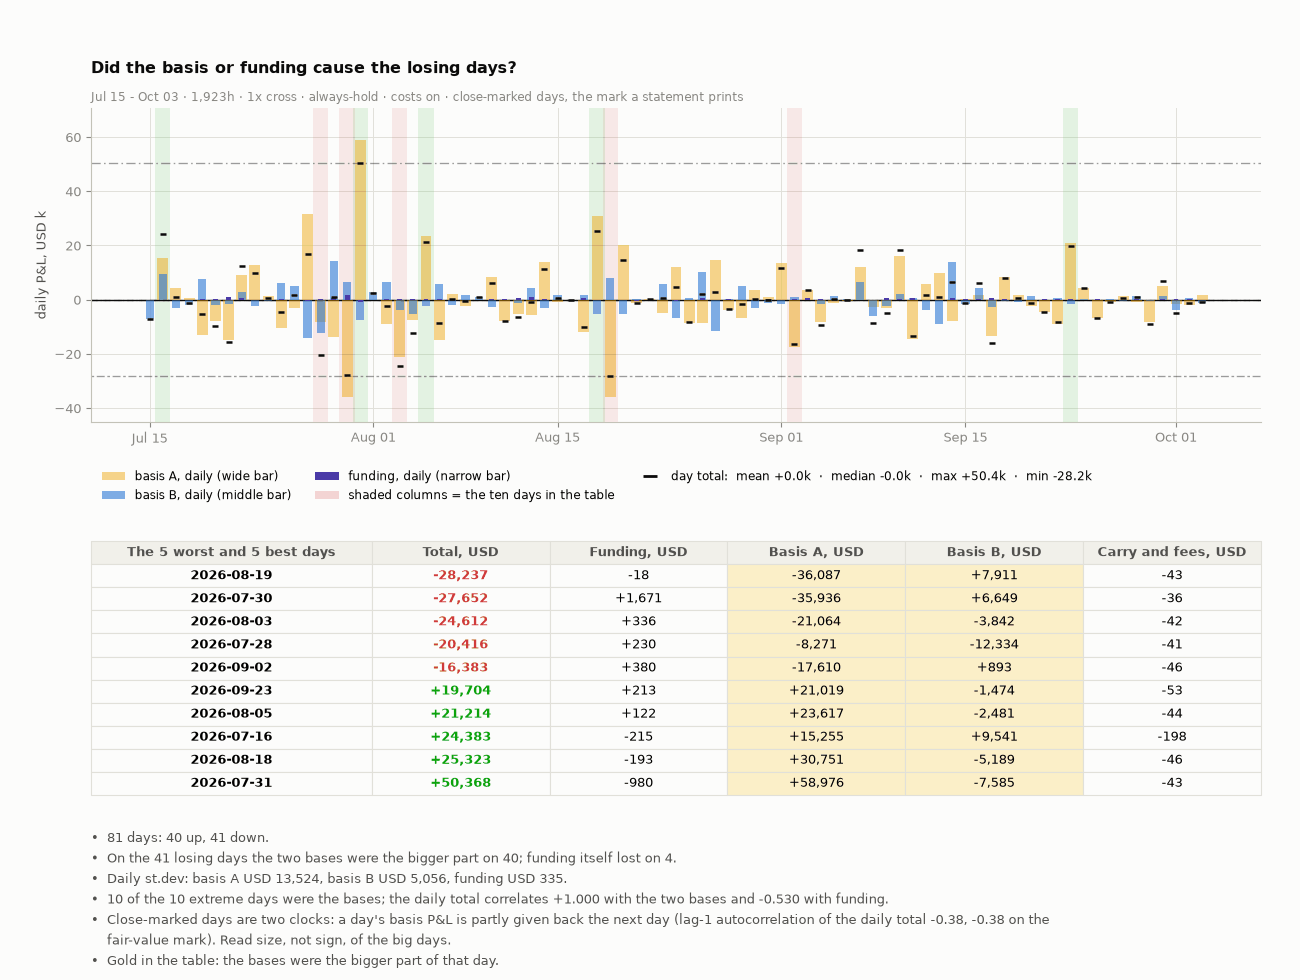

RISK {'vol': 3.630854429455973, 'sharpe': 0.7868941008521114, 'sharpe_excess': -0.34507086217611427, 'sortino': 1.2097951347270375, 'calmar': 1.5693680462717654, 'n_days': 81, 'lag1_autocorr': -0.3826380882443123, 'lag1_autocorr_fv': -0.3837663795668917}


In [18]:
# ---- 4. Did funding or the basis cause the losing days? the daily bars, each source on its own width, then the extreme days ----
D2 = DAY.copy(); D2["basis_A"], D2["basis_B"] = DB["basis_A"], DB["basis_B"]
D2["carry_all"] = D2["carry"]
assert float((D2["funding"] + D2["basis_A"] + D2["basis_B"] + D2["carry_all"] - D2["total"]).abs().max()) < 1e-6
EXT = pd.concat([D2.nsmallest(5, "total"), D2.nlargest(5, "total")]).sort_values("total")
loss = D2[D2["total"] < 0]
basis_big = int(((loss["basis_A"] + loss["basis_B"]).abs() > loss["funding"].abs()).sum())
basis_ext = int(((EXT["basis_A"] + EXT["basis_B"]).abs() > EXT["funding"].abs()).sum())
bs = D2["basis_A"] + D2["basis_B"]
H4 = 9.8
fig = plt.figure(figsize=(13, H4))
bm = figstyle.bullets(fig, [f"{len(D2)} days: {(D2['total'] > 0).sum()} up, {len(loss)} down.",
                            f"On the {len(loss)} losing days the two bases were the bigger part on {basis_big}; funding itself lost on {int((loss['funding'] < 0).sum())}.",
                            f"Daily st.dev: basis A USD {D2['basis_A'].std():,.0f}, basis B USD {D2['basis_B'].std():,.0f}, funding USD {D2['funding'].std():,.0f}.",
                            f"{basis_ext} of the {len(EXT)} extreme days were the bases; the daily total correlates {D2['total'].corr(bs):+.3f} with the two bases and {D2['total'].corr(D2['funding']):+.3f} with funding.",
                            f"Close-marked days are two clocks: a day's basis P&L is partly given back the next day (lag-1 autocorrelation of the daily total {r_['daily_lag1_autocorr']:+.2f}, {r_['daily_lag1_autocorr_fv']:+.2f} on the fair-value mark). Read size, not sign, of the big days.",
                            "Gold in the table: the bases were the bigger part of that day."])
gs = fig.add_gridspec(2, 1, height_ratios=[2.6, 2.1], hspace=0.42, left=0.07, right=0.97, top=0.89, bottom=bm + 0.02)
ax, axt = fig.add_subplot(gs[0]), fig.add_subplot(gs[1]); axt.axis("off")
x = D2.index
for d_, rr in EXT.iterrows():
    ax.axvspan(d_ - pd.Timedelta(hours=14), d_ + pd.Timedelta(hours=14), color=(CRIT if rr["total"] < 0 else GOOD), alpha=0.10, linewidth=0, zorder=1)
ax.bar(x, D2["basis_A"] / 1e3, width=pd.Timedelta(hours=20), color=C_A, alpha=0.45, zorder=3)
ax.bar(x, D2["basis_B"] / 1e3, width=pd.Timedelta(hours=15), color=C_B, alpha=0.6, zorder=4)
ax.bar(x, D2["funding"] / 1e3, width=pd.Timedelta(hours=9), color=C_NET, zorder=5)
ax.scatter(x, D2["total"] / 1e3, s=20, marker="_", color=INK, linewidths=1.8, zorder=6)
tt = D2["total"] / 1e3
for k, y in (("mean", tt.mean()), ("median", tt.median()), ("max", tt.max()), ("min", tt.min())):
    ax.axhline(y, color=INK, linewidth=0.95, linestyle=LSf[k], alpha=0.4, zorder=2)
ax.axhline(0, color=INK, linewidth=1, zorder=2)
_h = [Patch(facecolor=C_A, alpha=0.45, label="basis A, daily (wide bar)"), Patch(facecolor=C_B, alpha=0.6, label="basis B, daily (middle bar)"), Patch(facecolor=C_NET, label="funding, daily (narrow bar)"),
      Patch(facecolor=CRIT, alpha=0.2, label="shaded columns = the ten days in the table"),
      plt.Line2D([], [], color=INK, marker="_", markersize=10, markeredgewidth=2, linestyle="none", label=f"day total:  mean {tt.mean():+.1f}k  ·  median {tt.median():+.1f}k  ·  max {tt.max():+.1f}k  ·  min {tt.min():+.1f}k")]
ax.set_ylabel("daily P&L, USD k"); ax.legend(handles=_h, loc="upper left", bbox_to_anchor=(0.0, -0.12), ncol=3, fontsize=8.5, frameon=False); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.set_ylim(min(tt.min(), (D2["basis_A"] / 1e3).min()) * 1.25, max(tt.max(), (D2["basis_A"] / 1e3).max()) * 1.2)
ask(ax, "Did the basis or funding cause the losing days?", f"{WSH} · close-marked days, the mark a statement prints")
cells = [[f"{d:%Y-%m-%d}", f"{rr['total']:+,.0f}", f"{rr['funding']:+,.0f}", f"{rr['basis_A']:+,.0f}", f"{rr['basis_B']:+,.0f}", f"{rr['carry_all']:+,.0f}"] for d, rr in EXT.iterrows()]
tb = figstyle.put_table(axt, cells, ["The 5 worst and 5 best days", "Total, USD", "Funding, USD", "Basis A, USD", "Basis B, USD", "Carry and fees, USD"], size=9.5, first=0.24)
for r_i in range(1, len(EXT) + 1):
    row = EXT.iloc[r_i - 1]
    tb[(r_i, 1)].set_text_props(color=(GOOD if row["total"] > 0 else CRIT), weight="bold")
    if abs(row["basis_A"] + row["basis_B"]) > abs(row["funding"]):
        figstyle.tint(tb, r_i, 3, "gold"); figstyle.tint(tb, r_i, 4, "gold")
figstyle.show(fig, "fig:s3-daily", FIGURES)
ST3["daily"] = {"days": len(D2), "up": int((D2['total'] > 0).sum()), "down": len(loss), "basis_bigger_on_losing": basis_big, "n_ext": len(EXT), "basis_ext": basis_ext,
                  "corr_basis": float(D2['total'].corr(bs)), "corr_fund": float(D2['total'].corr(D2['funding'])), "std_A": float(D2['basis_A'].std()), "std_B": float(D2['basis_B'].std()), "std_fund": float(D2['funding'].std())}
from fundplat.quant.core import stats as ST
# the ratios are on the FAIR-VALUE daily returns on equity (the mark the verdict reads, and the one the PSR and the DSR use); the close-marked daily series is two clocks
assert abs(DAYFV.sum() - res["total_pnl_fv"]) < 1e-6, (DAYFV.sum(), res["total_pnl_fv"])      # DAYFV is built in the first S3 cell
_dr = list((DAYFV / EQUITY).values)
ST3["risk"] = {"vol": float(np.std(_dr, ddof=1) * np.sqrt(365) * 100), "sharpe": float(ST.sharpe(_dr, 365)), "sharpe_excess": float(ST.sharpe([x_ - HURDLE_PCT / 100 / 365 for x_ in _dr], 365)), "sortino": float(ST.sortino(_dr, 365)), "calmar": float(calmar), "n_days": len(_dr),
                 "lag1_autocorr": float(r_["daily_lag1_autocorr"]), "lag1_autocorr_fv": float(r_["daily_lag1_autocorr_fv"])}
print("RISK", ST3["risk"], flush=True)

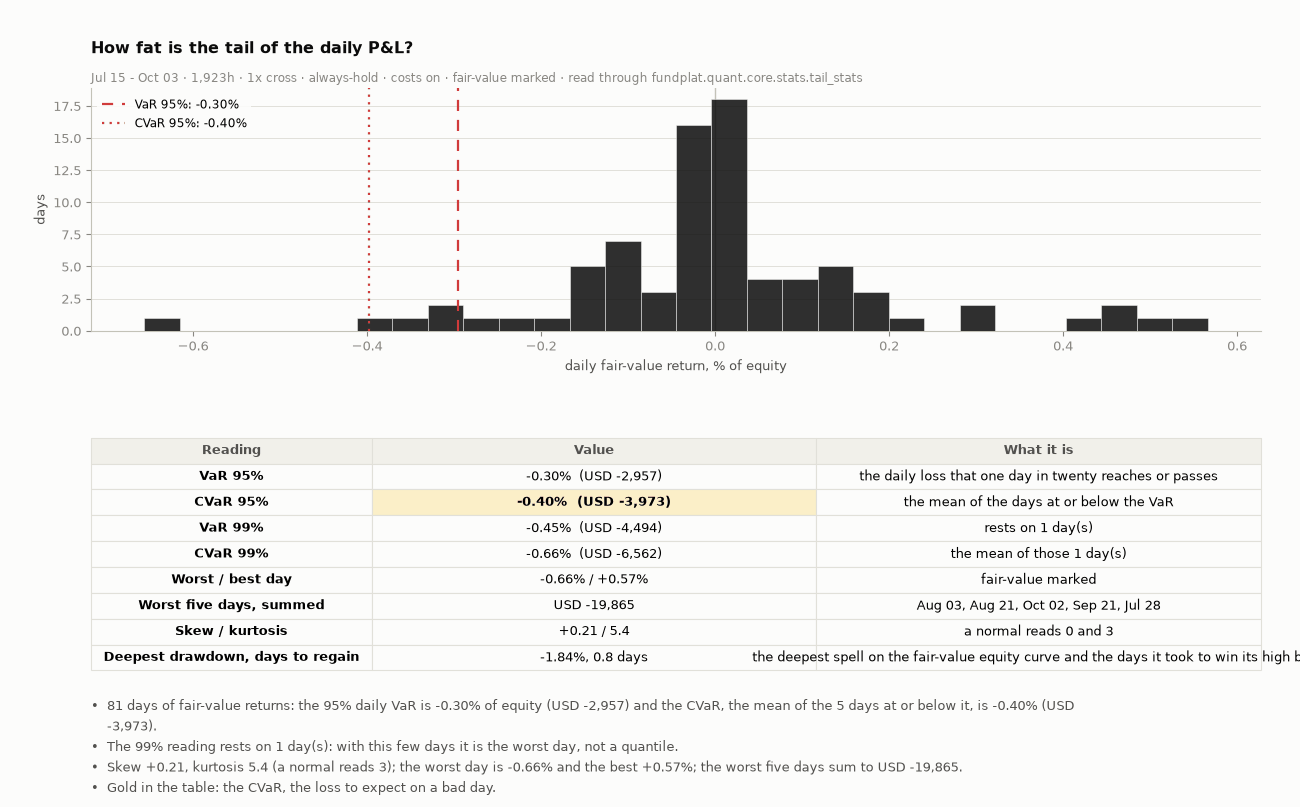

In [19]:
# ---- 5. How fat is the tail of the daily P&L? Read through fundplat.quant.core.stats.tail_stats on the fair-value daily returns ----
RET_D = DAYFV / EQUITY * 100.0
T95, T99 = ST.tail_stats(list(RET_D.values), 0.95), ST.tail_stats(list(RET_D.values), 0.99)
n_tail95, n_tail99 = int((RET_D <= T95["VaR 95%"]).sum()), int((RET_D <= T99["VaR 99%"]).sum())
W5 = DAYFV.nsmallest(5)
BUL = [f"{T95['n']} days of fair-value returns: the 95% daily VaR is {T95['VaR 95%']:+.2f}% of equity ({usd(T95['VaR 95%'] * EQUITY / 100)}) and the CVaR, the mean of the {n_tail95} days at or below it, is {T95['CVaR 95%']:+.2f}% ({usd(T95['CVaR 95%'] * EQUITY / 100)}).",
       f"The 99% reading rests on {n_tail99} day(s): with this few days it is the worst day, not a quantile.",
       f"Skew {T95['skew']:+.2f}, kurtosis {T95['kurtosis']:.1f} (a normal reads 3); the worst day is {T95['worst']:+.2f}% and the best {T95['best']:+.2f}%; the worst five days sum to {usd(W5.sum())}.",
       "Gold in the table: the CVaR, the loss to expect on a bad day."]
fig, gs, ax, axt = figstyle.fig_tab(6.8, (2.4, 2.3), nb=figstyle.nlines(BUL))
ax.hist(RET_D, bins=30, color=INK, alpha=0.85, edgecolor=SURF, linewidth=0.4, zorder=3)
ax.axvline(0, color=AXIS, linewidth=1, zorder=2)
ax.axvline(T95["VaR 95%"], color=CRIT, linestyle=LSf["mean"], linewidth=1.6, zorder=5, label=f"VaR 95%: {T95['VaR 95%']:+.2f}%")
ax.axvline(T95["CVaR 95%"], color=CRIT, linestyle=LSf["median"], linewidth=1.6, zorder=5, label=f"CVaR 95%: {T95['CVaR 95%']:+.2f}%")
ax.set_xlabel("daily fair-value return, % of equity"); ax.set_ylabel("days"); ax.grid(axis="x", visible=False); ax.legend(loc="upper left", fontsize=8.5, **LEG)
ask(ax, "How fat is the tail of the daily P&L?", f"{WSH} · fair-value marked · read through fundplat.quant.core.stats.tail_stats")
cells = [["VaR 95%", f"{T95['VaR 95%']:+.2f}%  ({usd(T95['VaR 95%'] * EQUITY / 100)})", "the daily loss that one day in twenty reaches or passes"],
         ["CVaR 95%", f"{T95['CVaR 95%']:+.2f}%  ({usd(T95['CVaR 95%'] * EQUITY / 100)})", "the mean of the days at or below the VaR"],
         ["VaR 99%", f"{T99['VaR 99%']:+.2f}%  ({usd(T99['VaR 99%'] * EQUITY / 100)})", f"rests on {n_tail99} day(s)"],
         ["CVaR 99%", f"{T99['CVaR 99%']:+.2f}%  ({usd(T99['CVaR 99%'] * EQUITY / 100)})", f"the mean of those {n_tail99} day(s)"],
         ["Worst / best day", f"{T95['worst']:+.2f}% / {T95['best']:+.2f}%", "fair-value marked"],
         ["Worst five days, summed", usd(W5.sum()), ", ".join(f"{d_:%b %d}" for d_ in W5.index)],
         ["Skew / kurtosis", f"{T95['skew']:+.2f} / {T95['kurtosis']:.1f}", "a normal reads 0 and 3"],
         ["Deepest drawdown, days to regain", f"{uw_fv.min():.2f}%, " + (f"{RECOVERY_DEEPEST:.1f} days" if RECOVERY_DEEPEST == RECOVERY_DEEPEST else "not regained"), "the deepest spell on the fair-value equity curve and the days it took to win its high back"]]
tb = figstyle.put_table(axt, cells, ["Reading", "Value", "What it is"], size=9.5, first=0.24)
figstyle.gold(tb, 2, 1)
figstyle.bullets(fig, BUL)
figstyle.show(fig, "fig:s3-tail", FIGURES)
ST3["tail"] = {"var95": T95["VaR 95%"], "cvar95": T95["CVaR 95%"], "var99": T99["VaR 99%"], "cvar99": T99["CVaR 99%"], "skew": T95["skew"], "kurtosis": T95["kurtosis"],
               "worst": T95["worst"], "best": T95["best"], "n": T95["n"], "worst5_usd": float(W5.sum())}

## S4 · Robustness

Is it real: out of sample, statistically significant, after costs? Then: does an exit rule help, and how much is the entry hour?

In [20]:
from matplotlib.patches import Patch
fig_tab, put_table, gold, tint = figstyle.fig_tab, figstyle.put_table, figstyle.gold, figstyle.tint
def foot(fig, *lines):
    figstyle.bullets(fig, [t for t in lines if t])

ST4 = {"hours": int(res["n_hours"])}
WSH = f"{df.index[0]:%b %d} - {df.index[-1]:%b %d} · {len(df):,}h"
WSB = WSH + " · 1x cross · reserve 0 · costs on"
DAY = DAYS_[BOOK]
G1a = bool(carry_ann(res) > HURDLE_PCT)
carry_cum = lambda d: (num(d["cum_funding_net"]) - num(d["cum_financing"]) - num(d["cum_stock_costs"]) - num(d["cum_perp_fees"]) + num(d["cum_dividends"])) / 1e3
tcum = lambda d: EQUITY * p1.hurdle_ann * np.asarray((d.index - d.index[0]).total_seconds()) / (365 * 86400) / 1e3

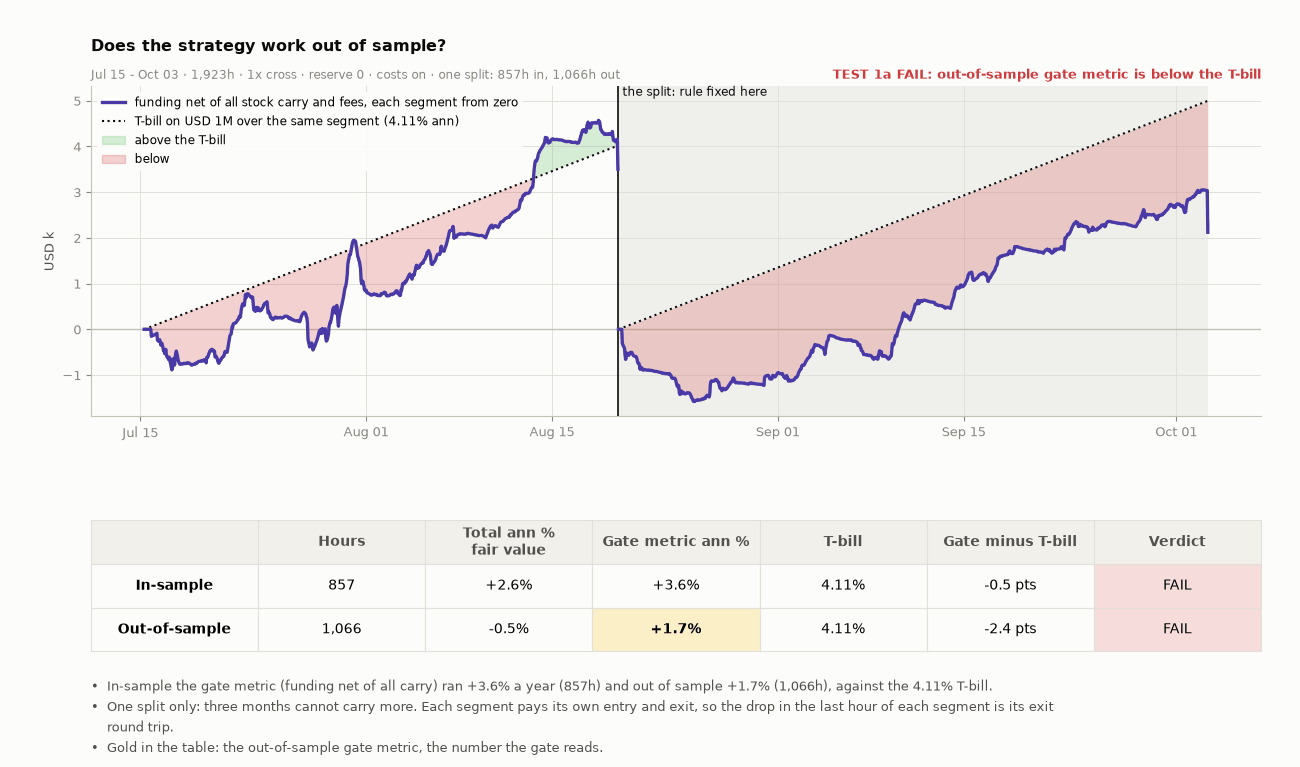

In [21]:
# ---- Test 1a: out of sample ----
rows_in = [r for r in rows if r["time"] < SPLIT]; rows_out = [r for r in rows if r["time"] >= SPLIT]
SEG = {}
for nm_, rw_ in (("in", rows_in), ("out", rows_out)):
    r_ = run4(rw_, PAR[BOOK]); vfour(r_, rw_, f"walk-forward {nm_}"); SEG[nm_] = r_
r_in, r_out = SEG["in"], SEG["out"]
G2a = bool(carry_ann(r_out) > HURDLE_PCT)
d_in, d_out = frame(r_in), frame(r_out)
BUL = [f"In-sample the gate metric (funding net of all carry) ran {carry_ann(r_in):+.1f}% a year ({r_in['n_hours']:,}h) and out of sample {carry_ann(r_out):+.1f}% ({r_out['n_hours']:,}h), against the {HURDLE_PCT:.2f}% T-bill.",
       "One split only: three months cannot carry more. Each segment pays its own entry and exit, so the drop in the last hour of each segment is its exit round trip.",
       "Gold in the table: the out-of-sample gate metric, the number the gate reads."]
fig, gs, ax, axt = fig_tab(6.6, (2.9, 1.15), nb=figstyle.nlines(BUL))
split_ts = pd.Timestamp(SPLIT, unit="ms", tz="UTC")
ax.axvspan(split_ts, d_out.index[-1], color=AXIS, alpha=0.22, linewidth=0, zorder=0)
for d in (d_in, d_out):
    f_, t_ = carry_cum(d), pd.Series(tcum(d), index=d.index)
    ax.plot(d.index, f_, color=C_NET, linewidth=2.4, zorder=4); ax.plot(d.index, t_, color=INK, linewidth=1.5, linestyle=":", zorder=3)
    ax.fill_between(d.index, f_, t_, where=(f_ >= t_), interpolate=True, color=GOOD, alpha=0.16, linewidth=0, zorder=2)
    ax.fill_between(d.index, f_, t_, where=(f_ < t_), interpolate=True, color=CRIT, alpha=0.22, linewidth=0, zorder=2)
ax.axvline(split_ts, color=INK, linewidth=1.2, zorder=3); ax.text(split_ts, ax.get_ylim()[1], " the split: rule fixed here", color=INK, fontsize=8.5, va="top")
ax.plot([], [], color=C_NET, linewidth=2.4, label="funding net of all stock carry and fees, each segment from zero")
ax.plot([], [], color=INK, linewidth=1.5, linestyle=":", label=f"T-bill on {usdm(EQUITY)} over the same segment ({HURDLE_PCT:.2f}% ann)")
ax.fill_between([], [], color=GOOD, alpha=0.16, label="above the T-bill"); ax.fill_between([], [], color=CRIT, alpha=0.22, label="below")
ax.axhline(0, color=AXIS, linewidth=1, zorder=1); ax.set_ylabel("USD k"); ax.legend(loc="upper left", fontsize=8.5, **LEG); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.text(1.0, 1.012, ("TEST 1a PASS: out-of-sample gate metric is above the T-bill" if G2a else "TEST 1a FAIL: out-of-sample gate metric is below the T-bill"), transform=ax.transAxes, ha="right", va="bottom", color=(GOOD if G2a else CRIT), fontsize=9.5, fontweight="bold")
ask(ax, "Does the strategy work out of sample?", f"{WSB} · one split: {r_in['n_hours']:,}h in, {r_out['n_hours']:,}h out")
cells = [[nm, f"{r_['n_hours']:,}", f"{fv_ann(r_):+.1f}%", f"{carry_ann(r_):+.1f}%", f"{HURDLE_PCT:.2f}%", f"{carry_ann(r_) - HURDLE_PCT:+.1f} pts", ("PASS" if carry_ann(r_) > HURDLE_PCT else "FAIL")]
         for nm, r_ in (("In-sample", r_in), ("Out-of-sample", r_out))]
tb = put_table(axt, cells, ["", "Hours", "Total ann %" + chr(10) + "fair value", "Gate metric ann %", "T-bill", "Gate minus T-bill", "Verdict"])
gold(tb, 2, 3)
for r_i in (1, 2): tint(tb, r_i, 6, "green" if cells[r_i - 1][6] == "PASS" else "rose")
foot(fig, *BUL)
figstyle.show(fig, "fig:s4-oos", FIGURES)
ST4["oos"] = {"in": {"hours": r_in["n_hours"], "ann": fv_ann(r_in), "gate": carry_ann(r_in)}, "out": {"hours": r_out["n_hours"], "ann": fv_ann(r_out), "gate": carry_ann(r_out)}, "pass": G2a}

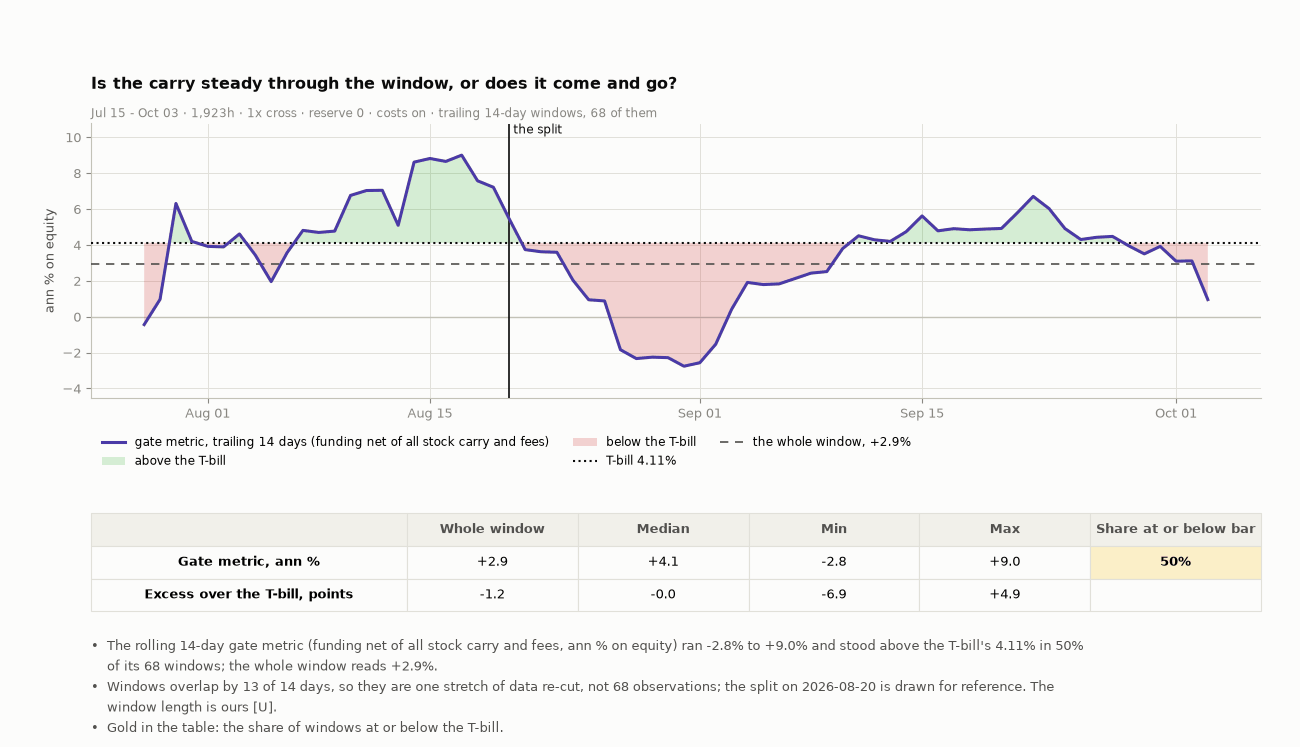

In [22]:
# ---- Test 1a, beside the split: is the carry steady through the window, or does it sit in one stretch? (the chart bank's rolling-statistics type, one panel: this notebook has no beta to roll; the same figure as the ratio-hedge study's) ----
GMD = DAY["funding_net_carry"]                                            # the gate metric, USD a day: the series Test 1b and the base test read
ROLL = (GMD.rolling(ROLL_D).sum() / ROLL_D * 365.0 / EQUITY * 100.0).dropna()      # funding net of all stock carry and fees, ann % on equity, over the trailing ROLL_D days
GFULL = carry_ann(res)
assert abs(GMD.sum() / EQUITY * 100.0 / res["days"] * 365.0 - GFULL) < 0.05, (GMD.sum(), GFULL)    # the daily series IS the gate metric the base test reads
n_roll = int(len(ROLL)); up_roll = float((ROLL > HURDLE_PCT).mean() * 100)
ROLLSTAT = {"median": float(ROLL.median()), "min": float(ROLL.min()), "max": float(ROLL.max()), "below": float((ROLL <= HURDLE_PCT).mean() * 100)}
BUL = [f"The rolling {ROLL_D}-day gate metric (funding net of all stock carry and fees, ann % on equity) ran {ROLLSTAT['min']:+.1f}% to {ROLLSTAT['max']:+.1f}% and stood above the T-bill's {HURDLE_PCT:.2f}% in {up_roll:.0f}% of its {n_roll} windows; the whole window reads {GFULL:+.1f}%.",
       f"Windows overlap by {ROLL_D - 1} of {ROLL_D} days, so they are one stretch of data re-cut, not {n_roll} observations; the split on {SPLIT_DATE} is drawn for reference. The window length is ours [U].",
       "Gold in the table: the share of windows at or below the T-bill."]
fig, gs, ax, axt = fig_tab(6.2, (2.8, 1.0), top=0.80, hspace=0.62, nb=figstyle.nlines(BUL))
ax.plot(ROLL.index, ROLL, color=C_NET, linewidth=2.2, zorder=4, label=f"gate metric, trailing {ROLL_D} days (funding net of all stock carry and fees)")
ax.fill_between(ROLL.index, ROLL, HURDLE_PCT, where=(ROLL >= HURDLE_PCT), interpolate=True, color=GOOD, alpha=0.16, linewidth=0, zorder=2, label="above the T-bill")
ax.fill_between(ROLL.index, ROLL, HURDLE_PCT, where=(ROLL < HURDLE_PCT), interpolate=True, color=CRIT, alpha=0.22, linewidth=0, zorder=2, label="below the T-bill")
ax.axhline(HURDLE_PCT, color=INK, linestyle=":", linewidth=1.5, zorder=3, label=f"T-bill {HURDLE_PCT:.2f}%")
ax.axhline(GFULL, color=INK2, linestyle=LSf["mean"], linewidth=1.2, zorder=3, label=f"the whole window, {GFULL:+.1f}%")
ax.axhline(0, color=AXIS, linewidth=1, zorder=1)
figstyle.yfit(ax, [ROLL, pd.Series([HURDLE_PCT, GFULL])], pad=0.15)
ax.axvline(split_ts, color=INK, linewidth=1.2, zorder=3); ax.text(split_ts, ax.get_ylim()[1], " the split", color=INK, fontsize=8.5, va="top")
ax.set_ylabel("ann % on equity"); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.legend(loc="upper left", bbox_to_anchor=(0.0, -0.1), ncol=3, fontsize=8.5, frameon=False)
ask(ax, "Is the carry steady through the window, or does it come and go?", f"{WSB} · trailing {ROLL_D}-day windows, {n_roll} of them")
cells = [["Gate metric, ann %", f"{GFULL:+.1f}", f"{ROLLSTAT['median']:+.1f}", f"{ROLLSTAT['min']:+.1f}", f"{ROLLSTAT['max']:+.1f}", f"{ROLLSTAT['below']:.0f}%"],
         ["Excess over the T-bill, points", f"{GFULL - HURDLE_PCT:+.1f}", f"{ROLLSTAT['median'] - HURDLE_PCT:+.1f}", f"{ROLLSTAT['min'] - HURDLE_PCT:+.1f}", f"{ROLLSTAT['max'] - HURDLE_PCT:+.1f}", ""]]
tb = put_table(axt, cells, ["", "Whole window", "Median", "Min", "Max", "Share at or below bar"], size=9.5, first=0.27)
gold(tb, 1, 5)
foot(fig, *BUL)
figstyle.show(fig, "fig:s4-rolling-carry", FIGURES)
ST4["rolling"] = {"window_d": ROLL_D, "n": n_roll, "full": GFULL, "median": ROLLSTAT["median"], "min": ROLLSTAT["min"], "max": ROLLSTAT["max"], "share_above_pct": up_roll, "share_at_or_below_pct": ROLLSTAT["below"]}

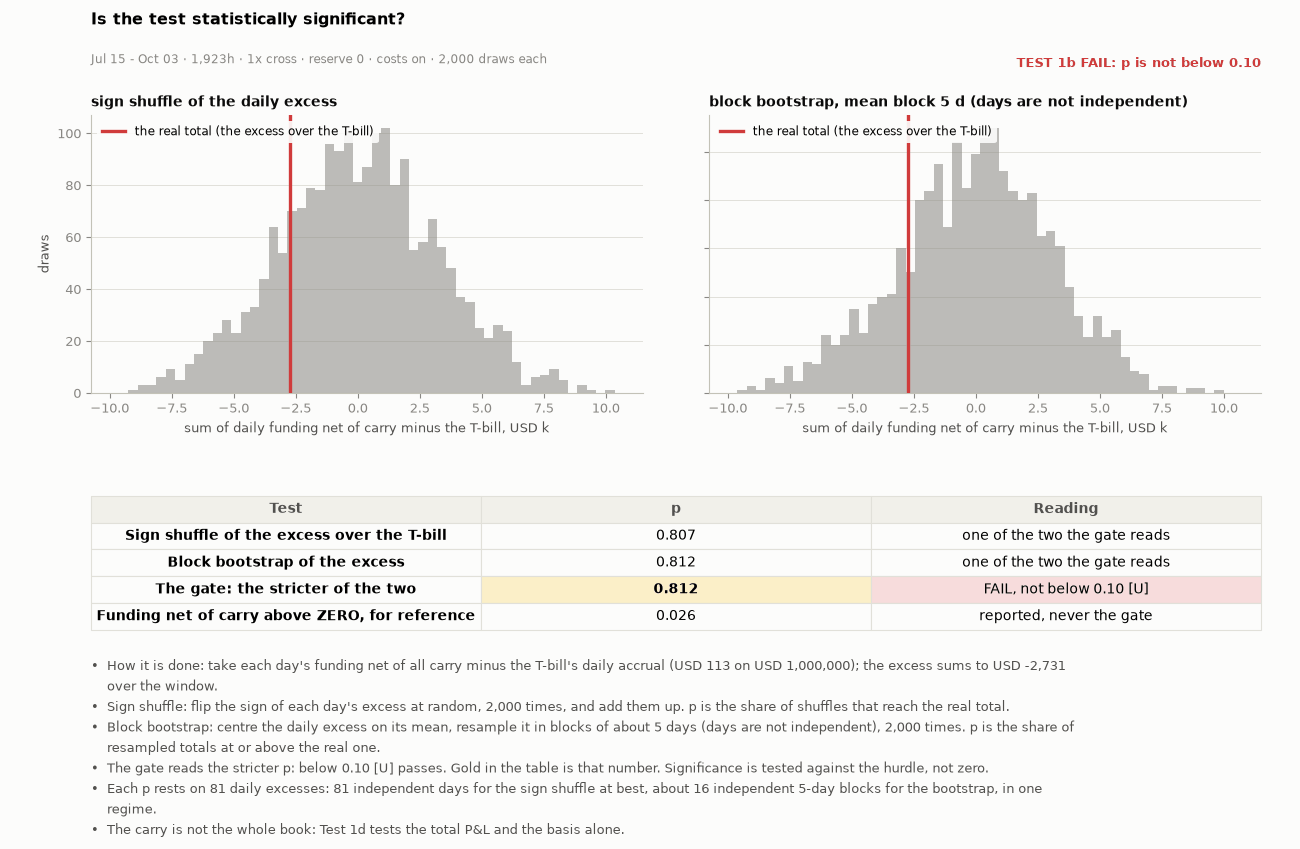

In [23]:
# ---- Test 1b: luck, against the hurdle ----
v = DAY["funding_net_carry"].values
HURDLE_DAY = p1.hurdle_ann * EQUITY / 365.0
ex_ = v - HURDLE_DAY
sh_ = (np.abs(ex_) * np.random.default_rng(SEED + 1).choice([-1.0, 1.0], size=(NSHUF, len(ex_)))).sum(axis=1)
p_sign = float((sh_ >= ex_.sum()).mean())
bt_ = ST.bootstrap_p_one_sided(ex_, BOOT_BLOCK_D, NSHUF, np.random.default_rng(SEED + 2))
sh0 = (np.abs(v) * np.random.default_rng(SEED).choice([-1.0, 1.0], size=(NSHUF, len(v)))).sum(axis=1)
p_zero = float((sh0 >= v.sum()).mean())
p_gate = max(p_sign, bt_["p"]); G2b = bool(p_gate < P_CUT)
BUL = [f"How it is done: take each day's funding net of all carry minus the T-bill's daily accrual (USD {HURDLE_DAY:,.0f} on USD {EQUITY:,.0f}); the excess sums to USD {ex_.sum():+,.0f} over the window.",
       f"Sign shuffle: flip the sign of each day's excess at random, {NSHUF:,} times, and add them up. p is the share of shuffles that reach the real total.",
       f"Block bootstrap: centre the daily excess on its mean, resample it in blocks of about {BOOT_BLOCK_D} days (days are not independent), {NSHUF:,} times. p is the share of resampled totals at or above the real one.",
       f"The gate reads the stricter p: below {P_CUT:.2f} [U] passes. Gold in the table is that number. Significance is tested against the hurdle, not zero.",
       f"Each p rests on {len(ex_)} daily excesses: {len(ex_)} independent days for the sign shuffle at best, about {len(ex_) / BOOT_BLOCK_D:.0f} independent {BOOT_BLOCK_D}-day blocks for the bootstrap, in one regime.",
       "The carry is not the whole book: Test 1d tests the total P&L and the basis alone."]
fig, gs, ax, axt = fig_tab(6.4, (2.7, 1.3), top=0.82, hspace=0.5, nb=figstyle.nlines(BUL))
ax.axis("off"); a1, a2 = fig.add_subplot(gs[0].subgridspec(1, 2, wspace=0.12)[0]), fig.add_subplot(gs[0].subgridspec(1, 2, wspace=0.12)[1])
allv = np.r_[sh_, np.asarray(bt_["sums"]), ex_.sum()] / 1e3; lo_, hi_ = allv.min(), allv.max(); pad = (hi_ - lo_) * 0.06
for a_, null, ttl in ((a1, sh_ / 1e3, "sign shuffle of the daily excess"), (a2, np.asarray(bt_["sums"]) / 1e3, f"block bootstrap, mean block {BOOT_BLOCK_D} d (days are not independent)")):
    a_.hist(null, bins=np.linspace(lo_ - pad, hi_ + pad, 60), color=MUTED, alpha=0.55, zorder=3)
    a_.axvline(ex_.sum() / 1e3, color=GOOD if ex_.sum() > 0 else CRIT, linewidth=2.4, zorder=5, label="the real total (the excess over the T-bill)")
    a_.set_title(ttl, fontsize=10, loc="left", pad=6); a_.set_xlabel("sum of daily funding net of carry minus the T-bill, USD k"); a_.legend(loc="upper left", fontsize=8.5, **LEG); a_.grid(axis="x", visible=False)
    a_.set_xlim(lo_ - pad, hi_ + pad)
a1.set_ylabel("draws"); a2.tick_params(labelleft=False)
a1.text(1.0, 1.16, (f"TEST 1b PASS: p below {P_CUT:.2f} on both" if G2b else f"TEST 1b FAIL: p is not below {P_CUT:.2f}"), transform=a2.transAxes, ha="right", va="bottom", color=(GOOD if G2b else CRIT), fontsize=9.5, fontweight="bold")
fig.suptitle("Is the test statistically significant?", x=0.07, ha="left", fontsize=11.5, fontweight="bold", y=0.985)
fig.text(0.07, 0.925, f"{WSB} · {NSHUF:,} draws each", color=MUTED, fontsize=8.5)
cells = [["Sign shuffle of the excess over the T-bill", f"{p_sign:.3f}", "one of the two the gate reads"], ["Block bootstrap of the excess", f"{bt_['p']:.3f}", "one of the two the gate reads"],
         ["The gate: the stricter of the two", f"{p_gate:.3f}", (f"PASS, below {P_CUT:.2f} [U]" if G2b else f"FAIL, not below {P_CUT:.2f} [U]")], ["Funding net of carry above ZERO, for reference", f"{p_zero:.3f}", "reported, never the gate"]]
tb = put_table(axt, cells, ["Test", "p", "Reading"])
gold(tb, 3, 1); tint(tb, 3, 2, "green" if G2b else "rose")
foot(fig, *BUL)
figstyle.show(fig, "fig:s4-significance", FIGURES)
ST4["luck"] = {"p_sign": p_sign, "p_block": float(bt_["p"]), "p_gate": p_gate, "p_zero": p_zero, "excess_usd": float(ex_.sum()), "pass": G2b}

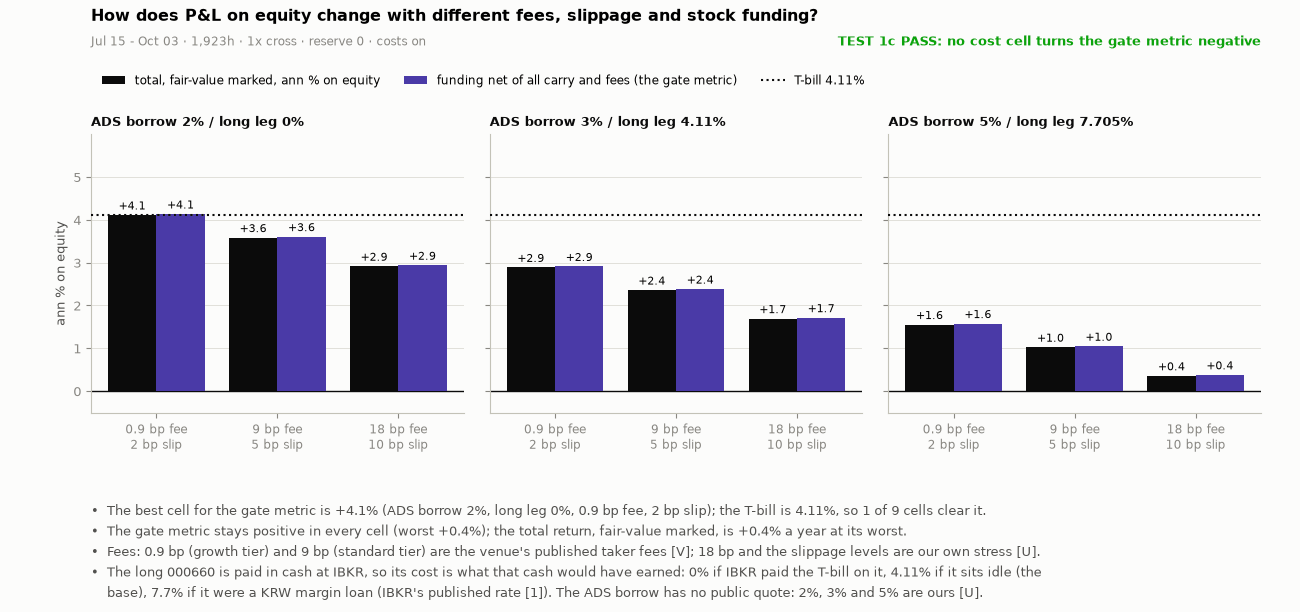

In [24]:
# ---- Test 1c: costs. Three stock-funding levels (ADS borrow / the long leg's cost) x three fee-and-slippage levels ----
FEES = ((refdata.XYZ_TAKER_BPS, 2.0, "growth-tier fee [V], 2 bp slip"), (refdata.XYZ_STANDARD_TAKER_BPS, 5.0, "standard fee [V], 5 bp slip"), (2 * refdata.XYZ_STANDARD_TAKER_BPS, 10.0, "2x standard fee, 10 bp slip [U]"))
FINS = ((0.02, 0.0), (0.03, refdata.HURDLE_ANN), (0.05, KRW_LOAN))      # cash earns the T-bill at IBKR | cash idle (the base) | a KRW margin loan at IBKR's published rate [1]
SW = {}
for b_, m_ in FINS:
    for f_, s_, _l in FEES:
        r_ = run4(rows, replace(PAR[BOOK], stock_fin_ann=m_, short_borrow_ann=b_, perp={"fee_taker_bps": f_, "exec_slippage_bps": s_}))
        vfour(r_, rows, f"cost sweep {f_:g}/{s_:g} {b_}/{m_}")
        assert (r_["fin_rates"]["short_borrow"], r_["fin_rates"]["long"]) == (b_, m_), r_["fin_rates"]
        SW[(b_, m_, f_, s_)] = r_
GATE = {k: carry_ann(r_) for k, r_ in SW.items()}; TOT = {k: fv_ann(r_) for k, r_ in SW.items()}      # the total is the FAIR-VALUE return; the gate metric does not depend on the mark
G2c = bool(min(GATE.values()) > 0)
n_clear = int(sum(v_ > HURDLE_PCT for v_ in GATE.values()))
kg = max(GATE, key=GATE.get); kw_ = min(TOT, key=TOT.get)
CB = [f"The best cell for the gate metric is {GATE[kg]:+.1f}% (ADS borrow {kg[0] * 100:g}%, long leg {kg[1] * 100:g}%, {kg[2]:g} bp fee, {kg[3]:g} bp slip); the T-bill is {HURDLE_PCT:.2f}%, so {n_clear} of {len(GATE)} cells clear it.",
      f"The gate metric stays " + ("positive" if G2c else "negative in at least one cell") + f" in every cell (worst {min(GATE.values()):+.1f}%); the total return, fair-value marked, is {TOT[kw_]:+.1f}% a year at its worst.",
      "Fees: 0.9 bp (growth tier) and 9 bp (standard tier) are the venue's published taker fees [V]; 18 bp and the slippage levels are our own stress [U].",
      "The long 000660 is paid in cash at IBKR, so its cost is what that cash would have earned: 0% if IBKR paid the T-bill on it, 4.11% if it sits idle (the base), 7.7% if it were a KRW margin loan (IBKR's published rate [1]). The ADS borrow has no public quote: 2%, 3% and 5% are ours [U]."]
H3x3 = 4.7 + figstyle.nlines(CB) * 0.205 + 0.4
fig, axs = plt.subplots(1, 3, figsize=(13, H3x3), sharey=True)
bm = figstyle.bullets(fig, CB)
for ax_, (b_, m_) in zip(axs, FINS):
    xs = np.arange(len(FEES)); vt = [TOT[(b_, m_, f_, s_)] for f_, s_, _ in FEES]; vg = [GATE[(b_, m_, f_, s_)] for f_, s_, _ in FEES]
    b1 = ax_.bar(xs - 0.2, vt, 0.4, color=INK, zorder=3); b2 = ax_.bar(xs + 0.2, vg, 0.4, color=C_NET, zorder=3)
    ax_.bar_label(b1, fmt="%+.1f", fontsize=8, padding=2); ax_.bar_label(b2, fmt="%+.1f", fontsize=8, padding=2)
    ax_.axhline(HURDLE_PCT, color=INK, linestyle=":", linewidth=1.5, zorder=4); ax_.axhline(0, color=INK, linewidth=1)
    ax_.set_xticks(xs); ax_.set_xticklabels([f"{f_:g} bp fee\n{s_:g} bp slip" for f_, s_, _ in FEES], fontsize=8.5); ax_.grid(axis="x", visible=False)
    ax_.set_title(f"ADS borrow {b_ * 100:g}% / long leg {m_ * 100:g}%", fontsize=9.5, loc="left", pad=6)
axs[0].set_ylim(min(0, min(TOT.values()) * 1.4) - 0.5, max(max(GATE.values()), max(TOT.values()), HURDLE_PCT) * 1.45)
axs[0].set_ylabel("ann % on equity")
fig.legend(handles=[Patch(facecolor=INK, label="total, fair-value marked, ann % on equity"), Patch(facecolor=C_NET, label="funding net of all carry and fees (the gate metric)"), plt.Line2D([], [], color=INK, linestyle=":", linewidth=1.5, label=f"T-bill {HURDLE_PCT:.2f}%")], loc="upper left", bbox_to_anchor=(0.07, 0.895), ncol=3, fontsize=8.5, frameon=False)
fig.suptitle("How does P&L on equity change with different fees, slippage and stock funding?", x=0.07, ha="left", fontsize=11.5, fontweight="bold", y=0.985)
fig.text(0.07, 0.925, f"{WSB}", color=MUTED, fontsize=8.5)
fig.text(0.97, 0.925, ("TEST 1c PASS: no cost cell turns the gate metric negative" if G2c else "TEST 1c FAIL: a cost cell turns the gate metric negative"), ha="right", color=(GOOD if G2c else CRIT), fontsize=9.5, fontweight="bold")
plt.subplots_adjust(top=0.78, bottom=bm + 0.75 / H3x3, left=0.07, right=0.97, wspace=0.07)
figstyle.show(fig, "fig:s4-costs", FIGURES)
# the borrow that WOULD clear the hurdle: the gate metric is linear in the borrow (asserted), then solved
BR, BRR = {}, {}
for f_ in (0.005, 0.03, 0.30):
    r_ = run4(rows, replace(PAR[BOOK], short_borrow_ann=f_)); vfour(r_, rows, f"borrow {f_}"); BR[f_] = carry_ann(r_); BRR[f_] = r_
assert abs(BR[0.03] - carry_ann(res)) < 1e-9
k_brw = (BR[0.30] - BR[0.005]) / (0.30 - 0.005)
assert abs(BR[0.03] - (BR[0.005] + k_brw * (0.03 - 0.005))) < 1e-9          # linear in the borrow
f_star = 0.005 + (HURDLE_PCT - BR[0.005]) / k_brw
ST4["costs"] = {"best_gate": GATE[kg], "worst_total": TOT[kw_],      # the totals are fair-value marked
                  "mark": "fair-value", "n_clear": n_clear, "n": len(GATE), "pass": G2c, "f_star_pct": f_star * 100, "borrow_slope_per_pct": k_brw / 100,
                  "cells": [{"borrow": b_, "margin": m_, "fee": f_, "slip": s_, "total": TOT[(b_, m_, f_, s_)], "gate": GATE[(b_, m_, f_, s_)]} for b_, m_ in FINS for f_, s_, _ in FEES]}

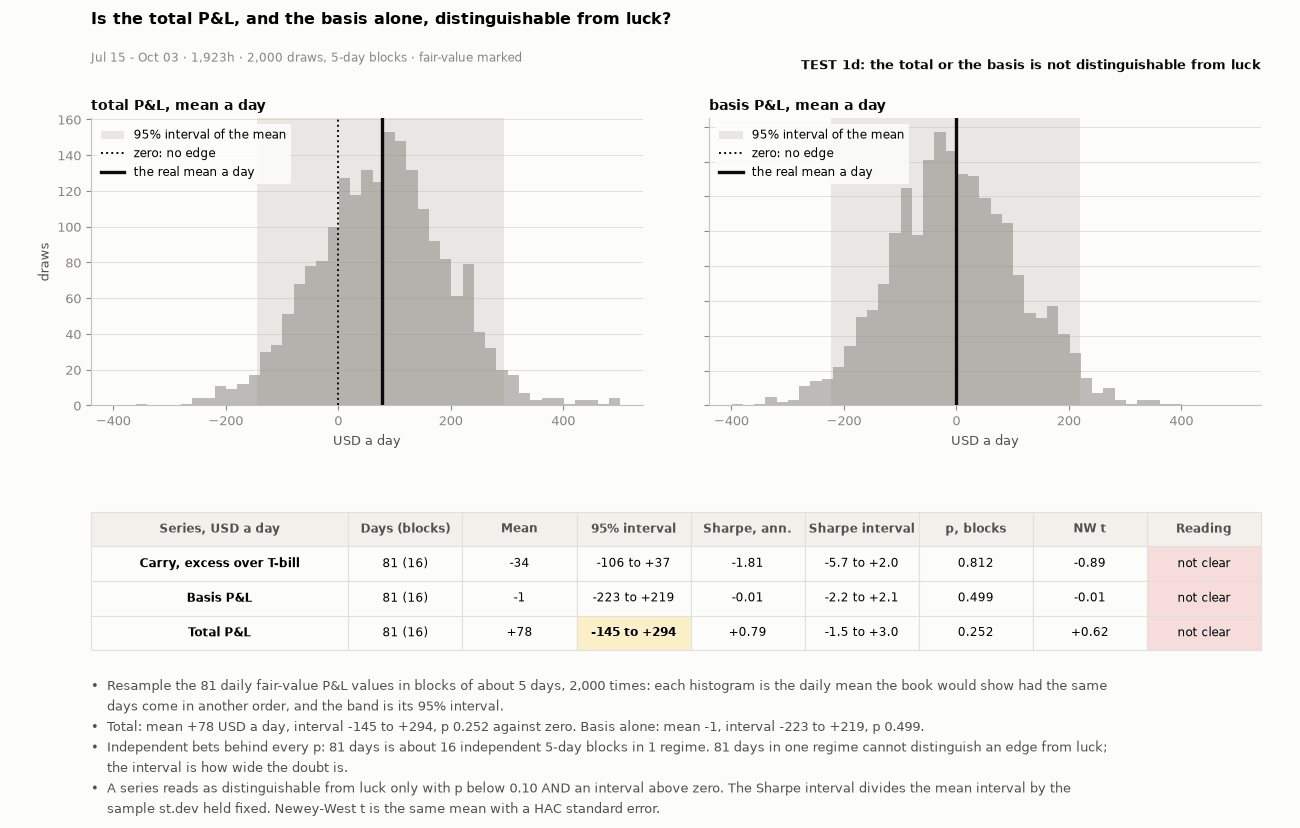

In [25]:
# ---- Test 1d: is the TOTAL P&L, and the BASIS alone, distinguishable from luck? A stationary (block) bootstrap on the daily fair-value P&L ----
gate_cum = (num(df["cum_funding_net"]) - num(df["cum_financing"]) - num(df["cum_stock_costs"]) - num(df["cum_perp_fees"]) + num(df["cum_dividends"]))
tot_fv_cum = pd.Series(res["series"]["total_pnl_fv"], index=df.index, dtype=float)
BASD = daily_cum(tot_fv_cum - gate_cum)               # the basis P&L per day, fair-value marked: the total less funding and every carry
CARD_ = DAY["funding_net_carry"]                      # funding net of all carry and fees per day: does not depend on the stock marks
assert float((BASD + CARD_ - DAYFV).abs().max()) < 1e-6, "the day grids of the basis, the carry and the total differ"
assert abs(float(DAYFV.sum()) - res["total_pnl_fv"]) < 1e-6
SERIES = [("Carry, excess over T-bill", CARD_.values - HURDLE_DAY, C_NET, "carry"), ("Basis P&L", BASD.values, C_PREM, "basis"), ("Total P&L", DAYFV.values, INK, "total")]
BT, N_DAYS = {}, len(DAYFV)
for k_, (nm_, x_, col_, key_) in enumerate(SERIES):
    x_ = np.asarray(x_, float)
    p_ = bt_["p"] if key_ == "carry" else ST.bootstrap_p_one_sided(list(x_), BOOT_BLOCK_D, NSHUF, np.random.default_rng(SEED + 10 + k_))["p"]    # the carry row IS Test 1b's block p
    means_ = np.asarray(ST.stationary_bootstrap_sums(list(x_), BOOT_BLOCK_D, NSHUF, np.random.default_rng(SEED + 20 + k_))) / len(x_)           # NOT centred: the spread of the daily mean
    lo_c, hi_c = ST.percentile(list(means_), 100 * (1 - CI_LEVEL) / 2), ST.percentile(list(means_), 100 * (1 + CI_LEVEL) / 2)
    sd_ = float(np.std(x_ / EQUITY, ddof=1)); rf_ = float(np.sqrt(365.0))
    nw_ = ST.newey_west(list(x_))
    BT[key_] = {"name": nm_, "n": len(x_), "blocks": len(x_) / BOOT_BLOCK_D, "mean": float(x_.mean()), "lo": float(lo_c), "hi": float(hi_c), "p": float(p_), "means": means_, "col": col_,
                "sharpe": float(ST.sharpe(list(x_ / EQUITY), 365)), "sharpe_lo": float(lo_c / EQUITY / sd_ * rf_), "sharpe_hi": float(hi_c / EQUITY / sd_ * rf_), "nw_t": float(nw_["t"]), "nw_p": float(nw_["p"]),
                "pass": bool(p_ < P_CUT and lo_c > 0)}
G_TOTAL, G_BASIS = BT["total"]["pass"], BT["basis"]["pass"]
BT["carry"]["pass"] = G2b
BUL = [f"Resample the {N_DAYS} daily fair-value P&L values in blocks of about {BOOT_BLOCK_D} days, {NSHUF:,} times: each histogram is the daily mean the book would show had the same days come in another order, and the band is its {CI_LEVEL * 100:.0f}% interval.",
       f"Total: mean {BT['total']['mean']:+,.0f} USD a day, interval {BT['total']['lo']:+,.0f} to {BT['total']['hi']:+,.0f}, p {BT['total']['p']:.3f} against zero. Basis alone: mean {BT['basis']['mean']:+,.0f}, interval {BT['basis']['lo']:+,.0f} to {BT['basis']['hi']:+,.0f}, p {BT['basis']['p']:.3f}.",
       f"Independent bets behind every p: {N_DAYS} days is about {N_DAYS / BOOT_BLOCK_D:.0f} independent {BOOT_BLOCK_D}-day blocks in {REGIMES} regime. {N_DAYS} days in one regime cannot distinguish an edge from luck; the interval is how wide the doubt is.",
       f"A series reads as distinguishable from luck only with p below {P_CUT:.2f} AND an interval above zero. The Sharpe interval divides the mean interval by the sample st.dev held fixed. Newey-West t is the same mean with a HAC standard error."]
fig, gs, ax, axt = fig_tab(6.6, (2.7, 1.3), top=0.82, hspace=0.5, nb=figstyle.nlines(BUL))
ax.axis("off"); sg_ = gs[0].subgridspec(1, 2, wspace=0.12); a1, a2 = fig.add_subplot(sg_[0]), fig.add_subplot(sg_[1])
lo_x = min(BT["total"]["means"].min(), BT["basis"]["means"].min(), 0.0); hi_x = max(BT["total"]["means"].max(), BT["basis"]["means"].max(), 0.0); pad_ = (hi_x - lo_x) * 0.05
for a_, key_, ttl in ((a1, "total", "total P&L, mean a day"), (a2, "basis", "basis P&L, mean a day")):
    b_ = BT[key_]
    a_.hist(b_["means"], bins=np.linspace(lo_x - pad_, hi_x + pad_, 50), color=MUTED, alpha=0.55, zorder=3)
    a_.axvspan(b_["lo"], b_["hi"], color=AXIS, alpha=0.35, linewidth=0, zorder=2, label=f"{CI_LEVEL * 100:.0f}% interval of the mean")
    a_.axvline(0, color=INK, linestyle=":", linewidth=1.4, zorder=4, label="zero: no edge")
    a_.axvline(b_["mean"], color=INK, linewidth=2.4, zorder=5, label="the real mean a day")
    a_.set_title(ttl, fontsize=10, loc="left", pad=6); a_.set_xlabel("USD a day"); a_.legend(loc="upper left", fontsize=8.3, **LEG); a_.grid(axis="x", visible=False); a_.set_xlim(lo_x - pad_, hi_x + pad_)
a1.set_ylabel("draws"); a2.tick_params(labelleft=False)
a1.text(1.0, 1.16, ("TEST 1d: total and basis are distinguishable from luck" if (G_TOTAL and G_BASIS) else "TEST 1d: the total or the basis is not distinguishable from luck"), transform=a2.transAxes, ha="right", va="bottom", color=INK, fontsize=9.5, fontweight="bold")
fig.suptitle("Is the total P&L, and the basis alone, distinguishable from luck?", x=0.07, ha="left", fontsize=11.5, fontweight="bold", y=0.985)
fig.text(0.07, 0.925, f"{WSH} · {NSHUF:,} draws, {BOOT_BLOCK_D}-day blocks · fair-value marked", color=MUTED, fontsize=8.5)
cells = [[b_["name"], f"{b_['n']} ({b_['blocks']:.0f})", f"{b_['mean']:+,.0f}", f"{b_['lo']:+,.0f} to {b_['hi']:+,.0f}", f"{b_['sharpe']:+.2f}", f"{b_['sharpe_lo']:+.1f} to {b_['sharpe_hi']:+.1f}", f"{b_['p']:.3f}", f"{b_['nw_t']:+.2f}", ("clear" if b_["pass"] else "not clear")] for b_ in (BT["carry"], BT["basis"], BT["total"])]
tb = put_table(axt, cells, ["Series, USD a day", "Days (blocks)", "Mean", f"{CI_LEVEL * 100:.0f}% interval", "Sharpe, ann.", "Sharpe interval", "p, blocks", "NW t", "Reading"], size=8.8, first=0.22)
for r_i in (1, 2, 3):
    tint(tb, r_i, 8, "green" if cells[r_i - 1][8] == "clear" else "rose")
gold(tb, 3, 3)
foot(fig, *BUL)
figstyle.show(fig, "fig:s4-bootstrap", FIGURES)
ST4.setdefault("gates", {}).update({"luck_total": G_TOTAL, "luck_basis": G_BASIS})        # readings, not gates: S7 prints them as INFO
ST4["boot"] = {k_: {kk: vv for kk, vv in v_.items() if kk not in ("means", "col")} for k_, v_ in BT.items()}
ST4["boot"]["n_days"], ST4["boot"]["block_d"], ST4["boot"]["regimes"] = N_DAYS, BOOT_BLOCK_D, REGIMES

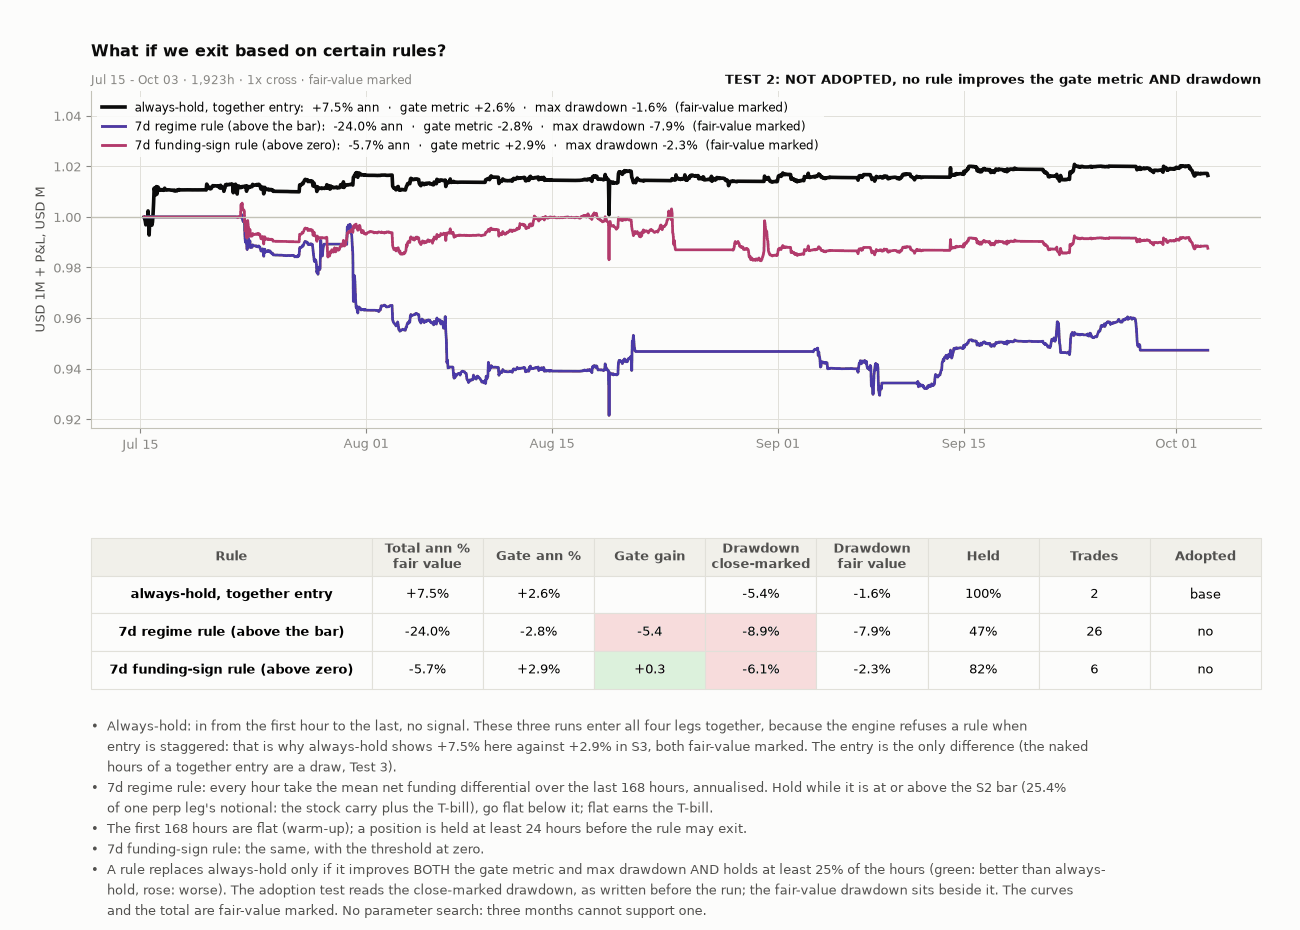

In [26]:
# ---- Test 2: a timing rule against always-hold (the engine refuses a rule when entry is staggered, so the three run together-entry) ----
RULES = {}
RULES["always-hold"] = run4(rows, replace(PAR[BOOK], entry_mode="together"))
for lab, kw in (("7d regime rule (above the bar)", dict(regime=True, regime_threshold_ann=BAR_LEG / 100.0)), ("7d funding-sign rule (above zero)", dict(regime=True, regime_threshold_ann=0.0))):      # the regime rule exits below the S2 bar, the gate's own: the engine's default basis counts more capital than the USD 1M of equity (hip3_four.py, thr = hurdle x cap / N + stock carry)
    r_ = run4(rows, replace(PAR[BOOK], entry_mode="together", **kw)); vfour(r_, rows, f"rule {lab}"); RULES[lab] = r_
base_ = RULES["always-hold"]
ADOPT = [lab for lab, r_ in RULES.items() if lab != "always-hold" and carry_ann(r_) > carry_ann(base_) and r_["max_drawdown_equity"] > base_["max_drawdown_equity"] and r_["hold_share"] >= MIN_HOLD_SHARE]
THR = RULES["7d regime rule (above the bar)"]["regime_threshold_ann_pct"]
assert abs(THR - BAR_LEG) < 1e-9, (THR, BAR_LEG)
fvdd_rule = lambda r_: float(((EQUITY + pd.Series(r_["series"]["total_pnl_fv"], dtype=float)) / (EQUITY + pd.Series(r_["series"]["total_pnl_fv"], dtype=float)).cummax() - 1).min() * 100)     # max drawdown on the fair-value mark, % of equity
disp = lambda lab_: "always-hold, together entry" if lab_ == "always-hold" else lab_
BUL = [f"Always-hold: in from the first hour to the last, no signal. These three runs enter all four legs together, because the engine refuses a rule when entry is staggered: that is why always-hold shows {fv_ann(base_):+.1f}% here against {FV_ANN:+.1f}% in S3, both fair-value marked. The entry is the only difference (the naked hours of a together entry are a draw, Test 3).",
       f"7d regime rule: every hour take the mean net funding differential over the last {p1.regime_warmup_h} hours, annualised. Hold while it is at or above the S2 bar ({THR:.1f}% of one perp leg's notional: the stock carry plus the T-bill), go flat below it; flat earns the T-bill.",
       f"The first {p1.regime_warmup_h} hours are flat (warm-up); a position is held at least {p1.min_hold_h} hours before the rule may exit.",
       "7d funding-sign rule: the same, with the threshold at zero.",
       f"A rule replaces always-hold only if it improves BOTH the gate metric and max drawdown AND holds at least {MIN_HOLD_SHARE * 100:.0f}% of the hours (green: better than always-hold, rose: worse). The adoption test reads the close-marked drawdown, as written before the run; the fair-value drawdown sits beside it. The curves and the total are fair-value marked. No parameter search: three months cannot support one."]
fig, gs, ax, axt = fig_tab(7.0, (2.9, 1.3), nb=figstyle.nlines(BUL))
styles = {"always-hold": (INK, 2.6), "7d regime rule (above the bar)": (C_NET, 2.0), "7d funding-sign rule (above zero)": (C_PREM_DK, 2.0)}      # three identity colours: the greys could not be told apart
for lab, r_ in RULES.items():
    d_ = frame(r_); c_, lw_ = styles[lab]
    ax.plot(d_.index, (EQUITY + num(d_["total_pnl_fv"])) / 1e6, color=c_, linewidth=lw_, label=f"{disp(lab)}:  {fv_ann(r_):+.1f}% ann  ·  gate metric {carry_ann(r_):+.1f}%  ·  max drawdown {fvdd_rule(r_):.1f}%  (fair-value marked)")
ax.axhline(1.0, color=AXIS, linewidth=1); ax.set_ylabel("USD 1M + P&L, USD M"); ax.legend(loc="upper left", fontsize=8.5, **LEG); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ylo, yhi = ax.get_ylim(); ax.set_ylim(ylo, yhi + (yhi - ylo) * 0.22)
ax.text(1.0, 1.012, ("TEST 2: a rule is ADOPTED" if ADOPT else "TEST 2: NOT ADOPTED, no rule improves the gate metric AND drawdown"), transform=ax.transAxes, ha="right", va="bottom", color=INK, fontsize=9.5, fontweight="bold")
ask(ax, "What if we exit based on certain rules?", f"{WSH} · 1x cross · fair-value marked")
cells = []
for lab, r_ in RULES.items():
    cells.append([disp(lab), f"{fv_ann(r_):+.1f}%", f"{carry_ann(r_):+.1f}%", ("" if lab == "always-hold" else f"{carry_ann(r_) - carry_ann(base_):+.1f}"), f"{r_['max_drawdown_equity'] * 100:.1f}%", f"{fvdd_rule(r_):.1f}%",
                  f"{r_['hold_share'] * 100:.0f}%", f"{r_['trades']}", ("base" if lab == "always-hold" else ("yes" if lab in ADOPT else "no"))])
tb = put_table(axt, cells, ["Rule", "Total ann %" + chr(10) + "fair value", "Gate ann %", "Gate gain", "Drawdown" + chr(10) + "close-marked", "Drawdown" + chr(10) + "fair value", "Held", "Trades", "Adopted"], size=9.0, first=0.24)
for r_i, (lab, r_) in enumerate(RULES.items(), 1):
    if lab != "always-hold":
        tint(tb, r_i, 4, "rose" if r_["max_drawdown_equity"] <= base_["max_drawdown_equity"] else "green")
        tint(tb, r_i, 3, "green" if carry_ann(r_) > carry_ann(base_) else "rose")
foot(fig, *BUL)
figstyle.show(fig, "fig:s4-rules", FIGURES)
ST4["rules"] = {"adopt": ADOPT, "thr_leg_pct": THR, "mark": "fair-value return; the adoption test reads the close-marked drawdown", "rows": [{"rule": lab, "ann": fv_ann(r_), "gate": carry_ann(r_), "dd": r_["max_drawdown_equity"] * 100, "dd_fv": fvdd_rule(r_), "held": r_["hold_share"] * 100, "trades": r_["trades"]} for lab, r_ in RULES.items()]}
ST4.setdefault("gates", {}).update({"base": G1a, "oos": G2a, "luck": G2b, "costs": G2c, "rules_adopted": bool(ADOPT)})
ST4["n_runs"] = 2 + 9 + 3 + 3

In [27]:
# ---- the grid runs: leverage x the broker-margin regime, each verified (information; one window re-sliced). They run here, before the S4 entry sweep; S6 and the Appendix read them ----
REGS = (("netted, 25%", True, 0.25), ("netted, 50%", True, 0.50), ("not netted, 25%", False, 0.25), ("not netted, 50%", False, 0.50))
GRM, NOFIT = {}, {}
for L in LEVS:
    for nm_, nt_, fr_ in REGS:
        need_ = ib_cash(L * EQUITY / 4.0, nt_, fr_) + 2 * (L * EQUITY / 4.0) / MAXLEV         # IBKR cash and margin, plus the perps' initial margin
        if need_ >= EQUITY:
            NOFIT[(L, nm_)] = need_                                                          # the equity cannot fund both accounts: not run
            continue
        r_ = run4(rows, fp(L, 0.0, BOOK, netting=nt_, frac=fr_)); c_ = vfour(r_, rows, f"grid {L}x {nm_}")
        assert len(c_) == NCHK, (L, nm_)
        GRM[(L, nm_)] = r_
def fvdd(r_):
    e_ = EQUITY + pd.Series(r_["series"]["total_pnl_fv"], dtype=float); return float((e_ / e_.cummax() - 1).min()) * 100
WRM = {k_: wick_room(r_, BOOK)[0] for k_, r_ in GRM.items()}
LIQM = {k_: bool(r_["liquidations"]) or (WRM[k_] is not None and WRM[k_] <= 0) for k_, r_ in GRM.items()}
IBC = {(L, nm_): ib_cash(GRM[(L, nm_)]["notional_usd"], nt_, fr_) for L in LEVS for nm_, nt_, fr_ in REGS if (L, nm_) in GRM}

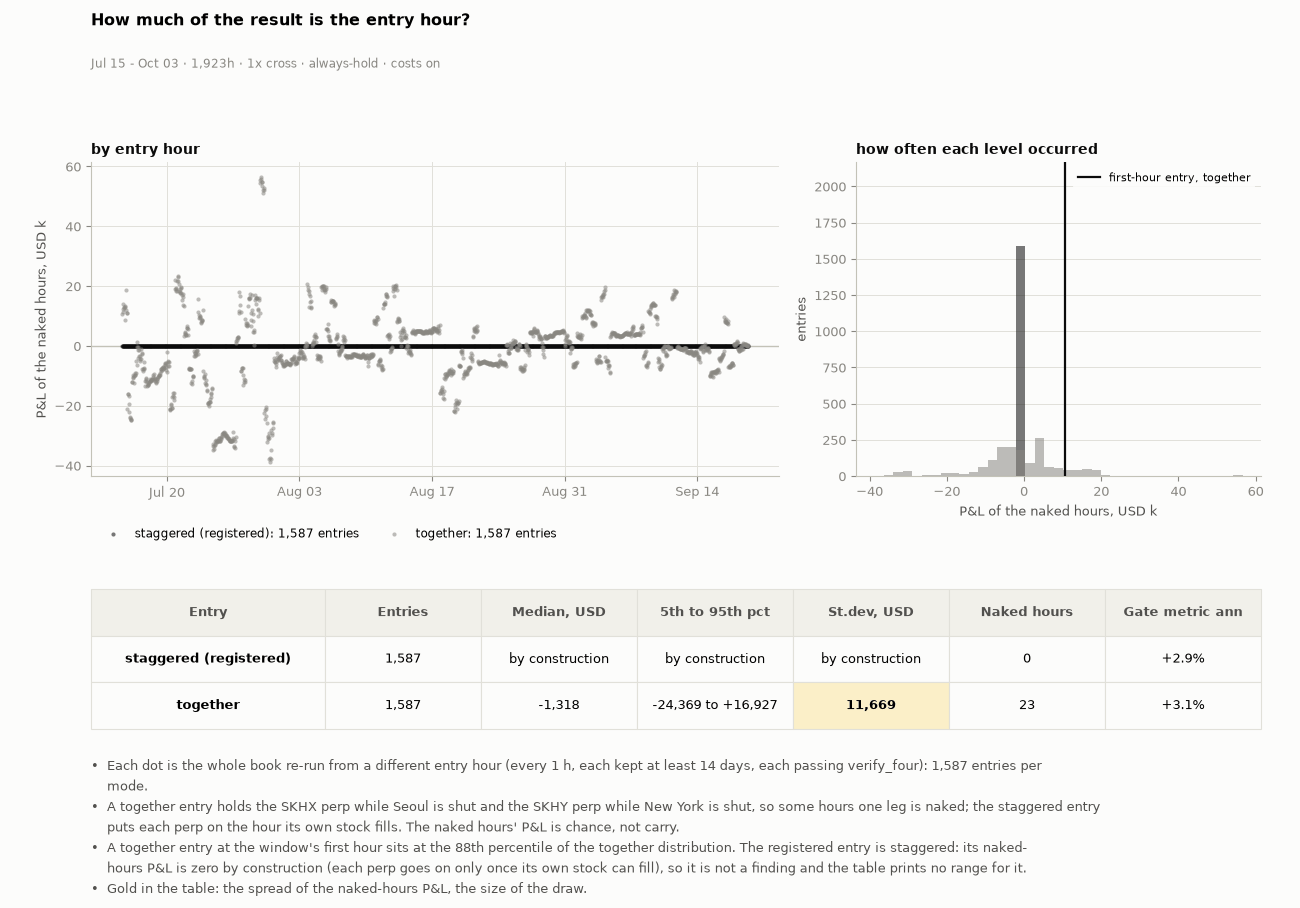

In [28]:
fig_tab, put_table, gold, tint = figstyle.fig_tab, figstyle.put_table, figstyle.gold, figstyle.tint
WSH = f"{df.index[0]:%b %d} - {df.index[-1]:%b %d} · {len(df):,}h"
SWR, FAIL = [], []
for em_ in (ENTRY_MODE, "together"):
    for k_ in range(0, len(rows) - 24 * SWEEP_MIN_D, int(os.environ.get("FUND_DEV_STEP", SWEEP_STEP_H))):      # FUND_DEV_STEP is a development switch: main() refuses to write the notebook when it is set
        rw_ = rows[k_:]
        r_ = run4(rw_, fp(d=BOOK, entry_mode=em_))
        bad_ = sorted({k: v for k, v in F.verify_four(r_, rw_).items() if not v[0]}.keys() - ENGINE_OPEN)
        t_ = pd.to_datetime(rw_[0]["time"], unit="ms", utc=True)
        if bad_:
            FAIL.append((em_, t_, bad_)); continue
        SWR.append({"mode": em_, "entry": t_, "hour": t_.hour, "unhedged": r_["unhedged_pnl"], "naked": max(r_["unhedged_hours_A"], r_["unhedged_hours_B"]), "gate": carry_ann(r_), "total": r_["total_pnl"]})
    SW_ = pd.DataFrame(SWR)
assert not FAIL, FAIL[:3]
reg = SW_[(SW_["mode"] == ENTRY_MODE)].iloc[0]; regT = SW_[(SW_["mode"] == "together")].iloc[0]
pct = lambda mode, v: float((SW_[SW_["mode"] == mode]["unhedged"] <= v).mean() * 100)
STAG0 = bool(SW_[SW_["mode"] == ENTRY_MODE]["unhedged"].abs().max() < 1e-6)      # the staggered entry holds no naked hour: its naked-hours P&L is exactly zero, by construction
BUL = [f"Each dot is the whole book re-run from a different entry hour (every {SWEEP_STEP_H} h, each kept at least {SWEEP_MIN_D} days, each passing verify_four): {len(SW_[SW_['mode'] == ENTRY_MODE]):,} entries per mode.",
       f"A together entry holds the SKHX perp while Seoul is shut and the SKHY perp while New York is shut, so some hours one leg is naked; the staggered entry puts each perp on the hour its own stock fills. The naked hours' P&L is chance, not carry.",
       f"A together entry at the window's first hour sits at the {pct('together', regT['unhedged']):.0f}th percentile of the together distribution. The registered entry is staggered: " + ("its naked-hours P&L is zero by construction (each perp goes on only once its own stock can fill), so it is not a finding and the table prints no range for it." if STAG0 else f"its naked-hours P&L has a median of {reg['unhedged']:+,.0f} in the first-hour run."),
       "Gold in the table: the spread of the naked-hours P&L, the size of the draw."]
fig, gs, ax, axt = fig_tab(7.4, (2.7, 1.2), top=0.78, hspace=0.5, nb=figstyle.nlines(BUL))
ax.axis("off")
sg = gs[0].subgridspec(1, 2, width_ratios=[1.7, 1], wspace=0.14)
a1, a2 = fig.add_subplot(sg[0]), fig.add_subplot(sg[1])
for em_, col, lab in ((ENTRY_MODE, INK, "staggered (registered)"), ("together", MUTED, "together")):
    s_ = SW_[SW_["mode"] == em_]
    a1.scatter(s_["entry"], s_["unhedged"] / 1e3, s=9, color=col, alpha=0.55, linewidths=0, zorder=3, label=f"{lab}: {len(s_):,} entries")
a1.axhline(0, color=AXIS, linewidth=1); a1.set_ylabel("P&L of the naked hours, USD k"); a1.legend(loc="upper left", bbox_to_anchor=(0.0, -0.13), ncol=2, fontsize=8.5, frameon=False)
a1.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO, interval=2)); a1.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
a1.set_title("by entry hour", fontsize=10, loc="left", pad=6)
lo_, hi_ = SW_["unhedged"].min() / 1e3, SW_["unhedged"].max() / 1e3
for em_, col in ((ENTRY_MODE, INK), ("together", MUTED)):
    s_ = SW_[SW_["mode"] == em_]["unhedged"] / 1e3
    a2.hist(s_, bins=np.linspace(lo_, hi_, 40), color=col, alpha=0.55, zorder=3)
a2.axvline(regT["unhedged"] / 1e3, color=INK, linewidth=1.6, zorder=5, label="first-hour entry, together")
a2.set_xlabel("P&L of the naked hours, USD k"); a2.set_ylabel("entries"); a2.set_ylim(top=a2.get_ylim()[1] * 1.3); a2.legend(loc="upper right", fontsize=8, **LEG); a2.grid(axis="x", visible=False)
a2.set_title("how often each level occurred", fontsize=10, loc="left", pad=6)
fig.suptitle("How much of the result is the entry hour?", x=0.07, ha="left", fontsize=11.5, fontweight="bold", y=0.985)
fig.text(0.07, 0.925, f"{WSH} · 1x cross · always-hold · costs on", color=MUTED, fontsize=8.5)
rowsT = []
for em_ in (ENTRY_MODE, "together"):
    s_ = SW_[SW_["mode"] == em_]
    by_construction = bool(em_ == ENTRY_MODE and STAG0)
    rowsT.append([("staggered (registered)" if em_ == ENTRY_MODE else "together"), f"{len(s_):,}", ("by construction" if by_construction else f"{s_['unhedged'].median():+,.0f}"),
                  ("by construction" if by_construction else f"{s_['unhedged'].quantile(0.05):+,.0f} to {s_['unhedged'].quantile(0.95):+,.0f}"), ("by construction" if by_construction else f"{s_['unhedged'].std():,.0f}"),
                  f"{s_['naked'].median():.0f}", f"{s_['gate'].median():+.1f}%"])
tb = put_table(axt, rowsT, ["Entry", "Entries", "Median, USD", "5th to 95th pct", "St.dev, USD", "Naked hours", "Gate metric ann"], size=9.5, first=0.2)
gold(tb, 2, 4)
figstyle.bullets(fig, BUL)
figstyle.show(fig, "fig:s4-entry", FIGURES)
S = {m: {"n": int(len(SW_[SW_["mode"] == m])), "median": float(SW_[SW_["mode"] == m]["unhedged"].median()), "p5": float(SW_[SW_["mode"] == m]["unhedged"].quantile(0.05)), "p95": float(SW_[SW_["mode"] == m]["unhedged"].quantile(0.95)),
         "sd": float(SW_[SW_["mode"] == m]["unhedged"].std()), "naked_med": float(SW_[SW_["mode"] == m]["naked"].median())} for m in (ENTRY_MODE, "together")}
S["registered_together_pct"] = pct("together", regT["unhedged"]); S["registered_together_value"] = float(regT["unhedged"]); S["n_runs"] = int(len(SW_)); S["staggered_by_construction"] = STAG0
ST4B = S

## S5 · Risk and diagnostics

How does each hedge behave, does the spread revert, and where does the P&L print twice?

In [29]:
fig_tab, put_table, gold, tint = figstyle.fig_tab, figstyle.put_table, figstyle.gold, figstyle.tint
ST5 = {}
WSH = f"{df.index[0]:%b %d} - {df.index[-1]:%b %d} · {len(df):,}h"
WSB = WSH + " · 1x cross · reserve 0 · costs on"
S_ = res["series"]; TT = S_["time"]
t0_, t1_ = TT[0], TT[-1]
hour_of = lambda s_: min((t for t in TT if t - HOUR < s_ <= t), default=None)
IDX = {t: i for i, t in enumerate(TT)}

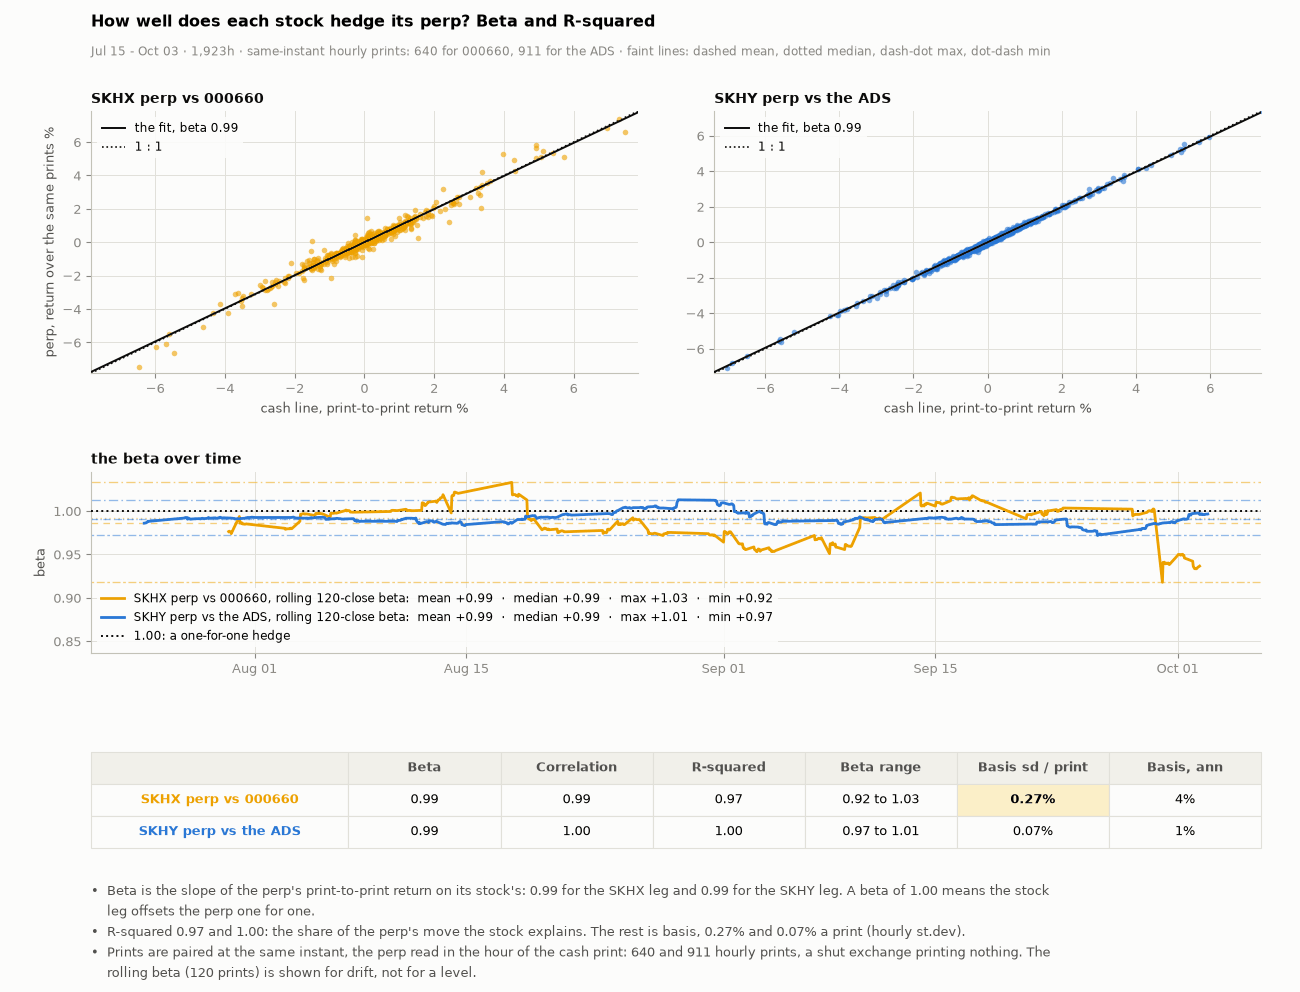

In [30]:
# ---- the same-instant pairs: at each cash close, the perp's USD price at that hour and the cash line's own close in USD ----
def pairs(marks, perp_key, fx_marks=None):
    out = []
    for st, px in marks:
        if not (t0_ <= st <= t1_):
            continue
        h_ = hour_of(st)
        if h_ is None:
            continue
        cash_ = px / asof(fx_marks, st) if fx_marks else px
        out.append((pd.Timestamp(st, unit="ms", tz="UTC"), cash_, S_[perp_key][IDX[h_]]))
    return pd.DataFrame(out, columns=["t", "cash", "perp"]).set_index("t")

PA, PB = pairs(MKH, "A_perp", MFH), pairs(MAH, "B_perp")
LEGS = (("A", "SKHX perp vs 000660", C_A, PA), ("B", "SKHY perp vs the ADS", C_B, PB))
HW = 120                                                                       # prints in the rolling window [U]
H = {}
for k, nm, col, P in LEGS:
    rc, rp = np.log(P["cash"]).diff().dropna(), np.log(P["perp"]).diff().dropna()
    beta, a0 = np.polyfit(rc, rp, 1)
    resid = rp - (a0 + beta * rc)
    r2 = float(1 - resid.var() / rp.var())
    rb = pd.Series(ST.rolling_slope(list(rp), list(rc), HW), index=rc.index).dropna()
    H[k] = {"rc": rc, "rp": rp, "beta": float(beta), "r2": r2, "corr": float(rc.corr(rp)), "resid_sd": float(resid.std() * 100), "n": int(len(rc)), "rb": rb, "te_ann": float(resid.std() * np.sqrt(252) * 100)}
bul = [f"Beta is the slope of the perp's print-to-print return on its stock's: {H['A']['beta']:.2f} for the SKHX leg and {H['B']['beta']:.2f} for the SKHY leg. A beta of 1.00 means the stock leg offsets the perp one for one.",
       f"R-squared {H['A']['r2']:.2f} and {H['B']['r2']:.2f}: the share of the perp's move the stock explains. The rest is basis, {H['A']['resid_sd']:.2f}% and {H['B']['resid_sd']:.2f}% a print (hourly st.dev).",
       f"Prints are paired at the same instant, the perp read in the hour of the cash print: {H['A']['n']} and {H['B']['n']} hourly prints, a shut exchange printing nothing. The rolling beta ({HW} prints) is shown for drift, not for a level."]
HH = 8.6 + figstyle.nlines(bul) * 0.205 + 0.3
fig = plt.figure(figsize=(13, HH))
bm = figstyle.bullets(fig, bul)
gs = fig.add_gridspec(3, 2, height_ratios=[2.6, 1.8, 0.95], hspace=0.55, wspace=0.14, left=0.07, right=0.97, top=1 - 0.13 * 8.6 / HH, bottom=bm + 0.02)
s0, s1 = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1]); rb_ax = fig.add_subplot(gs[1, :]); axt = fig.add_subplot(gs[2, :]); axt.axis("off")
for a_, (k, nm, col, P) in zip((s0, s1), LEGS):
    h = H[k]; lim = float(np.nanpercentile(np.abs(np.r_[h["rc"], h["rp"]]) * 100, 99.5)) * 1.05; xx = np.array([-lim, lim])
    a_.scatter(h["rc"] * 100, h["rp"] * 100, s=16, color=col, alpha=0.6, linewidths=0, zorder=3)
    a_.plot(xx, h["beta"] * xx, color=INK, linewidth=1.4, zorder=4, label=f"the fit, beta {h['beta']:.2f}"); a_.plot(xx, xx, color=INK, linewidth=1.2, linestyle=":", zorder=2, label="1 : 1")
    a_.set_xlim(-lim, lim); a_.set_ylim(-lim, lim); a_.set_xlabel("cash line, print-to-print return %"); a_.legend(loc="upper left", fontsize=8.5, **LEG)
    a_.set_title(nm, fontsize=10, loc="left", pad=6)
s0.set_ylabel("perp, return over the same prints %")
for k, nm, col, P in LEGS:
    rb = H[k]["rb"]; rb_ax.plot(rb.index, rb, color=col, linewidth=2.0, zorder=4)
    v_ = figstyle.stat_lines(rb_ax, rb, col, with_min=True); rb_ax.plot([], [], color=col, linewidth=2.0, label=figstyle.tag(f"{nm}, rolling {HW}-close beta", v_, 2))
rb_ax.axhline(1.0, color=INK, linestyle=":", linewidth=1.4, zorder=3); rb_ax.plot([], [], color=INK, linestyle=":", linewidth=1.4, label="1.00: a one-for-one hedge")
rb_ax.set_ylabel("beta"); rb_ax.legend(loc="lower left", fontsize=8.3, ncol=1, **LEG); rb_ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
yl = rb_ax.get_ylim(); rb_ax.set_ylim(yl[0] - (yl[1] - yl[0]) * 0.6, yl[1] + (yl[1] - yl[0]) * 0.05)
rb_ax.set_title("the beta over time", fontsize=10, loc="left", pad=6)
fig.suptitle("How well does each stock hedge its perp? Beta and R-squared", x=0.07, ha="left", fontsize=11.5, fontweight="bold", y=0.985)
fig.text(0.07, 1 - 0.065 * 8.6 / HH, f"{WSH} · same-instant hourly prints: {H['A']['n']} for 000660, {H['B']['n']} for the ADS · faint lines: dashed mean, dotted median, dash-dot max, dot-dash min", color=MUTED, fontsize=8.5)
cells = [[nm, f"{H[k]['beta']:.2f}", f"{H[k]['corr']:.2f}", f"{H[k]['r2']:.2f}", f"{H[k]['rb'].min():.2f} to {H[k]['rb'].max():.2f}", f"{H[k]['resid_sd']:.2f}%", f"{H[k]['te_ann']:.0f}%"] for k, nm, col, P in LEGS]
tb = put_table(axt, cells, ["", "Beta", "Correlation", "R-squared", "Beta range", "Basis sd / print", "Basis, ann"], size=9.5, first=0.22)
for r_i, (k, nm, col, P) in enumerate(LEGS, 1):
    tb[(r_i, 0)].set_text_props(color=col, weight="bold")
loose = 0 if H["A"]["resid_sd"] >= H["B"]["resid_sd"] else 1
gold(tb, loose + 1, 5)
figstyle.show(fig, "fig:s5-hedge", FIGURES)
ST5["hedge"] = {k: {kk: (float(vv) if not hasattr(vv, "index") else None) for kk, vv in H[k].items() if kk not in ("rc", "rp", "rb")} | {"rb_min": float(H[k]["rb"].min()), "rb_max": float(H[k]["rb"].max()), "rb_median": float(H[k]["rb"].median())} for k in H}

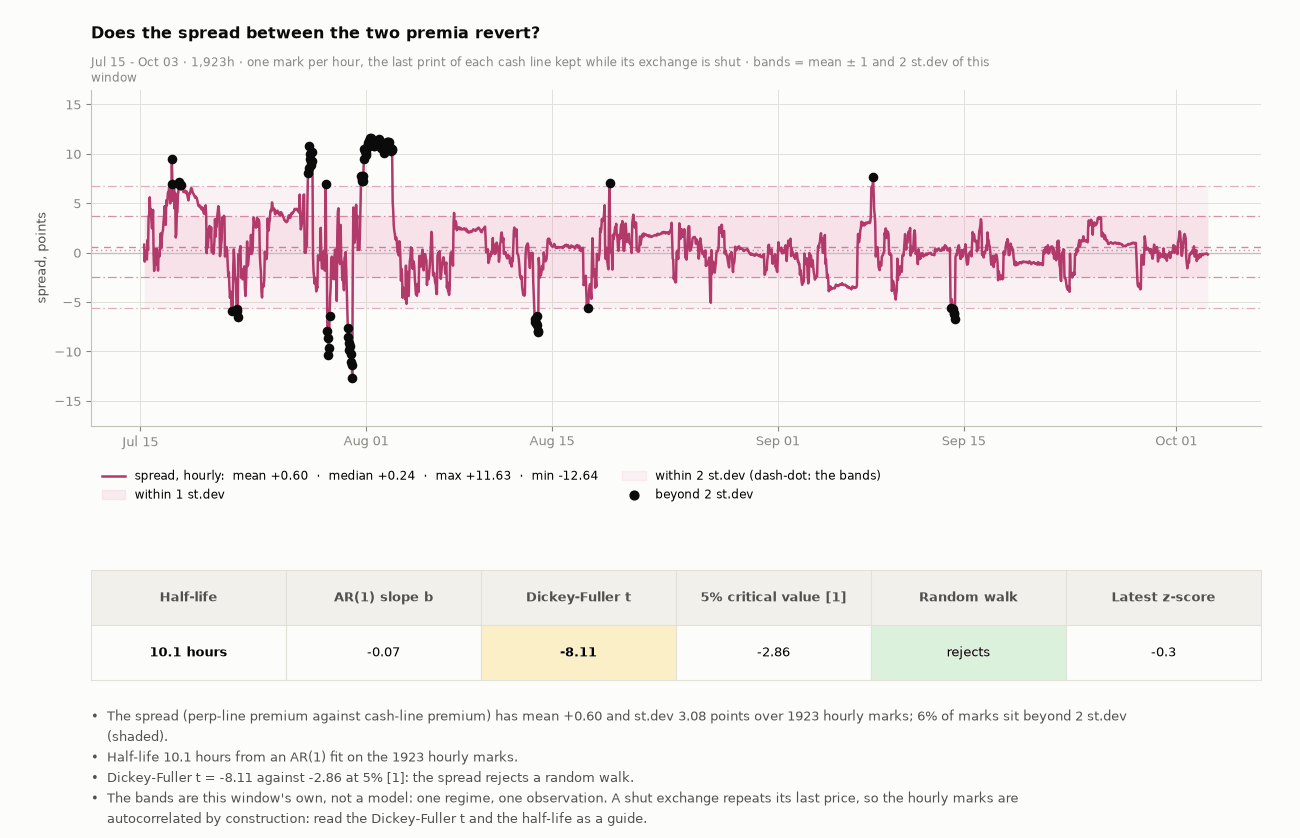

In [31]:
# ---- the spread at the same-instant marks, its z-score bands, half-life and Dickey-Fuller t ----
CX, DY, PYv, CYv = [], [], [], []
RT_ = {r_["time"]: r_ for r_ in rows}
for i_, st in enumerate(TT):
    kpx, a_, f_ = asof(MKH, st), asof(MAH, st), asof(MFH, st)          # hourly, a shut exchange keeps its last price
    if not (kpx and a_ and f_):
        continue
    kusd_ = kpx / f_
    cp_ = 10.0 * a_ / kusd_ * 100.0 - 100.0; pp_ = 10.0 * RT_[st]["B_perp"] / RT_[st]["A_perp"] * 100.0 - 100.0
    CX.append(pd.Timestamp(st, unit="ms", tz="UTC")); DY.append(((1 + pp_ / 100) / (1 + cp_ / 100) - 1) * 100); PYv.append(pp_); CYv.append(cp_)
SPD = pd.Series(DY, index=CX)
mu, sd = float(SPD.mean()), float(SPD.std())
y, x = SPD.diff().dropna().values, SPD.shift(1).dropna().values
X = np.c_[np.ones(len(x)), x]; coef, *_ = np.linalg.lstsq(X, y, rcond=None); resid = y - X @ coef
se_b = float(np.sqrt(resid.var(ddof=2) * np.linalg.inv(X.T @ X)[1, 1])); b_ = float(coef[1]); t_df = b_ / se_b
HL = float(-np.log(2) / np.log(1 + b_)) if -1 < b_ < 0 else (0.0 if b_ <= -1 else float("inf"))      # b below -1: the spread overshoots, it is gone within one mark
DF_CRIT = -2.86                                      # Dickey-Fuller 5% critical value with a constant, large sample [1] (MacKinnon table)
z = (SPD - mu) / sd
bul = [f"The spread (perp-line premium against cash-line premium) has mean {mu:+.2f} and st.dev {sd:.2f} points over {len(SPD)} hourly marks; {float((z.abs() > 2).mean() * 100):.0f}% of marks sit beyond 2 st.dev (shaded).",
       (f"Half-life {HL:.1f} hours from an AR(1) fit on the {len(SPD)} hourly marks." if 0 < HL < 1e6 else ("The AR(1) slope is below -1: the spread overshoots, so it is gone within one mark. It behaves like noise around zero, not like a slow reversion." if HL == 0.0 else "The AR(1) fit shows no mean reversion in this window.")),
       f"Dickey-Fuller t = {t_df:.2f} against {DF_CRIT} at 5% [1]: " + ("the spread rejects a random walk." if t_df < DF_CRIT else "it does NOT reject a random walk, so reversion is not established on this window."),
       "The bands are this window's own, not a model: one regime, one observation. A shut exchange repeats its last price, so the hourly marks are autocorrelated by construction: read the Dickey-Fuller t and the half-life as a guide."]
HS5 = 6.9 + figstyle.nlines(bul) * 0.205 + 0.3
fig, gs, ax, axt = fig_tab(6.9, (2.9, 0.95), hspace=0.65, nb=figstyle.nlines(bul))
ax.fill_between(SPD.index, mu - 2 * sd, mu + 2 * sd, color=C_PREM, alpha=0.08, linewidth=0, zorder=1); ax.fill_between(SPD.index, mu - sd, mu + sd, color=C_PREM, alpha=0.12, linewidth=0, zorder=1)
ax.plot(SPD.index, SPD, color=C_PREM_DK, linewidth=1.8, zorder=4)
for k_, yv in (("mean", mu), ("median", float(SPD.median()))):
    ax.axhline(yv, color=C_PREM_DK, linewidth=1.0, linestyle=figstyle.LS[k_], alpha=0.6, zorder=2)
for m_, a_ in ((1, 0.55), (2, 0.4)):
    for sg in (-1, 1):
        ax.axhline(mu + sg * m_ * sd, color=C_PREM_DK, linewidth=0.9, linestyle=figstyle.LS["max"], alpha=a_, zorder=2)
ob = SPD[z.abs() > 2]
ax.scatter(ob.index, ob, s=48, color=INK, zorder=6, linewidths=0)
ax.axhline(0, color=AXIS, linewidth=1, zorder=1); ax.set_ylabel("spread, points")
ax.plot([], [], color=C_PREM_DK, linewidth=1.8, label=figstyle.tag("spread, hourly", {"mean": mu, "median": float(SPD.median()), "max": float(SPD.max()), "min": float(SPD.min())}, 2))
ax.fill_between([], [], color=C_PREM, alpha=0.12, label="within 1 st.dev"); ax.fill_between([], [], color=C_PREM, alpha=0.08, label="within 2 st.dev (dash-dot: the bands)")
ax.scatter([], [], s=40, color=INK, label="beyond 2 st.dev"); ax.legend(loc="upper left", bbox_to_anchor=(0.0, -0.1), ncol=2, fontsize=8.5, frameon=False); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
yf = figstyle.yfit; yf(ax, [SPD], pad=0.2)
ask(ax, "Does the spread between the two premia revert?", f"{WSH} · one mark per hour, the last print of each cash line kept while its exchange is shut · bands = mean ± 1 and 2 st.dev of this window")
cells = [[(f"{HL:.1f} hours" if 0 < HL < 1e6 else ("under 1 mark" if HL == 0.0 else "none")), f"{b_:+.2f}", f"{t_df:.2f}", f"{DF_CRIT}", ("rejects" if t_df < DF_CRIT else "does not reject"), f"{float(z.iloc[-1]):+.1f}"]]
tb = put_table(axt, cells, ["Half-life", "AR(1) slope b", "Dickey-Fuller t", "5% critical value [1]", "Random walk", "Latest z-score"], size=9.5)
gold(tb, 1, 2); tint(tb, 1, 4, "green" if t_df < DF_CRIT else "rose")
figstyle.bullets(fig, bul)
figstyle.show(fig, "fig:s5-spread", FIGURES)
ST5["spread"] = {"n": int(len(SPD)), "mean": mu, "sd": sd, "half_life_d": HL, "b": b_, "t_df": t_df, "df_crit": DF_CRIT, "reject": bool(t_df < DF_CRIT), "share_beyond_2sd": float((z.abs() > 2).mean() * 100), "z_last": float(z.iloc[-1]),
                   "min": float(SPD.min()), "max": float(SPD.max())}

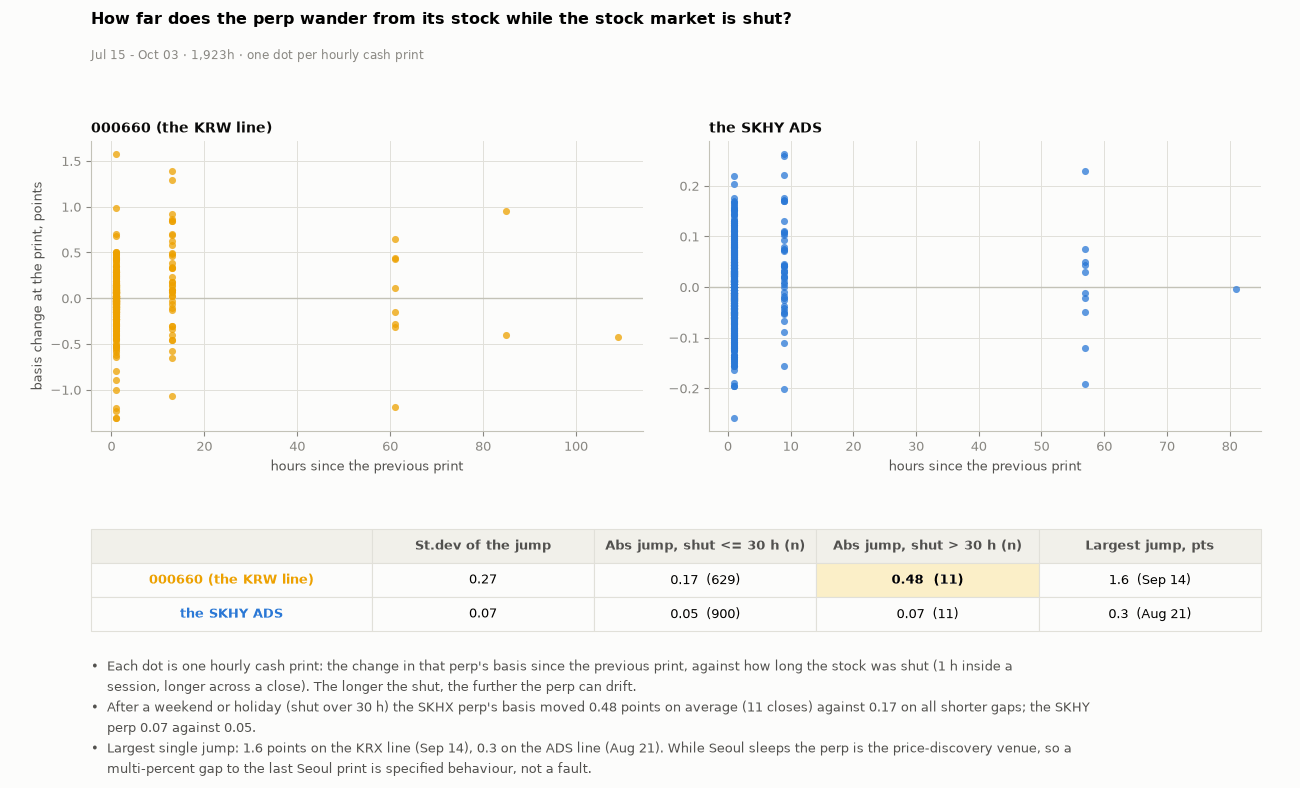

In [32]:
# ---- while a cash market is shut: how far the perp wanders from it, and the jump at the reopen ----
def reopen_jumps(marks, perp_key, fx_marks=None):
    out, prev = [], None
    for st, px in marks:
        if not (t0_ <= st <= t1_):
            continue
        h_ = hour_of(st)
        if h_ is None:
            continue
        cash_ = px / asof(fx_marks, st) if fx_marks else px
        b_ = (S_[perp_key][IDX[h_]] / cash_ - 1) * 100
        if prev is not None:
            out.append({"close": pd.Timestamp(st, unit="ms", tz="UTC"), "shut_h": (st - prev[0]) / HOUR, "jump": b_ - prev[1]})
        prev = (st, b_)
    return pd.DataFrame(out)

RJ = {"A": reopen_jumps(MKH, "A_perp", MFH), "B": reopen_jumps(MAH, "B_perp")}
NAMES2 = {"A": "000660 (the KRW line)", "B": "the SKHY ADS"}
COL2 = {"A": C_A, "B": C_B}
SH = {}
for k, d in RJ.items():
    lng = d[d["shut_h"] > 30]["jump"].abs(); sht = d[d["shut_h"] <= 30]["jump"].abs()
    SH[k] = {"sd": float(d["jump"].std()), "long_mean": float(lng.mean()) if len(lng) else float("nan"), "short_mean": float(sht.mean()), "n_long": int(len(lng)), "n_short": int(len(sht)), "worst": float(d["jump"].abs().max()), "worst_day": f"{d.loc[d['jump'].abs().idxmax(), 'close']:%b %d}"}
bul = [f"Each dot is one hourly cash print: the change in that perp's basis since the previous print, against how long the stock was shut (1 h inside a session, longer across a close). The longer the shut, the further the perp can drift.",
       f"After a weekend or holiday (shut over 30 h) the SKHX perp's basis moved {SH['A']['long_mean']:.2f} points on average ({SH['A']['n_long']} closes) against {SH['A']['short_mean']:.2f} on all shorter gaps; the SKHY perp {SH['B']['long_mean']:.2f} against {SH['B']['short_mean']:.2f}.",
       f"Largest single jump: {SH['A']['worst']:.1f} points on the KRX line ({SH['A']['worst_day']}), {SH['B']['worst']:.1f} on the ADS line ({SH['B']['worst_day']}). While Seoul sleeps the perp is the price-discovery venue, so a multi-percent gap to the last Seoul print is specified behaviour, not a fault."]
fig, gs, ax, axt = fig_tab(6.4, (2.7, 0.95), top=0.78, hspace=0.5, nb=figstyle.nlines(bul))
ax.axis("off"); sg = gs[0].subgridspec(1, 2, wspace=0.12); a0, a1 = fig.add_subplot(sg[0]), fig.add_subplot(sg[1])
for a_, k in ((a0, "A"), (a1, "B")):
    d = RJ[k]; a_.scatter(d["shut_h"], d["jump"], s=26, color=COL2[k], alpha=0.75, linewidths=0, zorder=3); a_.axhline(0, color=AXIS, linewidth=1)
    a_.set_xlabel("hours since the previous print"); a_.set_title(NAMES2[k], fontsize=10, loc="left", pad=6); a_.grid(True)
a0.set_ylabel("basis change at the print, points")
fig.suptitle("How far does the perp wander from its stock while the stock market is shut?", x=0.07, ha="left", fontsize=11.5, fontweight="bold", y=0.985)
fig.text(0.07, 0.925, f"{WSH} · one dot per hourly cash print", color=MUTED, fontsize=8.5)
cells = [[NAMES2[k], f"{SH[k]['sd']:.2f}", f"{SH[k]['short_mean']:.2f}  ({SH[k]['n_short']})", f"{SH[k]['long_mean']:.2f}  ({SH[k]['n_long']})", f"{SH[k]['worst']:.1f}  ({SH[k]['worst_day']})"] for k in ("A", "B")]
tb = put_table(axt, cells, ["", "St.dev of the jump", "Abs jump, shut <= 30 h (n)", "Abs jump, shut > 30 h (n)", "Largest jump, pts"], size=9.2, first=0.24)
for r_i, k in enumerate(("A", "B"), 1): tb[(r_i, 0)].set_text_props(color=COL2[k], weight="bold")
gold(tb, 1 if SH["A"]["long_mean"] >= SH["B"]["long_mean"] else 2, 3)
figstyle.bullets(fig, bul)
figstyle.show(fig, "fig:s5-shut", FIGURES)
ST5["shut"] = SH

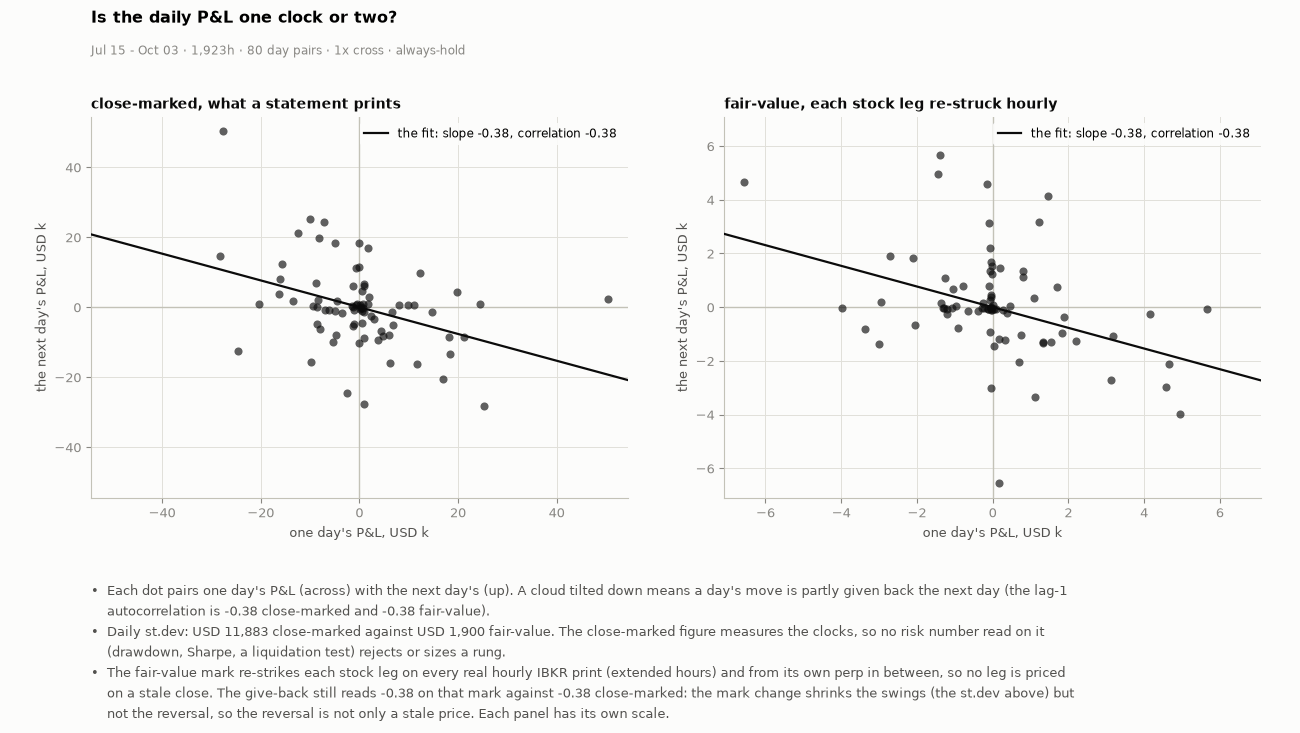

In [33]:
# ---- one clock or two: today's daily P&L against tomorrow's, close-marked and fair-value ----
FVs = pd.Series(S_["total_pnl_fv"], index=df.index, dtype=float)
dcl, dfv = DAYS_[BOOK]["total"], daily_cum(FVs)
bul_stats = {}
for nm, s in (("close-marked", dcl), ("fair-value", dfv)):
    a_, b_ = s.iloc[:-1].values, s.iloc[1:].values
    bul_stats[nm] = {"ac": float(np.corrcoef(a_, b_)[0, 1]), "slope": float(np.polyfit(a_, b_, 1)[0]), "sd": float(s.std()), "n": int(len(a_))}
wk = pd.DataFrame({"s": dcl, "dow": dcl.index.dayofweek})
wk_sd = {"weekday": float(wk[wk["dow"] < 5]["s"].std()), "weekend": float(wk[wk["dow"] >= 5]["s"].std())}
AC_CL, AC_FV = bul_stats["close-marked"]["ac"], bul_stats["fair-value"]["ac"]
HALF = 0.5       # [U] the give-back counts as mostly a stale price when the fair-value autocorrelation is under this share of the close-marked one
bul = [f"Each dot pairs one day's P&L (across) with the next day's (up). A cloud tilted down means a day's move is partly given back the next day (the lag-1 autocorrelation is {AC_CL:+.2f} close-marked and {AC_FV:+.2f} fair-value).",
       f"Daily st.dev: USD {bul_stats['close-marked']['sd']:,.0f} close-marked against USD {bul_stats['fair-value']['sd']:,.0f} fair-value. The close-marked figure measures the clocks, so no risk number read on it (drawdown, Sharpe, a liquidation test) rejects or sizes a rung.",
       "The fair-value mark re-strikes each stock leg on every real hourly IBKR print (extended hours) and from its own perp in between, so no leg is priced on a stale close. "
       + (f"The give-back reads {AC_FV:+.2f} on that mark against {AC_CL:+.2f} close-marked, so most of it was a stale price." if abs(AC_FV) < HALF * abs(AC_CL)
          else f"The give-back still reads {AC_FV:+.2f} on that mark against {AC_CL:+.2f} close-marked: the mark change shrinks the swings (the st.dev above) but not the reversal, so the reversal is not only a stale price. Each panel has its own scale.")]
HP5 = 5.6 + figstyle.nlines(bul) * 0.205 + 0.3
fig, axs = plt.subplots(1, 2, figsize=(13, HP5))
bm = figstyle.bullets(fig, bul)
for a_, (nm, s) in zip(axs, (("close-marked, what a statement prints", dcl), ("fair-value, each stock leg re-struck hourly", dfv))):
    key = "close-marked" if nm.startswith("close") else "fair-value"
    lim = float(s.abs().max() / 1e3) * 1.08          # each panel on its own scale: the fair-value cloud is a fraction of the close-marked one
    a_.scatter(s.iloc[:-1] / 1e3, s.iloc[1:] / 1e3, s=34, color=INK, alpha=0.65, linewidths=0, zorder=3)
    xx = np.array([-lim, lim]); a_.plot(xx, bul_stats[key]["slope"] * xx, color=INK, linewidth=1.6, zorder=4, label=f"the fit: slope {bul_stats[key]['slope']:+.2f}, correlation {bul_stats[key]['ac']:+.2f}")
    a_.axhline(0, color=AXIS, linewidth=1); a_.axvline(0, color=AXIS, linewidth=1)
    a_.set_xlim(-lim, lim); a_.set_ylim(-lim, lim); a_.set_xlabel("one day's P&L, USD k"); a_.set_ylabel("the next day's P&L, USD k"); a_.legend(loc="upper right", fontsize=8.5, **LEG); a_.set_title(nm, fontsize=10, loc="left", pad=6)
fig.suptitle("Is the daily P&L one clock or two?", x=0.07, ha="left", fontsize=11.5, fontweight="bold", y=0.985)
fig.text(0.07, 0.925, f"{WSH} · {bul_stats['close-marked']['n']} day pairs · 1x cross · always-hold", color=MUTED, fontsize=8.5)
plt.subplots_adjust(top=0.84, bottom=bm + 0.7 / HP5, left=0.07, right=0.97, wspace=0.18)
figstyle.show(fig, "fig:s5-clocks", FIGURES)
ST5["clocks"] = {**bul_stats, "wk": wk_sd, "stale_price_share": (None if not AC_CL else float(AC_FV / AC_CL))}

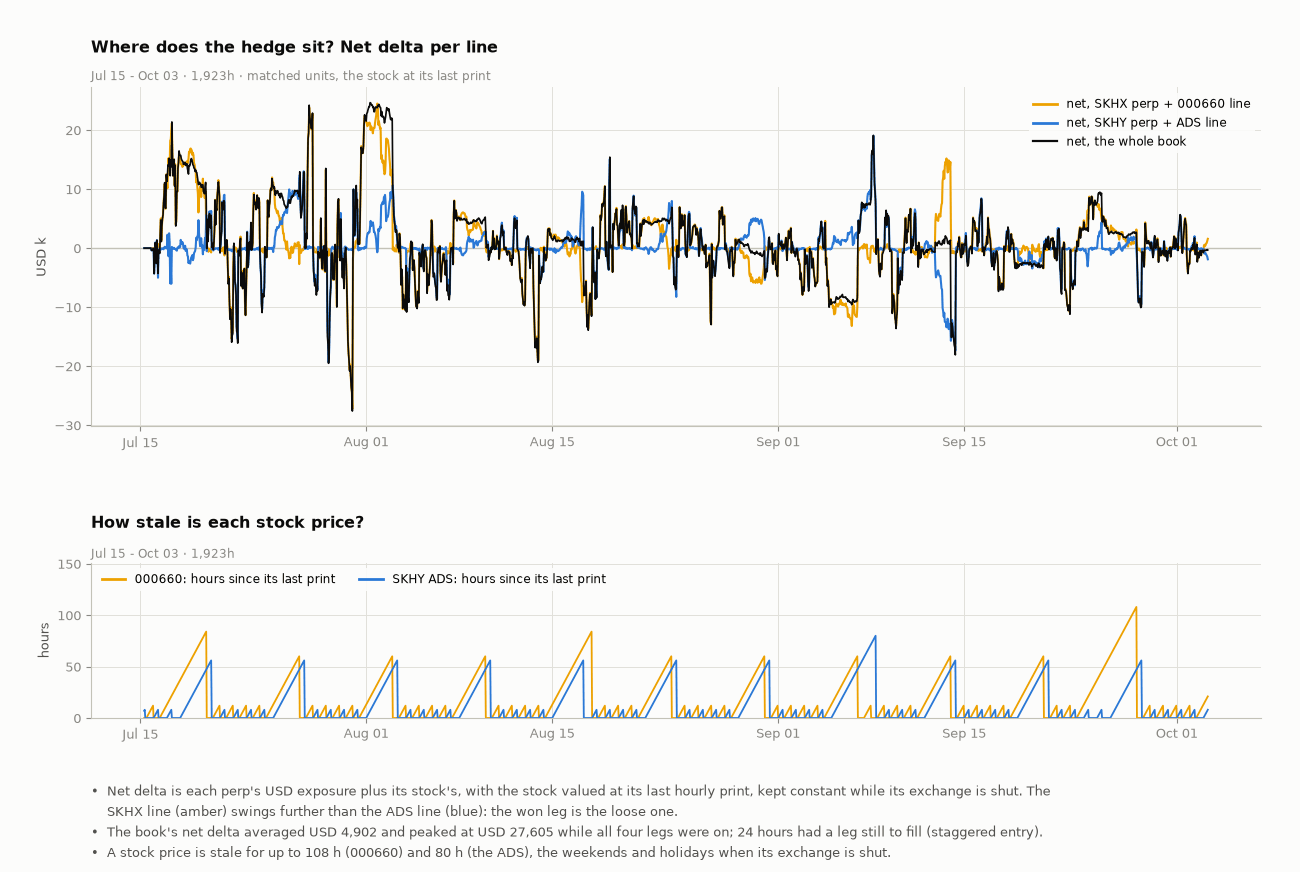

In [34]:
# ---- where the hedge sits: net delta per line (the perp against its own stock at its last close) and how stale each stock price is ----
sgn_ = SIDE[BOOK]
EXPO = pd.DataFrame({
    "SKHX perp": [sgn_ * q * a for q, a in zip(S_["target_units_A"], S_["A_perp"])],
    "000660 shares": [-sgn_ * q * (asof(MKH, t) or 0.0) / (asof(MFH, t) or 1.0) for q, t in zip(S_["qty_krx"], TT)],
    "SKHY perp": [-sgn_ * q * b for q, b in zip(S_["target_units_B"], S_["B_perp"])],
    "SKHY ADS": [sgn_ * q * (asof(MAH, t) or 0.0) for q, t in zip(S_["qty_ads"], TT)]}, index=df.index)
EXPO["net_A"] = EXPO["SKHX perp"] + EXPO["000660 shares"]; EXPO["net_B"] = EXPO["SKHY perp"] + EXPO["SKHY ADS"]; EXPO["net"] = EXPO["net_A"] + EXPO["net_B"]
EXPO = EXPO.iloc[:-1]                      # the last hour is the forced exit: the stock quantities are already zero while the perp targets are not
def last_stamp(marks, t):
    v = None
    for s_, _ in marks:
        if s_ <= t: v = s_
        else: break
    return v
STALE = pd.DataFrame({"A": [(t - (last_stamp(MKH, t) or t)) / HOUR for t in TT], "B": [(t - (last_stamp(MAH, t) or t)) / HOUR for t in TT]}, index=df.index)
both_on = ((num(df["on_A"]) > 0) & (num(df["on_B"]) > 0)).iloc[:-1]
STALE = STALE.iloc[:-1]
naked_h = int((~both_on).sum())
bul = [f"Net delta is each perp's USD exposure plus its stock's, with the stock valued at its last hourly print, kept constant while its exchange is shut. The SKHX line (amber) swings further than the ADS line (blue): the won leg is the loose one.",
       f"The book's net delta averaged USD {EXPO['net'].where(both_on).abs().mean():,.0f} and peaked at USD {EXPO['net'].where(both_on).abs().max():,.0f} while all four legs were on; {naked_h} hours had a leg still to fill (staggered entry).",
       f"A stock price is stale for up to {STALE['A'].max():.0f} h (000660) and {STALE['B'].max():.0f} h (the ADS), the weekends and holidays when its exchange is shut."]
HX = 7.6 + figstyle.nlines(bul) * 0.205 + 0.3
fig, (x1, x2) = plt.subplots(2, 1, figsize=(13, HX), gridspec_kw={"height_ratios": [2.4, 1.1]})
bm = figstyle.bullets(fig, bul)
for k_, col, lw_ in (("net_A", C_A, 1.5), ("net_B", C_B, 1.5), ("net", INK, 1.2)):
    x1.plot(EXPO.index, EXPO[k_] / 1e3, color=col, linewidth=lw_, zorder=4 if k_ == "net" else 3)
x1.plot([], [], color=C_A, linewidth=2.0, label="net, SKHX perp + 000660 line"); x1.plot([], [], color=C_B, linewidth=2.0, label="net, SKHY perp + ADS line"); x1.plot([], [], color=INK, linewidth=1.6, label="net, the whole book")
x1.axhline(0, color=AXIS, linewidth=1); x1.set_ylabel("USD k"); x1.legend(loc="upper right", fontsize=8.5, **LEG); x1.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ask(x1, "Where does the hedge sit? Net delta per line", f"{WSH} · matched units, the stock at its last print")
x2.plot(STALE.index, STALE["A"], color=C_A, linewidth=1.3); x2.plot(STALE.index, STALE["B"], color=C_B, linewidth=1.3)
x2.plot([], [], color=C_A, linewidth=2.0, label="000660: hours since its last print"); x2.plot([], [], color=C_B, linewidth=2.0, label="SKHY ADS: hours since its last print")
x2.set_ylabel("hours"); x2.legend(loc="upper left", fontsize=8.5, ncol=2, **LEG); x2.set_ylim(0, float(STALE.max().max()) * 1.4); x2.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ask(x2, "How stale is each stock price?", f"{WSH}")
plt.subplots_adjust(top=0.90, bottom=bm + 0.5 / HX, hspace=0.55, left=0.07, right=0.97)
figstyle.show(fig, "fig:s5-sits", FIGURES)
ST5["sits"] = {"net_abs_mean": float(EXPO["net"].where(both_on).abs().mean()), "net_abs_max": float(EXPO["net"].where(both_on).abs().max()), "naked_h": naked_h, "stale_A": float(STALE["A"].max()), "stale_B": float(STALE["B"].max()),
                 "netA_sd": float(EXPO["net_A"].std()), "netB_sd": float(EXPO["net_B"].std())}

## S6 · Decision

What size, which account binds, can it be filled? Information only if S3 and S4 failed.

In [35]:
GATES_IN = ST4["gates"]

from matplotlib.patches import Patch
fig_tab, put_table, gold, tint = figstyle.fig_tab, figstyle.put_table, figstyle.gold, figstyle.tint
def foot(fig, *lines):
    figstyle.bullets(fig, [t for t in lines if t])

ST6 = {}
WSH = f"{df.index[0]:%b %d} - {df.index[-1]:%b %d} · {len(df):,}h"
WSB = WSH + " · cross · reserve 0 · costs on"
# the gates before sizing: the unlevered base, out of sample, luck on the carry, the cost cells (S3 and S4); the luck of the basis and the total (Test 1d) is a reading, not a gate
PRE_GATES = ("base", "oos", "luck", "costs")
PASSED = bool(all(GATES_IN[k] for k in PRE_GATES))
FAILED_PRE = [k for k in PRE_GATES if not GATES_IN[k]]
SIZED_NOTE = "SIZED" if PASSED else "INFORMATION ONLY: a gate before sizing failed"

In [36]:
# ---- the rungs: one engine run per leverage, reserve 0, every one verified ----
GR = {}
for L in LEVS:
    for R in RESV:
        r_ = run4(rows, fp(L, R, BOOK)); c_ = vfour(r_, rows, f"grid {L}x reserve {R:g}x")
        assert len(c_) == NCHK, (L, R)
        assert abs(r_["perp_capital"] - (EQUITY - ib_cash(r_["notional_usd"]))) < 1e-6 and abs(4 * r_["notional_usd"] - L * EQUITY) < 1e-6
        GR[(L, R)] = r_
LAD = {L: (GR[(L, 0.0)], frame(GR[(L, 0.0)])) for L in LEVS}
FVDD = {}
for L in LEVS:
    fv_ = pd.Series(LAD[L][0]["series"]["total_pnl_fv"], index=LAD[L][1].index, dtype=float); e_ = EQUITY + fv_
    FVDD[L] = float((e_ / e_.cummax() - 1.0).min()) * 100                     # the FAIR-VALUE drawdown: close-marked risk numbers never reject or size a rung
WICKPT = {L: wick_room(LAD[L][0], BOOK)[0] for L in LEVS}
ROOM_ENTRY = {L: room_and_level(BOOK, x_liq(L, 0.0), P0)[0] for L in LEVS}
def close_room(r_):
    S_ = r_["series"]; v = [1e18 if x is None else float(x) for x in S_["dist_book_pct"]]; k_ = int(np.argmin(v))
    return room_and_level(BOOK, v[k_], float(S_["implied_premium_pct"][k_]))[0]
CLOSEPT = {L: close_room(LAD[L][0]) for L in LEVS}
aA = np.array([rows[i]["A_hi"] / rows[i - 1]["A_perp"] - 1.0 for i in range(1, len(rows))]) * 100       # the book is SHORT SKHX: adverse = up
aB = np.array([1.0 - rows[i]["B_lo"] / rows[i - 1]["B_perp"] for i in range(1, len(rows))]) * 100       # and LONG SKHY: adverse = down
jt = 0.5 * (aA + aB); kJ = int(jt.argmax()); WJ = float(jt[kJ])
WJ_PTS = room_and_level(BOOK, WJ, P0)[0] or 0.0
REQ_PTS = STOP_PTS + WJ_PTS
prem_ = num(df["implied_premium_pct"]); WORST_WIDEN = float((prem_ - P0).max()); WORST_NARROW = float(-(prem_ - P0).min())
VF = {(L, R): GR[(L, R)]["venue_feasible"] for L in LEVS for R in RESV}
PLACEABLE = {k: bool(v["book_feasible"]) and (ib_cash(GR[k]["notional_usd"]) + 2 * GR[k]["notional_usd"] / MAXLEV <= EQUITY + 1e-6) for k, v in VF.items()}        # the venue accepts it AND the equity funds both accounts
SPLIT_MAX = VF[(LEVS[0], RESV[0])]["max_placeable_leverage"]
L_MAX_PLACEABLE = max(L for L in LEVS if PLACEABLE[(L, 0.0)])
OKR = [L for L in LEVS if (ROOM_ENTRY[L] is None or ROOM_ENTRY[L] > REQ_PTS) and FVDD[L] > -DD_LIMIT_PCT and LAD[L][0]["liquidations"] == 0 and (WICKPT[L] is None or WICKPT[L] > STOP_PTS) and PLACEABLE[(L, 0.0)]]
L_PICK = max(OKR) if OKR else None
SIZED = bool(PASSED and L_PICK); SHOWN = L_PICK                       # the rung printed as information when not SIZED
NLIQ = int(sum(r_["liquidations"] for r_ in GR.values()))
gate_ann = {L: carry_ann(LAD[L][0]) for L in LEVS}; tot_ann = {L: fv_ann(LAD[L][0]) for L in LEVS}      # the total is the FAIR-VALUE return, as in S3
liqL = [L for L in LEVS if LAD[L][0]["liquidations"]]

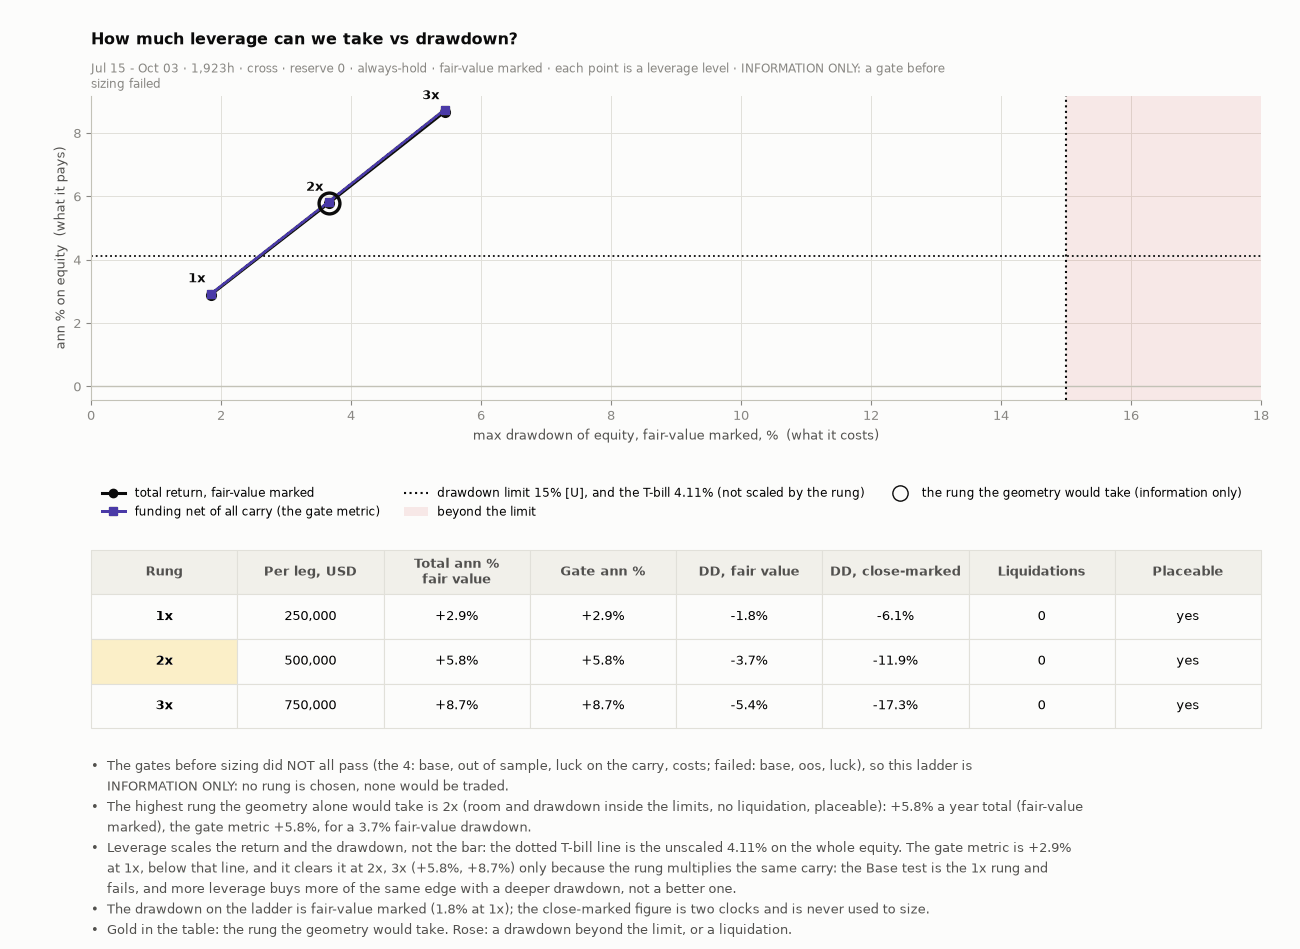

In [37]:
# ---- 6.1 the ladder: what each rung pays against the fair-value drawdown it costs ----
LAD_SHOW = [L for L in LEVS if PLACEABLE[(L, 0.0)] and not LAD[L][0]["liquidations"]]
ABOVE_BAR = [L for L in LAD_SHOW if gate_ann[L] > HURDLE_PCT]          # the rungs whose gate metric sits above the unscaled T-bill line in the picture
LB = [f"The gates before sizing {'passed' if PASSED else 'did NOT all pass'} (the {len(PRE_GATES)}: base, out of sample, luck on the carry, costs; failed: {', '.join(FAILED_PRE) or 'none'}), so this ladder is " + ("the sized book." if PASSED else "INFORMATION ONLY: no rung is chosen, none would be traded."),
      f"The highest rung the geometry alone would take is {SHOWN}x (room and drawdown inside the limits, no liquidation, placeable): {tot_ann[SHOWN]:+.1f}% a year total (fair-value marked), the gate metric {gate_ann[SHOWN]:+.1f}%, for a {abs(FVDD[SHOWN]):.1f}% fair-value drawdown." if SHOWN else "No rung clears the geometry.",
      f"Leverage scales the return and the drawdown, not the bar: the dotted T-bill line is the unscaled {HURDLE_PCT:.2f}% on the whole equity. The gate metric is {gate_ann[LEVS[0]]:+.1f}% at {LEVS[0]}x, " + (f"below that line, and it clears it at {', '.join(f'{L}x' for L in ABOVE_BAR)} ({', '.join(f'{gate_ann[L]:+.1f}%' for L in ABOVE_BAR)}) only because the rung multiplies the same carry: the Base test is the {LEVS[0]}x rung and fails, and more leverage buys more of the same edge with a deeper drawdown, not a better one." if (gate_ann[LEVS[0]] <= HURDLE_PCT and ABOVE_BAR) else (f"above that line." if gate_ann[LEVS[0]] > HURDLE_PCT else f"below that line, and it stays below it at every rung that places.")),
      f"The drawdown on the ladder is fair-value marked ({abs(FVDD[LEVS[0]]):.1f}% at {LEVS[0]}x); the close-marked figure is two clocks and is never used to size. " + (f"Rung(s) {', '.join(f'{L}x' for L in liqL)} liquidate and are off the lines." if liqL else ""),
      "Gold in the table: the rung the geometry would take. Rose: a drawdown beyond the limit, or a liquidation."]
fig, gs, ax, axt = fig_tab(7.4, (2.9, 1.7), hspace=0.62, nb=figstyle.nlines(LB))
xv = [abs(FVDD[L]) for L in LAD_SHOW]
ax.axvspan(DD_LIMIT_PCT, max(max(xv) * 1.1, DD_LIMIT_PCT * 1.2), color=CRIT, alpha=0.10, linewidth=0, zorder=1); ax.axvline(DD_LIMIT_PCT, color=INK, linestyle=":", linewidth=1.5, zorder=3)
ax.plot(xv, [tot_ann[L] for L in LAD_SHOW], "o-", color=INK, linewidth=2.2, markersize=7, zorder=4); ax.plot(xv, [gate_ann[L] for L in LAD_SHOW], "s-", color=C_NET, linewidth=2.0, markersize=6, zorder=4)
ax.axhline(HURDLE_PCT, color=INK, linestyle=":", linewidth=1.3, zorder=2)
for L, a_, b_ in zip(LAD_SHOW, xv, [tot_ann[L] for L in LAD_SHOW]):
    ax.annotate(f"{L}x", xy=(a_, b_), xytext=(-4, 9), textcoords="offset points", fontsize=9, fontweight="bold", color=INK, ha="right", zorder=6)
if SHOWN:
    ax.plot([abs(FVDD[SHOWN])], [tot_ann[SHOWN]], "o", color=GOOD if SIZED else INK, markersize=15, markerfacecolor="none", markeredgecolor=GOOD if SIZED else INK, markeredgewidth=2.4, zorder=5)
ax.axhline(0, color=AXIS, linewidth=1, zorder=1)
ax.set_xlim(0, max(max(xv) * 1.1, DD_LIMIT_PCT * 1.2)); ax.set_xlabel("max drawdown of equity, fair-value marked, %  (what it costs)"); ax.set_ylabel("ann % on equity  (what it pays)")
ax.legend(handles=[plt.Line2D([], [], color=INK, marker="o", linewidth=2.2, label="total return, fair-value marked"), plt.Line2D([], [], color=C_NET, marker="s", linewidth=2.0, label="funding net of all carry (the gate metric)"),
                   plt.Line2D([], [], color=INK, linestyle=":", linewidth=1.5, label=f"drawdown limit {DD_LIMIT_PCT:.0f}% [U], and the T-bill {HURDLE_PCT:.2f}% (not scaled by the rung)"), Patch(facecolor=CRIT, alpha=0.10, label="beyond the limit"),
                   plt.Line2D([], [], color=INK, marker="o", markerfacecolor="none", markersize=11, linestyle="none", label="the rung the geometry would take (information only)" if not SIZED else "the rung the rule picks")], loc="upper left", bbox_to_anchor=(0.0, -0.25), ncol=3, fontsize=8.5, frameon=False)
ask(ax, "How much leverage can we take vs drawdown?", f"{WSH} · cross · reserve 0 · always-hold · fair-value marked · each point is a leverage level · {SIZED_NOTE}")
cells = [[f"{L}x" + (" LIQ" if L in liqL else ""), f"{LAD[L][0]['notional_usd']:,.0f}", f"{tot_ann[L]:+.1f}%", f"{gate_ann[L]:+.1f}%", f"{FVDD[L]:.1f}%", f"{LAD[L][0]['max_drawdown_equity'] * 100:.1f}%", f"{LAD[L][0]['liquidations']}", ("yes" if PLACEABLE[(L, 0.0)] else "NO")] for L in LEVS]
tb = put_table(axt, cells, ["Rung", "Per leg, USD", "Total ann %" + chr(10) + "fair value", "Gate ann %", "DD, fair value", "DD, close-marked", "Liquidations", "Placeable"], size=9.2)
for i_, L in enumerate(LEVS, 1):
    if FVDD[L] <= -DD_LIMIT_PCT or L in liqL: tint(tb, i_, 4, "rose")
    if L == SHOWN: gold(tb, i_, 0)
foot(fig, *LB)
figstyle.show(fig, "fig:s6-ladder", FIGURES)
ST6["ladder"] = {str(L): {"per_leg": LAD[L][0]["notional_usd"], "ann": tot_ann[L],      # ann is the fair-value return
                          "above_bar": bool(gate_ann[L] > HURDLE_PCT), "gate": gate_ann[L], "dd_fv": FVDD[L], "dd_close": LAD[L][0]["max_drawdown_equity"] * 100, "liq": LAD[L][0]["liquidations"], "placeable": bool(PLACEABLE[(L, 0.0)])} for L in LEVS}

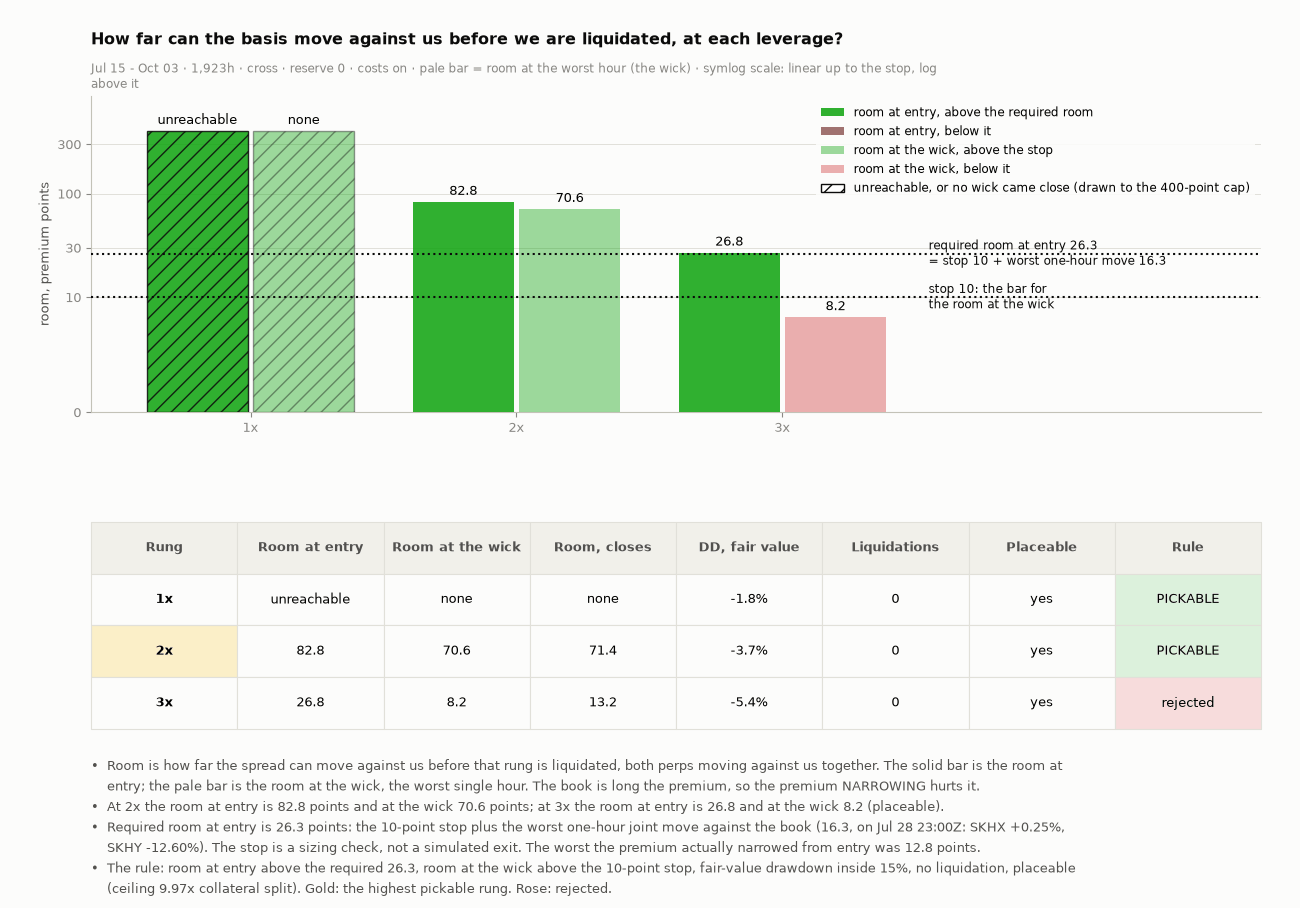

In [38]:
# ---- 6.2 room against the stop ----
RB = [f"Room is how far the spread can move against us before that rung is liquidated, both perps moving against us together. The solid bar is the room at entry; the pale bar is the room at the wick, the worst single hour. The book is long the premium, so the premium NARROWING hurts it.",
      (f"At {SHOWN}x the room at entry is {fpt(ROOM_ENTRY[SHOWN])} points and at the wick {'none came close to liquidation' if WICKPT[SHOWN] is None else format(WICKPT[SHOWN], '.1f') + ' points'}" if SHOWN else "No rung clears") + f"; at {LEVS[-1]}x the room at entry is {fpt(ROOM_ENTRY[LEVS[-1]])} and at the wick {fpt(WICKPT[LEVS[-1]])} ({'refused by the venue' if not PLACEABLE[(LEVS[-1], 0.0)] else 'placeable'}).",
      f"Required room at entry is {REQ_PTS:.1f} points: the {STOP_PTS:.0f}-point stop plus the worst one-hour joint move against the book ({WJ_PTS:.1f}, on {pd.Timestamp(rows[kJ + 1]['time'], unit='ms', tz='UTC'):%b %d %H:%MZ}: SKHX +{aA[kJ]:.2f}%, SKHY -{aB[kJ]:.2f}%). The stop is a sizing check, not a simulated exit. The worst the premium actually narrowed from entry was {WORST_NARROW:.1f} points.",
      f"The rule: room at entry above the required {REQ_PTS:.1f}, room at the wick above the {STOP_PTS:.0f}-point stop, fair-value drawdown inside {DD_LIMIT_PCT:.0f}%, no liquidation, placeable (ceiling {SPLIT_MAX:.2f}x collateral split). Gold: the highest pickable rung. Rose: rejected."]
fig, gs, ax, axt = fig_tab(7.4, (2.6, 1.7), hspace=0.42, nb=figstyle.nlines(RB))
xs = np.arange(len(LEVS)); CAP = 400.0
import matplotlib.ticker as mtick
cap_ = lambda v_: CAP if v_ is None else min(CAP, v_)
entry_ok = [ROOM_ENTRY[L] is None or ROOM_ENTRY[L] > REQ_PTS for L in LEVS]; wick_ok = [WICKPT[L] is None or WICKPT[L] > STOP_PTS for L in LEVS]
b_e = ax.bar(xs - 0.2, [cap_(ROOM_ENTRY[L]) for L in LEVS], 0.38, color=[GOOD if ok_ else CRIT for ok_ in entry_ok], alpha=0.85, zorder=3)
b_w = ax.bar(xs + 0.2, [cap_(WICKPT[L]) for L in LEVS], 0.38, color=[GOOD if ok_ else CRIT for ok_ in wick_ok], alpha=0.40, zorder=3)
for bars_, vals_ in ((b_e, [ROOM_ENTRY[L] for L in LEVS]), (b_w, [WICKPT[L] for L in LEVS])):
    for b_, v_ in zip(bars_, vals_):
        if v_ is None:
            b_.set_hatch("//"); b_.set_edgecolor(INK)          # unreachable, or no wick came close to a liquidation: drawn to the cap, not a measured room
ax.set_yscale("symlog", linthresh=STOP_PTS, linscale=1.0)   # linear up to the stop, log above it: the 3x bar and the 1x slab both read
for bars_, vals_, none_ in ((b_e, [ROOM_ENTRY[L] for L in LEVS], "unreachable"), (b_w, [WICKPT[L] for L in LEVS], "none")):
    for t_ in ax.bar_label(bars_, labels=[(none_ if v_ is None else (f"{v_:.1f}" if v_ < CAP else "off scale")) for v_ in vals_], fontsize=9, padding=3):
        t_.set_clip_on(False)
ax.axhline(REQ_PTS, color=INK, linestyle=":", linewidth=1.5, zorder=4); ax.axhline(STOP_PTS, color=INK, linestyle=":", linewidth=1.5, zorder=4)
ax.text(len(LEVS) - 0.45, REQ_PTS, f"required room at entry {REQ_PTS:.1f}" + chr(10) + f"= stop {STOP_PTS:.0f} + worst one-hour move {WJ_PTS:.1f}", ha="left", va="center", fontsize=8.5, color=INK)
ax.text(len(LEVS) - 0.45, STOP_PTS, f"stop {STOP_PTS:.0f}: the bar for" + chr(10) + "the room at the wick", ha="left", va="center", fontsize=8.5, color=INK)
ax.set_xlim(-0.6, len(LEVS) + 0.8); ax.set_ylim(0, CAP * 2.2)
_yt = [0, STOP_PTS, 30, 100, 300]; ax.set_yticks(_yt); ax.set_yticklabels([f"{v:g}" for v in _yt]); ax.yaxis.set_minor_locator(mtick.NullLocator())
ax.set_xticks(xs); ax.set_xticklabels([f"{L}x" for L in LEVS]); ax.set_ylabel("room, premium points"); ax.grid(axis="x", visible=False)
ax.legend(handles=[Patch(facecolor=GOOD, alpha=0.85, label="room at entry, above the required room"), Patch(facecolor=CRIT, alpha=0.85, label="room at entry, below it"),
                   Patch(facecolor=GOOD, alpha=0.40, label="room at the wick, above the stop"), Patch(facecolor=CRIT, alpha=0.40, label="room at the wick, below it"),
                   Patch(facecolor="white", hatch="//", edgecolor=INK, label=f"unreachable, or no wick came close (drawn to the {CAP:.0f}-point cap)")], loc="upper right", fontsize=8.5, **LEG)
ask(ax, "How far can the basis move against us before we are liquidated, at each leverage?", f"{WSB} · pale bar = room at the worst hour (the wick) · symlog scale: linear up to the stop, log above it")
cells = [[f"{L}x", ("unreachable" if ROOM_ENTRY[L] is None else f"{ROOM_ENTRY[L]:.1f}"), ("none" if WICKPT[L] is None else f"{WICKPT[L]:.1f}"), ("none" if CLOSEPT[L] is None else f"{CLOSEPT[L]:.1f}"), f"{FVDD[L]:.1f}%", f"{LAD[L][0]['liquidations']}", ("yes" if PLACEABLE[(L, 0.0)] else "NO"), ("PICKABLE" if L in OKR else "rejected")] for L in LEVS]
tb = put_table(axt, cells, ["Rung", "Room at entry", "Room at the wick", "Room, closes", "DD, fair value", "Liquidations", "Placeable", "Rule"], size=9.2)
for i_, L in enumerate(LEVS, 1):
    tint(tb, i_, 7, "green" if L in OKR else "rose")
    if L == SHOWN: gold(tb, i_, 0)
foot(fig, *RB)
figstyle.show(fig, "fig:s6-room", FIGURES)
ST6["room"] = {"req": REQ_PTS, "wick_req": WJ_PTS, "p0": float(P0), "worst_narrow": WORST_NARROW, "worst_widen": WORST_WIDEN, "shown": SHOWN, "sized": SIZED, "passed": PASSED, "ceiling_split": SPLIT_MAX, "l_max_placeable": L_MAX_PLACEABLE,
                 "wj_pct": WJ, "wj_when": f"{pd.Timestamp(rows[kJ + 1]['time'], unit='ms', tz='UTC'):%Y-%m-%d %H:%MZ}",
                 "rungs": {str(L): {"entry": ROOM_ENTRY[L], "wick": WICKPT[L], "closes": CLOSEPT[L], "placeable": bool(PLACEABLE[(L, 0.0)]), "ok": L in OKR} for L in LEVS}, "nliq": NLIQ}

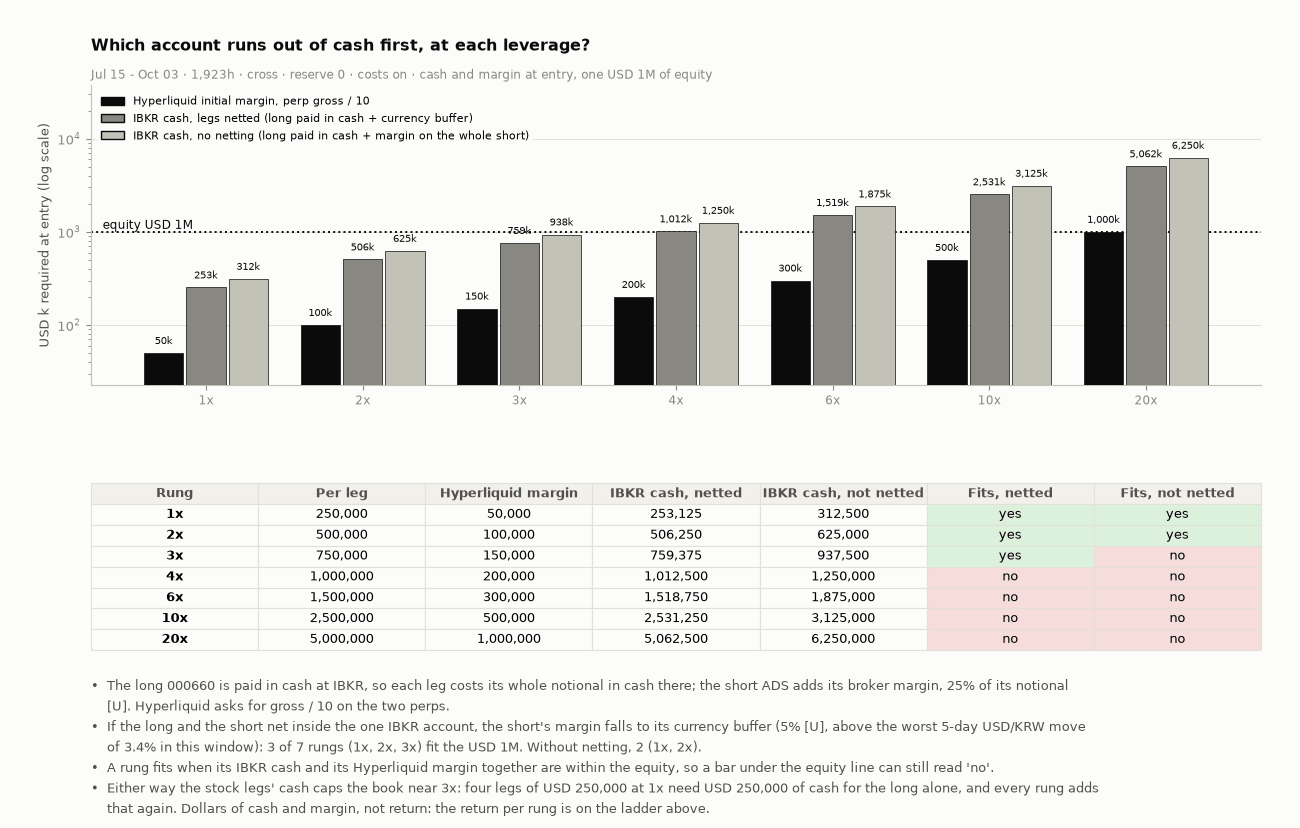

In [39]:
# ---- 6.3 which account runs out of cash first at each leverage: IBKR (the stock legs' cash and margin) or Hyperliquid (the perps' initial margin) ----
NN_ = {L: L * EQUITY / 4.0 for L in RUNGS_ALL}
hl_im = {L: 2 * NN_[L] / MAXLEV for L in RUNGS_ALL}                                    # the venue's initial margin on the two perps, gross / the leverage setting
ib_net = {L: ib_cash(NN_[L], True, IB_MARGIN) for L in RUNGS_ALL}; ib_not = {L: ib_cash(NN_[L], False, IB_MARGIN) for L in RUNGS_ALL}
fit_net = [L for L in RUNGS_ALL if ib_net[L] + hl_im[L] <= EQUITY]; fit_not = [L for L in RUNGS_ALL if ib_not[L] + hl_im[L] <= EQUITY]
AB = [f"The long 000660 is paid in cash at IBKR, so each leg costs its whole notional in cash there; the short ADS adds its broker margin, {IB_MARGIN * 100:g}% of its notional [U]. Hyperliquid asks for gross / {MAXLEV} on the two perps.",
      f"If the long and the short net inside the one IBKR account, the short's margin falls to its currency buffer ({FX_BUF * 100:g}% [U], above the worst 5-day USD/KRW move of {FX_MOVE5 * 100:.1f}% in this window): {len(fit_net)} of {len(RUNGS_ALL)} rungs ({', '.join(f'{L}x' for L in fit_net) or 'none'}) fit the {usdm(EQUITY)}. Without netting, {len(fit_not)} ({', '.join(f'{L}x' for L in fit_not) or 'none'}).",
      "A rung fits when its IBKR cash and its Hyperliquid margin together are within the equity, so a bar under the equity line can still read 'no'.",
      "Either way the stock legs' cash caps the book near 3x: four legs of USD 250,000 at 1x need USD 250,000 of cash for the long alone, and every rung adds that again. Dollars of cash and margin, not return: the return per rung is on the ladder above."]
fig, gs, ax, axt = fig_tab(6.6, (2.7, 1.5), hspace=0.42, nb=figstyle.nlines(AB))
xs = np.arange(len(RUNGS_ALL))
ax.set_yscale("log"); ax.set_ylim(min(min(hl_im.values()), min(ib_net.values())) / 1e3 * 0.45, max(max(ib_not.values()), EQUITY) / 1e3 * 6.0)
for off_, vals_, col_ in ((-0.27, hl_im, INK), (0.0, ib_net, MUTED), (0.27, ib_not, AXIS)):
    ax.bar(xs + off_, [vals_[L] / 1e3 for L in RUNGS_ALL], 0.25, color=col_, zorder=3, edgecolor=INK, linewidth=0.5)
    for x_, L in zip(xs, RUNGS_ALL): ax.text(x_ + off_, vals_[L] / 1e3 * 1.25, f"{vals_[L] / 1e3:,.0f}k", ha="center", fontsize=7.2, color=INK)
ax.axhline(EQUITY / 1e3, color=INK, linewidth=1.4, linestyle=":"); ax.annotate(f"equity {usdm(EQUITY)}", xy=(0.01, EQUITY / 1e3), xycoords=("axes fraction", "data"), color=INK, fontsize=8.4, va="bottom", ha="left")
ax.set_xticks(xs); ax.set_xticklabels([f"{L}x" for L in RUNGS_ALL], fontsize=8.8); ax.set_ylabel("USD k required at entry (log scale)"); ax.grid(axis="x", visible=False)
ax.legend(handles=[Patch(facecolor=INK, edgecolor=INK, label=f"Hyperliquid initial margin, perp gross / {MAXLEV}"), Patch(facecolor=MUTED, edgecolor=INK, label="IBKR cash, legs netted (long paid in cash + currency buffer)"), Patch(facecolor=AXIS, edgecolor=INK, label="IBKR cash, no netting (long paid in cash + margin on the whole short)")], loc="upper left", fontsize=8.2, **LEG)
ask(ax, "Which account runs out of cash first, at each leverage?", f"{WSB} · cash and margin at entry, one {usdm(EQUITY)} of equity")
cells = [[f"{L}x", f"{NN_[L]:,.0f}", f"{hl_im[L]:,.0f}", f"{ib_net[L]:,.0f}", f"{ib_not[L]:,.0f}", ("yes" if L in fit_net else "no"), ("yes" if L in fit_not else "no")] for L in RUNGS_ALL]
tb = put_table(axt, cells, ["Rung", "Per leg", "Hyperliquid margin", "IBKR cash, netted", "IBKR cash, not netted", "Fits, netted", "Fits, not netted"], size=9.0)
for i_, L in enumerate(RUNGS_ALL, 1):
    tint(tb, i_, 5, "green" if L in fit_net else "rose"); tint(tb, i_, 6, "green" if L in fit_not else "rose")
foot(fig, *AB)
figstyle.show(fig, "fig:s6-margin", FIGURES)
ST6["margin"] = {"fit_net": fit_net, "fit_not": fit_not, "n": len(RUNGS_ALL), "maxlev": MAXLEV, "fx_buf": FX_BUF, "fx_move5": FX_MOVE5, "frac": IB_MARGIN}

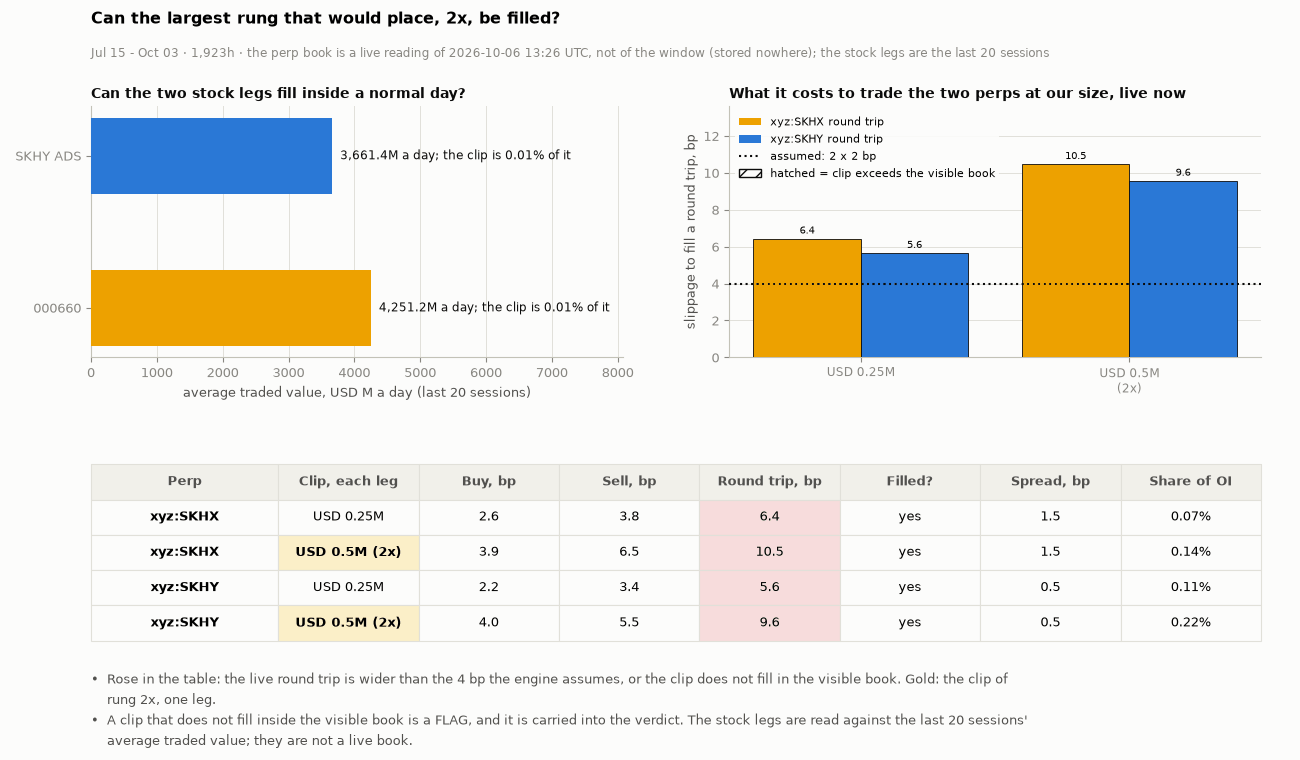

In [40]:
# ---- 6.4 can it be filled? the live perp book at the clip of the highest placeable rung, and the stock legs' day ----
L_FILL = SHOWN or LEVS[0]
CLIP = round(LAD[L_FILL][0]["notional_usd"])                          # one leg, each of the four
SIZES = tuple(sorted({round(LAD[L][0]["notional_usd"]) for L in (1, L_FILL, 6) if L in LAD}))
try:
    BD = HP.book_depth((COIN_A, COIN_B), sizes=SIZES); SNAP = DATA.hl_dex_bulk_funding("xyz")
except Exception as e:
    BD, SNAP = {}, {}; print("live read unavailable:", repr(e))
EX = []
for c_, x_ in (BD or {}).items():
    if x_:
        for sz in SIZES:
            f_ = x_["fills"][sz]
            EX.append({"coin": c_, "clip": sz, "buy": f_["buy"]["slippage_bps"], "sell": f_["sell"]["slippage_bps"], "filled": bool(f_["buy"]["filled"] and f_["sell"]["filled"]), "rt": f_["buy"]["slippage_bps"] + f_["sell"]["slippage_bps"], "spread": x_["spread_bps"] or 0})
# the two stock legs against their own average daily value: a clip that is a sliver of a normal day fills inside it
adv = {}
for nm, bars_, key in (("000660", krx, "A"), ("SKHY ADS", ads, "B")):
    last = [b for b in bars_][-20:]
    vol_usd = [float(b.get("volume") or 0) * float(b.get("close") or 0) / (float(fx[-1]["close"]) if key == "A" else 1.0) for b in last]
    adv[nm] = float(np.mean(vol_usd)) if vol_usd else float("nan")
fig = plt.figure(figsize=(13, 7.6))
bm = figstyle.bullets(fig, [f"Rose in the table: the live round trip is wider than the {2 * _pp.exec_slippage_bps:g} bp the engine assumes, or the clip does not fill in the visible book. Gold: the clip of rung {L_FILL}x, one leg.",
                            "A clip that does not fill inside the visible book is a FLAG, and it is carried into the verdict. The stock legs are read against the last 20 sessions' average traded value; they are not a live book."])
gs = fig.add_gridspec(2, 2, height_ratios=[2.7, 1.9], hspace=0.5, wspace=0.2, left=0.07, right=0.97, top=0.86, bottom=bm + 0.02)
s0, s1 = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1]); axt = fig.add_subplot(gs[1, :]); axt.axis("off")
names = list(adv); vals = [adv[n] for n in names]
s0.barh(range(len(names)), [v / 1e6 for v in vals], height=0.5, color=[C_A, C_B], zorder=3)
for i_, v in enumerate(vals):
    s0.text(v / 1e6, i_, f"  {v / 1e6:,.1f}M a day; the clip is {CLIP / v * 100:.2f}% of it", va="center", fontsize=8.8, color=INK)
s0.set_yticks(range(len(names))); s0.set_yticklabels(names, fontsize=9); s0.set_xlabel("average traded value, USD M a day (last 20 sessions)"); s0.grid(axis="y", visible=False)
s0.set_xlim(0, max(vals) / 1e6 * 1.9); s0.set_title("Can the two stock legs fill inside a normal day?", fontsize=10, loc="left", pad=6)
if EX:
    EXd = pd.DataFrame(EX)
    for j, c_ in enumerate((COIN_A, COIN_B)):
        sub = EXd[EXd["coin"] == c_]; okf = sub["filled"].tolist()
        b = s1.bar(np.arange(len(sub)) + (j - 0.5) * 0.4, sub["rt"], 0.4, color=[C_A, C_B][j], hatch=["" if f else "//" for f in okf], edgecolor=INK, linewidth=0.6, zorder=3)
        s1.bar_label(b, labels=[(f"{v:.1f}" if f else f">= {v:.1f}") for v, f in zip(sub["rt"], okf)], fontsize=7.5, padding=2)
    s1.axhline(2 * _pp.exec_slippage_bps, color=INK, linestyle=":", linewidth=1.5, zorder=4)
    s1.set_xticks(np.arange(len(SIZES))); s1.set_xticklabels([usdm(s) + (f"\n({L_FILL}x)" if s == CLIP else "") for s in SIZES], fontsize=8.5)
    s1.set_ylabel("slippage to fill a round trip, bp"); s1.set_ylim(top=EXd["rt"].max() * 1.3); s1.grid(axis="x", visible=False)
    s1.legend(handles=[Patch(facecolor=C_A, label="xyz:SKHX round trip"), Patch(facecolor=C_B, label="xyz:SKHY round trip"), plt.Line2D([], [], color=INK, linestyle=":", linewidth=1.5, label=f"assumed: 2 x {_pp.exec_slippage_bps:g} bp"),
                       Patch(facecolor=SURF, hatch="//", edgecolor=INK, label="hatched = clip exceeds the visible book")], loc="upper left", fontsize=8, **LEG)
    s1.set_title("What it costs to trade the two perps at our size, live now", fontsize=10, loc="left", pad=6)
    cells = [[r["coin"], usdm(r["clip"]) + (f" ({L_FILL}x)" if r["clip"] == CLIP else ""), f"{r['buy']:.1f}", f"{r['sell']:.1f}", f"{r['rt']:.1f}", ("yes" if r["filled"] else "NO"), f"{r['spread']:.1f}", (f"{r['clip'] / SNAP[r['coin']]['oi_usd'] * 100:.2f}%" if SNAP else "")] for r in EX]
    tb = put_table(axt, cells, ["Perp", "Clip, each leg", "Buy, bp", "Sell, bp", "Round trip, bp", "Filled?", "Spread, bp", "Share of OI"], size=9, first=0.16)
    for i_, r in enumerate(EX, 1):
        tint(tb, i_, 4, "rose" if r["rt"] > 2 * _pp.exec_slippage_bps else "green")
        if not r["filled"]: tint(tb, i_, 5, "rose")
        if r["clip"] == CLIP: gold(tb, i_, 1)
else:
    s1.axis("off"); axt.text(0.5, 0.5, "live book read unavailable at this run", ha="center")
fig.suptitle(f"Can the largest rung that would place, {L_FILL}x, be filled?", x=0.07, ha="left", fontsize=11.5, fontweight="bold", y=0.985)
fig.text(0.07, 0.925, f"{WSH} · the perp book is a live reading of {dt.datetime.now(dt.timezone.utc):%Y-%m-%d %H:%M} UTC, not of the window (stored nowhere); the stock legs are the last 20 sessions", color=MUTED, fontsize=8.5)
figstyle.show(fig, "fig:s6-fill", FIGURES)
filled_ok = bool(EX) and all(r["filled"] for r in EX if r["clip"] == CLIP)
worst_rt = max((r["rt"] for r in EX if r["clip"] == CLIP), default=None)
ST6["fill"] = {"clip_per_leg": CLIP, "rung": L_FILL, "filled_ok": filled_ok, "worst_rt": worst_rt, "assumed": 2 * _pp.exec_slippage_bps, "rows": EX, "adv": adv, "clip_share_of_adv": {n: CLIP / v for n, v in adv.items()}}

In [41]:
ST6["grid"] = {"n": len(GRM), "n_nofit": len(NOFIT), "nliq": int(sum(r_["liquidations"] for r_ in GRM.values())), "liquidated_cells": int(sum(LIQM.values()))}   # the grid runs are in S4, before the entry sweep
NBOOKS = int(ST4["n_runs"]) + int(ST6["grid"]["n"]) + 1 + int(ST4B["n_runs"])      # the base, cost, rule and hedge runs, the grid, and every entry the sweep kept: each passed every check or the build stopped
ST6["facts"] = {"window_from": f"{df.index[0]:%Y-%m-%d %H:%M}Z", "window_to": f"{df.index[-1]:%Y-%m-%d %H:%M}Z", "days": res["days"], "hours": int(res["n_hours"]), "verify": f"verify_four {NCHK} checks on each of {NBOOKS} books", "n_chk": NCHK, "n_books": NBOOKS,
                  "hurdle": HURDLE_PCT, "equity": EQUITY, "stop": STOP_PTS, "dd_limit": DD_LIMIT_PCT, "maxlev": MAXLEV, "entry_bps": float(ENTRY_BPS), "carry_stock_real": STOCK_CARRY_REAL[BOOK],
                  "funding_ann_leg": D7, "funding_mean_leg": DMEAN, "entry_premium": float(P0), "regime": "one window, one regime"}

## S7 · Verdict

The gates, the conclusion and the manifest are rendered below from the run's own objects.

In [42]:
Z2, Z3, Z4, Z5, Z6 = ST2, ST3, ST4, ST5, ST6
from fundplat.quant.core import stats as ST_
F6 = Z6["facts"]
pct = lambda x, sign=True, d=1: f"{x:+.{d}f}%" if sign else f"{x:.{d}f}%"
PF = lambda b: "PASS" if b else "FAIL"
HURDLE = F6["hurdle"]
yrs = F6["days"] / 365.0
EQ = F6["equity"]
WIN = f"{F6['window_from'][:10]} to {F6['window_to'][:10]}, {F6['hours']:,} hours ({F6['days']:.1f} days)"
N2 = Z2["net_vs_bar"]
P2 = Z2["premia"]
B2 = Z2["bases"]
E3 = Z3["equity"]; D3 = Z3["drawdown"]; DY = Z3["daily"]
O4, L4, C4, R4 = Z4["oos"], Z4["luck"], Z4["costs"], Z4["rules"]
SB = ST4B
H5, SP5, SH5, CL5, SI5 = Z5["hedge"], Z5["spread"], Z5["shut"], Z5["clocks"], Z5["sits"]
RM6, LAD6, FL6, MG6 = Z6["room"], Z6["ladder"], Z6["fill"], Z6["margin"]
sh = str(RM6["shown"])
rt_1x = [r for r in FL6["rows"] if r["clip"] == round(Z6["ladder"]["1"]["per_leg"])]
rules_ok = bool(R4["adopt"])
fill_flag = not (FL6["filled_ok"] and FL6["worst_rt"] is not None and FL6["worst_rt"] <= FL6["assumed"])
rt1 = max((r["rt"] for r in rt_1x), default=None); fill1 = all(r["filled"] for r in rt_1x) if rt_1x else False
fill_flag1 = not (fill1 and rt1 is not None and rt1 <= FL6["assumed"])
Q_TEXT = "Is it profitable to run the SKHY / SKHX book with each perp hedged by its own stock, to collect funding? How much does each hedge leak? How much can we make?"
B4, T3 = Z4["boot"], Z3["tail"]
_sz = Z6["room"]["sized"]
_wick = RM6["rungs"][sh]["wick"]
_share_adv = max(FL6["clip_share_of_adv"].values()) * 100 if FL6["clip_share_of_adv"] else float("nan")
PRE_NAMES = ("Base test", "Test 1a", "Test 1b", "Test 1c")     # the gates before sizing; the decision rule (S6) reads the same four
GATES = [
    ("Base test", "Does the carry beat a T-bill once the two stock legs are paid?", f"Funding net of the stock carry and fees earned {pct(Z3['gate_ann'])} a year against {pct(HURDLE, False, 2)}", PF(E3["pass"]), WOULD_CHANGE["Base test"]),
    ("Test 1a", "Does it still work after the split?", f"{pct(O4['out']['gate'])} a year on the later data ({pct(O4['in']['gate'])} before it)", PF(O4["pass"]), WOULD_CHANGE["Test 1a"]),
    ("Test 1b", "Is the excess over the T-bill statistically significant?", f"p = {L4['p_gate']:.3f} on {Z4['boot']['n_days']} days, the cut is {P_CUT:.2f}", PF(L4["pass"]), WOULD_CHANGE["Test 1b"]),
    ("Test 1c", "Do costs eat it?", f"The carry {'stays positive in all' if C4['pass'] else 'turns negative in at least one of'} {C4['n']} cost cells (best {pct(C4['best_gate'])}); {C4['n_clear']} of {C4['n']} reach the T-bill", PF(C4["pass"]), WOULD_CHANGE["Test 1c"]),
    ("Test 1d", "Is the basis alone, and the total P&L, distinguishable from luck?", f"Basis: mean {B4['basis']['mean']:+,.0f} USD a day, {CI_LEVEL * 100:.0f}% interval {B4['basis']['lo']:+,.0f} to {B4['basis']['hi']:+,.0f}, p = {B4['basis']['p']:.3f}. Total: mean {B4['total']['mean']:+,.0f}, interval {B4['total']['lo']:+,.0f} to {B4['total']['hi']:+,.0f}, p = {B4['total']['p']:.3f}; about {B4['total']['blocks']:.0f} independent blocks", "INFO", WOULD_CHANGE["Test 1d"]),
    ("Test 2", "Does exiting on a rule help?", "No rule improves the gate metric and the drawdown together" if not rules_ok else f"Yes: {R4['adopt'][0]}", "INFO" if not rules_ok else "PASS", WOULD_CHANGE["Test 2"]),
    ("Test 3", "How much is the entry hour?", f"A together entry's naked hours ran {SB['together']['p5']:+,.0f} to {SB['together']['p95']:+,.0f} USD (5th to 95th percentile); " + ("the registered staggered entry has none, by construction" if SB["staggered_by_construction"] else f"staggered, {SB['staggered']['p5']:+,.0f} to {SB['staggered']['p95']:+,.0f}"), "INFO", WOULD_CHANGE["Test 3"]),
    ("Sizing", "Is there room before liquidation, and does the drawdown fit?", ("Sized: " if _sz else "Information only: ") + f"the geometry would take {RM6['shown']}x ({fpt(RM6['rungs'][sh]['entry'])} points of room at entry against {RM6['req']:.1f} required; {'none' if _wick is None else format(_wick, '.1f')} at the worst hour against the {F6['stop']:.0f}-point stop; {abs(LAD6[sh]['dd_fv']):.1f}% fair-value drawdown against {F6['dd_limit']:.0f}%)", "INFO", WOULD_CHANGE["Sizing"]),
    ("Fill", "Can we trade this size at the cost we assumed?", f"Stock legs: the clip is {_share_adv:.2f}% of the thinner average daily value. Perps at the 1x clip: " + "; ".join(f"{r['coin']} {r['rt']:.1f} bp vs {FL6['assumed']:g} assumed, {'fills' if r['filled'] else 'does not fill'}" for r in rt_1x), "FLAG" if fill_flag1 else "PASS", WOULD_CHANGE["Fill"]),
]
assert [g[0] for g in GATES if g[0] in PRE_NAMES] == list(PRE_NAMES), [g[0] for g in GATES]
FAILED_NAMES = [g[0] for g in GATES if g[0] in PRE_NAMES and g[3] != "PASS"]
ALL_PASS = not FAILED_NAMES
assert ALL_PASS == bool(Z6["room"]["passed"]), "the S6 decision rule and the S7 gates disagree about the gates before sizing"
GATE_BY = {g[0]: g for g in GATES}
_g = ["| Test | The question | What we found | Result | What would change our mind |", "|---|---|---|---|---|"] + [f"| {a} | {b} | {c} | {d} | {e} |" for a, b, c, d, e in GATES]
VERDICT_MD = "\n".join([
    "**In short.** We tested holding the four-leg SK Hynix book static: short SKHX against long 000660 and long SKHY against short ADS, the stock legs matched one for one and never re-struck, so the P&L is the funding plus whatever the two bases do. "
    + ("Every gate before sizing passed." if ALL_PASS else f"{len(FAILED_NAMES)} of {len(PRE_NAMES)} gates before sizing failed ({'; '.join(FAILED_NAMES)}): the claim is not shown on this window and no size is chosen."), "",
    f"**What we found.** Over {F6['days']:.0f} days at 1x the book earned {pct(Z3['ann_equity'])} a year on the fair-value mark ({pct(Z3['ann_equity_close'])} close-marked). Funding gross was {pct(Z3['funding'] / EQ / yrs * 100)}, the two stock legs and the perp fees took {pct(Z3['costs'] / EQ / yrs * 100, False)}, leaving {pct(Z3['gate_ann'])} against the T-bill's {pct(HURDLE, False, 2)} ({'above' if E3['pass'] else 'below'} the bar). "
    f"Out of sample the carry read {pct(O4['out']['gate'])} ({'above' if O4['pass'] else 'below'} the bar); its excess over the T-bill has p {L4['p_gate']:.2f}; {C4['n_clear']} of {C4['n']} cost cells reach the bar. "
    f"Close-marked, the two bases moved the total by USD {Z3['basis']:+,.0f}: basis A (the won leg) USD {Z3['basis_A']:+,.0f}, basis B (the ADS leg) USD {Z3['basis_B']:+,.0f}; fair-value marked, by USD {Z3['basis_fv']:+,.0f}. "
    f"On the fair-value mark the basis alone averaged USD {B4['basis']['mean']:+,.0f} a day ({CI_LEVEL * 100:.0f}% block-bootstrap interval {B4['basis']['lo']:+,.0f} to {B4['basis']['hi']:+,.0f}, p {B4['basis']['p']:.2f}) and the total USD {B4['total']['mean']:+,.0f} ({B4['total']['lo']:+,.0f} to {B4['total']['hi']:+,.0f}, p {B4['total']['p']:.2f}).", "",
    f"**Risk.** The daily 95% VaR is {T3['var95']:+.2f}% of equity and the CVaR {T3['cvar95']:+.2f}% (skew {T3['skew']:+.2f}, kurtosis {T3['kurtosis']:.1f}); the deepest drawdown is {abs(D3['min']):.1f}% fair-value marked.", "",
    f"**What size.** " + ("None. " if not _sz else "") + f"{'The' if _sz else 'A gate before sizing failed, so the'} ladder in S6 is {'sized' if _sz else 'information'}. Its geometry would take {RM6['shown']}x ({pct(LAD6[sh]['ann'])} a year fair-value marked, {abs(LAD6[sh]['dd_fv']):.1f}% fair-value drawdown), but leverage only scales the {pct(Z3['gate_ann'])} the 1x book earns, which is below the bar it is tested against; the T-bill line does not scale with the rung, so a higher rung can cross it without any more edge. With the stock legs paid in cash only {max(MG6['fit_net'])}x fits inside the USD {EQ / 1e6:.0f}M, so IBKR's cash, not the perp venue, caps the size.", "",
    f"**The catch.** The bar is {Z2['bar_leg']:.1f}% of one perp leg's notional (the stock carry {Z2['carry_leg']:.1f}% plus the T-bill {Z2['hurdle_leg']:.1f}%). The differential averaged {F6['funding_mean_leg']:.1f}% over the window and {F6['funding_ann_leg']:.1f}% over the last 7 days. "
    + ("The live perp books do not take the 1x clip at the cost we assumed." if fill_flag1 else "The live perp books take the 1x clip at the cost we assumed."), "",
    f"**One result, not three.** `{STEM_PAIR}`, `{STEM_RATIO}` and this study, `{STEM_THIS}`, read the same legs over the same window ({F6['window_from'][:10]} to {F6['window_to'][:10]}) in one regime. What did not vary: the perp funding and prices, the cash prices, the window, the regime, the carry model. What varied: only how the stock leg is hedged (none in the pair, re-struck by rule in the ratio-hedge study, held static here). They agree because they hold the same data: for the desk's record the three add one result, and a belief moves only at the desk's retro.", "",
    f"Window: {WIN}: one window, one regime, one observation. {F6['verify']}, ALL PASS.", "",
] + _g + ["",
    f"**What we do next.** Nothing is registered. The one thing that would change the call is a differential that holds above {Z2['bar_leg']:.1f}% (7-day mean, one perp leg's notional) on a longer window that includes a second regime. This page prints that bar; the desk decides whether to register a forecast against it.", "",
    "**What could mislead us**", "",
    f"- One window, one regime, shared with `{STEM_PAIR}` and `{STEM_RATIO}`. The leverage-by-margin grid in the Appendix re-slices the same {F6['hours']:,} hours, so it is not {Z6['grid']['n']} separate results.",
    f"- {B4['n_days']} days in {B4['regimes']} regime ({B4['n_days'] / B4['block_d']:.0f} independent {B4['block_d']}-day blocks) cannot separate an edge from luck. A p or an interval here describes this window and nothing after it.",
    f"- The ADS borrow is [U]: IBKR publishes no quote for it, and the gate metric moves {C4['borrow_slope_per_pct']:+.2f} points for each point of borrow.",
    "- The stock legs are paid in cash, so the long 000660 costs the T-bill that cash forgoes (4.11%), not a loan rate; IBKR's KRW margin loan would cost 7.7% [1] (Test 1c). Whether IBKR credits interest on that cash is not counted.",
    f"- The broker's margin rule is an assumption [U]: whether IBKR nets the Korean share against the ADS inside one account, and the currency buffer, decide how much cash the stock legs tie up. The S6 margin table shows both; the cash caps the book at about {max(Z6['margin']['fit_net'])}x.",
    "- The engine still fills and close-marks the stock legs on the daily official close (EODHD); the hourly IBKR prints feed the fair-value mark and every cash-line chart. Hourly fills and marks need an engine change (board item B-0451).",
    f"- The Sharpe and Sortino are over a zero rate; the book earns less than the T-bill, so over the T-bill the Sharpe reads {Z3['risk']['sharpe_excess']:.2f}. Daily returns reverse the next day (lag-1 autocorrelation {Z3['risk']['lag1_autocorr_fv']:+.2f}), so a ratio annualised from them by the square root of time is understated.",
    "- Close-marked risk numbers price two clocks; the book's return, the verdict, the ratios, the tail and the bootstrap read the fair-value mark, and funding is unaffected. Each close-marked figure (the P&L bridge, the daily bars, the rule drawdown) is named as such.",
    "- Not tested, each a board item for platform because fundplat has no function for it: the minimum track-record length (B-0479), a drawdown bootstrap and a Sharpe bootstrap (B-0478), the correlation with the fund's own book (B-0481), a multi-factor regression of the book (B-0482) and a Monte Carlo of the next 30 days (B-0483).",
    "- Not modelled: converting won and wiring it to Hyperliquid (cost and delay), intraday stock fills, a 105% collateral requirement on a Korean short, borrow availability, ADL, tax on won gains, sub-hour wicks.",
])
display(Markdown(VERDICT_MD))

**In short.** We tested holding the four-leg SK Hynix book static: short SKHX against long 000660 and long SKHY against short ADS, the stock legs matched one for one and never re-struck, so the P&L is the funding plus whatever the two bases do. 3 of 4 gates before sizing failed (Base test; Test 1a; Test 1b): the claim is not shown on this window and no size is chosen.

**What we found.** Over 80 days at 1x the book earned +2.9% a year on the fair-value mark (+1.7% close-marked). Funding gross was +5.1%, the two stock legs and the perp fees took 2.2%, leaving +2.9% against the T-bill's 4.11% (below the bar). Out of sample the carry read +1.7% (below the bar); its excess over the T-bill has p 0.81; 1 of 9 cost cells reach the bar. Close-marked, the two bases moved the total by USD -2,551: basis A (the won leg) USD +341, basis B (the ADS leg) USD -2,892; fair-value marked, by USD -50. On the fair-value mark the basis alone averaged USD -1 a day (95% block-bootstrap interval -223 to +219, p 0.50) and the total USD +78 (-145 to +294, p 0.25).

**Risk.** The daily 95% VaR is -0.30% of equity and the CVaR -0.40% (skew +0.21, kurtosis 5.4); the deepest drawdown is 1.8% fair-value marked.

**What size.** None. A gate before sizing failed, so the ladder in S6 is information. Its geometry would take 2x (+5.8% a year fair-value marked, 3.7% fair-value drawdown), but leverage only scales the +2.9% the 1x book earns, which is below the bar it is tested against; the T-bill line does not scale with the rung, so a higher rung can cross it without any more edge. With the stock legs paid in cash only 3x fits inside the USD 1M, so IBKR's cash, not the perp venue, caps the size.

**The catch.** The bar is 25.4% of one perp leg's notional (the stock carry 8.9% plus the T-bill 16.4%). The differential averaged 21.9% over the window and 20.1% over the last 7 days. The live perp books do not take the 1x clip at the cost we assumed.

**One result, not three.** `2026-09-22-equities-skhynix-perp-pair`, `2026-09-22-xasset-skhynix-four-leg-ratio-hedge` and this study, `2026-10-04-xasset-skhynix-four-leg-static-hold`, read the same legs over the same window (2026-07-15 to 2026-10-03) in one regime. What did not vary: the perp funding and prices, the cash prices, the window, the regime, the carry model. What varied: only how the stock leg is hedged (none in the pair, re-struck by rule in the ratio-hedge study, held static here). They agree because they hold the same data: for the desk's record the three add one result, and a belief moves only at the desk's retro.

Window: 2026-07-15 to 2026-10-03, 1,923 hours (80.1 days): one window, one regime, one observation. verify_four 22 checks on each of 3202 books, ALL PASS.

| Test | The question | What we found | Result | What would change our mind |
|---|---|---|---|---|
| Base test | Does the carry beat a T-bill once the two stock legs are paid? | Funding net of the stock carry and fees earned +2.9% a year against 4.11% | FAIL | the carry net of all stock costs ends above the 4.11% T-bill at 1x |
| Test 1a | Does it still work after the split? | +1.7% a year on the later data (+3.6% before it) | FAIL | the out-of-sample carry is above the T-bill |
| Test 1b | Is the excess over the T-bill statistically significant? | p = 0.812 on 81 days, the cut is 0.10 | FAIL | p below 0.10 on the carry's excess over the T-bill (the stricter of sign shuffle and block bootstrap) |
| Test 1c | Do costs eat it? | The carry stays positive in all 9 cost cells (best +4.1%); 1 of 9 reach the T-bill | PASS | the carry turns negative in no cost cell |
| Test 1d | Is the basis alone, and the total P&L, distinguishable from luck? | Basis: mean -1 USD a day, 95% interval -223 to +219, p = 0.499. Total: mean +78, interval -145 to +294, p = 0.252; about 16 independent blocks | INFO | a basis whose 95% interval of the daily mean excludes zero on a longer window |
| Test 2 | Does exiting on a rule help? | No rule improves the gate metric and the drawdown together | INFO | a rule improves the carry and the drawdown together and holds 25% of the hours |
| Test 3 | How much is the entry hour? | A together entry's naked hours ran -24,369 to +16,927 USD (5th to 95th percentile); the registered staggered entry has none, by construction | INFO | a window in which the entry hour no longer moves the result |
| Sizing | Is there room before liquidation, and does the drawdown fit? | Information only: the geometry would take 2x (82.8 points of room at entry against 26.3 required; 70.6 at the worst hour against the 10-point stop; 3.7% fair-value drawdown against 15%) | INFO | every gate before sizing passes; then the highest rung with room above the stop plus the worst joint wick, drawdown inside the limit, no liquidation |
| Fill | Can we trade this size at the cost we assumed? | Stock legs: the clip is 0.01% of the thinner average daily value. Perps at the 1x clip: xyz:SKHX 6.4 bp vs 4 assumed, fills; xyz:SKHY 5.6 bp vs 4 assumed, fills | FLAG | the live round trip at the clip is within the assumed slippage and fills |

**What we do next.** Nothing is registered. The one thing that would change the call is a differential that holds above 25.4% (7-day mean, one perp leg's notional) on a longer window that includes a second regime. This page prints that bar; the desk decides whether to register a forecast against it.

**What could mislead us**

- One window, one regime, shared with `2026-09-22-equities-skhynix-perp-pair` and `2026-09-22-xasset-skhynix-four-leg-ratio-hedge`. The leverage-by-margin grid in the Appendix re-slices the same 1,923 hours, so it is not 10 separate results.
- 81 days in 1 regime (16 independent 5-day blocks) cannot separate an edge from luck. A p or an interval here describes this window and nothing after it.
- The ADS borrow is [U]: IBKR publishes no quote for it, and the gate metric moves -0.23 points for each point of borrow.
- The stock legs are paid in cash, so the long 000660 costs the T-bill that cash forgoes (4.11%), not a loan rate; IBKR's KRW margin loan would cost 7.7% [1] (Test 1c). Whether IBKR credits interest on that cash is not counted.
- The broker's margin rule is an assumption [U]: whether IBKR nets the Korean share against the ADS inside one account, and the currency buffer, decide how much cash the stock legs tie up. The S6 margin table shows both; the cash caps the book at about 3x.
- The engine still fills and close-marks the stock legs on the daily official close (EODHD); the hourly IBKR prints feed the fair-value mark and every cash-line chart. Hourly fills and marks need an engine change (board item B-0451).
- The Sharpe and Sortino are over a zero rate; the book earns less than the T-bill, so over the T-bill the Sharpe reads -0.35. Daily returns reverse the next day (lag-1 autocorrelation -0.38), so a ratio annualised from them by the square root of time is understated.
- Close-marked risk numbers price two clocks; the book's return, the verdict, the ratios, the tail and the bootstrap read the fair-value mark, and funding is unaffected. Each close-marked figure (the P&L bridge, the daily bars, the rule drawdown) is named as such.
- Not tested, each a board item for platform because fundplat has no function for it: the minimum track-record length (B-0479), a drawdown bootstrap and a Sharpe bootstrap (B-0478), the correlation with the fund's own book (B-0481), a multi-factor regression of the book (B-0482) and a Monte Carlo of the next 30 days (B-0483).
- Not modelled: converting won and wiring it to Hyperliquid (cost and delay), intraday stock fills, a 105% collateral requirement on a Korean short, borrow availability, ADL, tax on won gains, sub-hour wicks.

In [43]:
# ---- the research summary card (fundplat.quant.core.summary_card): the fixed carry card, every value read from the run's own objects above; the manifest carries it and the last cell draws it ----
yrsq = F6["days"] / 365.0
fund_eq = Z3["funding"] / EQ / yrsq * 100
costs_eq = -Z3["costs"] / EQ / yrsq * 100
basis_eq = Z3["basis_fv"] / EQ / yrsq * 100          # the basis on the FAIR-VALUE mark, so funding + costs + basis = the total return shown
RK = Z3["risk"]
BAR_TXT = f"T-bill {HURDLE:.1f}%"
ANSWER = (f"{'Yes' if ALL_PASS else 'NO SIZE'}. After the two stock legs are paid, funding earned {pct(Z3['gate_ann'])} a year at 1x against a {HURDLE:.1f}% T-bill; {len(FAILED_NAMES)} of {len(PRE_NAMES)} gates before sizing failed, " + ("so a size can be read." if ALL_PASS else "so no size is chosen."))
IMPL = [("Trade", "Short xyz:SKHX + long 000660; long xyz:SKHY + short the SKHY ADS"), ("Venue", "Hyperliquid xyz (perps), Interactive Brokers (stocks)"), ("Capital", f"USD {EQ / 1e6:.1f}M, four legs of USD {Z6['ladder']['1']['per_leg'] / 1e3:,.0f}k at 1x"),
        ("Costs", "0.9 bp fee [V], 2 bp slippage [U], cash-paid stock, ADS borrow 3% [U]"), ("Limits", f"stop {F6['stop']:.0f} premium points [U], drawdown {F6['dd_limit']:.0f}% [U]"), ("Window", f"{F6['window_from'][:10]} to {F6['window_to'][:10]}, {F6['hours']:,} h, 1 regime")]
BIG = [("1x", "Net carry after stock costs, ann.", pct(Z3["gate_ann"]), BAR_TXT, PF(E3["pass"]), None, "G1"), ("1x", "Return, ann., fair value", pct(Z3["ann_equity"]), "", "", "ann_return_pct"), ("1x", "Maximum drawdown, fair value", pct(-abs(D3["min"]), False), f"limit {F6['dd_limit']:.0f}%", PF(abs(D3["min"]) < F6["dd_limit"]), "max_dd_pct"),
       ("1x", "Round-trip slippage, live book", f"{rt1:.1f} bp", f"assumed {FL6['assumed']:.0f} bp", "FLAG" if fill_flag1 else "PASS", None, "G9")]
_wk = RM6["rungs"][str(RM6["shown"])]["wick"]          # the room left to liquidation at the worst hour, in premium points, on the rung S6 shows
BLOCKS = [
    ("Return, 1x, ann.", [("Funding carry", pct(fund_eq), "", "", "funding_ann_pct"), ("Stock carry and transaction costs", pct(costs_eq), "", ""), ("Net carry after stock costs", pct(Z3["gate_ann"]), BAR_TXT, PF(E3["pass"]), None, "G1"), ("Basis P&L, fair value", pct(basis_eq), "", "", "basis_ann_pct"), ("Total return, fair value", pct(Z3["ann_equity"]), "", "", "ann_return_pct"), ("Net P&L, USD, fair value", f"{Z3['total_fv']:+,.0f}", "", "")]),
    ("Risk, 1x", [("Volatility, ann.", pct(RK["vol"], False), "", "", "ann_vol_pct"), ("Sharpe ratio, over zero", f"{RK['sharpe']:.2f}", "", "", "sharpe"), ("Sharpe ratio, over the T-bill", f"{RK['sharpe_excess']:.2f}", "", ""), ("Sortino ratio, over zero", f"{RK['sortino']:.2f}", "", "", "sortino"), ("Calmar ratio", f"{RK['calmar']:.2f}", "", "", "calmar"),
                  ("Maximum drawdown, fair value", pct(-abs(D3["min"]), False), f"limit {F6['dd_limit']:.0f}%", PF(abs(D3["min"]) < F6["dd_limit"]), "max_dd_pct"), ("Maximum drawdown, close-marked", pct(-abs(D3["close_min"]), False), "two clocks", "INFO"), ("Drawdown duration, longest", f"{D3['longest_days']:.0f} days", "", "", "max_dd_days"), ("Daily lag-1 autocorrelation", f"{RK['lag1_autocorr_fv']:+.2f}", "", "INFO")]),
    ("Significance and robustness", [("Out-of-sample net carry", pct(O4["out"]["gate"]), BAR_TXT, PF(O4["pass"]), None, "G2"), ("p-value, excess over hurdle", f"{L4['p_gate']:.3f}", f"below {P_CUT:.2f}", PF(L4["pass"]), None, "G3"), ("p-value, total P&L, blocks", f"{B4['total']['p']:.3f}", f"below {P_CUT:.2f}", "INFO", None, "G5"), ("Cost-stress net carry, worst of 9", pct(min(c_["gate"] for c_ in C4["cells"])), "above zero", PF(C4["pass"]), None, "G4"), ("Cost cells at or above the T-bill", f"{C4['n_clear']} of {C4['n']}", BAR_TXT, "INFO"),
               ("Timing overlay", "none" if not rules_ok else R4["adopt"][0], "", "INFO" if not rules_ok else "PASS", None, "G6"), ("Entry-hour P&L, together, 5th-95th pct", f"{SB['together']['p5']:+,.0f} to {SB['together']['p95']:+,.0f} USD", "", "INFO", None, "G7")]),
    ("Bases and hedge", [("Premium spread, range", f"{SP5['min']:+.1f} to {SP5['max']:+.1f} pts", "", ""), ("Perp basis A, daily st.dev", f"{B2['A']['d_std']:.2f} pts", "", ""), ("Perp basis B, daily st.dev", f"{B2['B']['d_std']:.2f} pts", "", ""),
                        (f"Room left at the worst hour, {RM6['shown']}x", "none" if _wk is None else f"{_wk:.1f} pts", f"stop {F6['stop']:.0f} pts", "INFO" if not RM6["sized"] else PF(_wk is None or _wk > F6["stop"])), ("Maximum adverse basis move", f"{RM6['worst_narrow']:.1f} pts", "", ""), ("Hedge beta, SKHX / SKHY perp", f"{H5['A']['beta']:.2f} / {H5['B']['beta']:.2f}", "", "")]),
    (f"Size, {RM6['shown']}x" + ("" if _sz else " (information only)"), [("Highest leverage the geometry takes", f"{RM6['shown']}x", "", "INFO", None, "G8"), (f"Return, ann. at {RM6['shown']}x, fair value", pct(LAD6[sh]["ann"]), "", ""), (f"Maximum drawdown at {RM6['shown']}x", pct(-abs(LAD6[sh]["dd_fv"]), False), f"limit {F6['dd_limit']:.0f}%", PF(abs(LAD6[sh]["dd_fv"]) < F6["dd_limit"])),
                                 ("Account that binds", "IBKR cash", "stock legs paid in cash", "INFO")]),
]
SIZE_ROWS = [(f"{x}x", pct(LAD6[str(x)]["ann"]), pct(-abs(LAD6[str(x)]["dd_fv"]), False), ("none" if RM6["rungs"][str(x)]["wick"] is None else f"{RM6['rungs'][str(x)]['wick']:.1f} pts"), ("PASS" if RM6["sized"] else "INFO") if RM6["rungs"][str(x)]["ok"] else "FAIL", x == RM6["shown"] and RM6["sized"]) for x in sorted({1, RM6["shown"], max(int(k_) for k_ in RM6["rungs"])})]
FOOT = [f"Next test: a 7-day differential above {Z2['bar_leg']:.1f}% of one perp leg's notional (the carry plus the T-bill); the last 7 days read {F6['funding_ann_leg']:.1f}%.",
        f"{F6['verify']} · {F6['hours']:,} h, {REGIMES} regime, one result with its two sibling studies."]


mk = lambda metric, value, bar="", verdict="", key=None, gate=None: {"metric": metric, "value": value, "bar": bar, "verdict": verdict, **({"key": key} if key else {}), **({"gate": gate} if gate else {})}     # key: the manifest metric the value reads; gate: the gate the verdict is
_chosen = next((k_ for k_, r_ in enumerate(SIZE_ROWS) if r_[0] == f"{RM6['shown']}x"), 0)
CARD = {"question": Q_TEXT, "answer": ANSWER, "implementation": IMPL,
        "big": [dict(mk(m_, v_, b_, vd_, *kg_), scope=g_) for g_, m_, v_, b_, vd_, *kg_ in BIG],
        "blocks": [{"title": t_, "rows": [mk(*r_) for r_ in rows_]} for t_, rows_ in BLOCKS],
        "sizes": {"cols": ["Size", "Return", "Max DD", "Liq buffer", "Verdict"], "chosen": _chosen,
                  "rows": [[r_[0], r_[1], r_[2], r_[3], r_[4]] for r_ in SIZE_ROWS]},
        "footer": FOOT}

In [44]:
# ---- S7: the gates as DATA and the study manifest fund.study/1 (carry format), built and validated by fundplat.quant.core.report, emitted as ONE display output ----
import datetime as _dt
STUDY_ID = STEM_THIS
GATE_LABELS = ["Beats T-bill", "Out of sample", "Significant carry", "Survives costs", "Basis vs luck", "Timing rule", "Entry hour", "Size and room", "Fills at size"]
GATE_SECTION = ["S3", "S4", "S4", "S4", "S4", "S4", "S4", "S6", "S6"]
assert len(GATES) == len(GATE_LABELS) == len(GATE_SECTION), len(GATES)
STUDY_GATES = [{"id": f"G{n_}", "section": GATE_SECTION[n_ - 1], "name": g_[1], "label": GATE_LABELS[n_ - 1], "reading": g_[2], "verdict": g_[3], "would_change": g_[4]}
               for n_, g_ in enumerate(GATES, 1)]
assert all(g_["verdict"] in REPORT.GATE_VERDICTS for g_ in STUDY_GATES), [g_["verdict"] for g_ in STUDY_GATES]
WORD = f"{Z6['room']['shown']}x" if Z6["room"]["sized"] else "NO SIZE"
PPY = 365
dys_ = res["days"]
ann_ = lambda usd_: usd_ / EQUITY * 365.0 / dys_ * 100.0
RK = Z3["risk"]
METRICS = {"ann_return_pct": Z3["ann_equity"], "excess_vs_hurdle_pct": Z3["ann_equity"] - HURDLE_PCT,
           "ann_vol_pct": RK["vol"], "sharpe": RK["sharpe"], "sortino": RK["sortino"], "calmar": RK["calmar"],
           "psr": float(ST_.psr(list((DAYFV / EQUITY).values))), "dsr": None,
           "max_dd_pct": Z3["drawdown"]["min"], "max_dd_days": Z3["drawdown"]["longest_days"], "n_periods": RK["n_days"], "periods_per_year": PPY,
           "funding_ann_pct": ann_(res["funding_net"]), "basis_ann_pct": ann_(Z3["basis_fv"]), "price_ann_pct": ann_(res["unhedged_pnl"]),
           "fees_ann_pct": ann_(-(res["perp_fees"] + res["perp_liq_fees"] + res["stock_costs"])), "financing_ann_pct": ann_(-res["financing"]),
           "mirror_ann_pct": None, "funding_pos_share_pct": float((d_h.iloc[1:] > 0).mean() * 100), "time_in_market_pct": res["hold_share"] * 100,
           "min_liq_distance_pct": res["min_dist_wick_pct"], "turnover_ann": 2 * 4 * res["notional_usd"] / EQUITY * 365.0 / dys_}
METRICS = {k_: (round(float(v_), 4) if isinstance(v_, (int, float)) and np.isfinite(v_) and not isinstance(v_, bool) else v_) for k_, v_ in METRICS.items()}
METRICS["n_periods"], METRICS["periods_per_year"] = RK["n_days"], PPY
NA = {"mirror_ann_pct": "the reverse trade is not run: the owner dropped the concept (2026-10-03)", "dsr": "the trial-count read is not run in this study: it was cut from the SK Hynix studies on 2026-10-06"}
for k_ in ("calmar", "psr"):
    if METRICS[k_] is None or not np.isfinite(METRICS[k_]):
        METRICS[k_] = None
        NA[k_] = "not defined on this window"
COMPS = [{"name": "funding", "usd": round(float(Z3["funding"]), 2)}, {"name": "basis A (SKHX perp vs 000660)", "usd": round(float(Z3["basis_A"]), 2)},
         {"name": "basis B (SKHY perp vs ADS)", "usd": round(float(Z3["basis_B"]), 2)}, {"name": "stock financing", "usd": -round(float(Z3["financing"]), 2)},
         {"name": "stock round trips", "usd": -round(float(Z3["stock_costs"]), 2)}, {"name": "perp fees", "usd": -round(float(Z3["perp_fees"]), 2)},
         {"name": "dividends", "usd": round(float(Z3["dividends"]), 2)}]
assert abs(sum(c_["usd"] for c_ in COMPS) - Z3["total"]) < 0.01 * len(COMPS), (sum(c_["usd"] for c_ in COMPS), Z3["total"])
STEP_ = int(pd.Series(np.diff([r_["time"] for r_ in rows])).mode()[0])
PROFILE = {"market": "equities", "markets": ["equities", "crypto"], "venues": ["hyperliquid:xyz", "eodhd", "yahoo"],
           "instruments": [COIN_A, COIN_B, "000660 (KRX)", "SKHY ADS (Nasdaq)"], "bar": {HOUR: "1h", 24 * HOUR: "1d"}[STEP_]}
assert p1.direction == F.BOOK_DIRECTION == "short_a"
ENTER_ = {leg_: next(e_ for e_ in res["stock_events"] if e_["leg"] == leg_ and e_["kind"] == "enter") for leg_ in ("A", "B")}
BOOKCARD = {"at": f"{LEV:g}x", "legs": [
    {"side": "SHORT", "instrument": COIN_A, "account": "hyperliquid:xyz", "usd": round(res["notional_usd"], 2)},
    {"side": "LONG", "instrument": COIN_B, "account": "hyperliquid:xyz", "usd": round(res["notional_usd"], 2)},
    {"side": "LONG", "instrument": "000660 (KRX)", "account": "ibkr", "usd": round(ENTER_["A"]["qty"] * ENTER_["A"]["px_usd"], 2), "qty": round(ENTER_["A"]["qty"], 4), "unit": "shares"},
    {"side": "SHORT", "instrument": "SKHY ADS (Nasdaq)", "account": "ibkr", "usd": round(ENTER_["B"]["qty"] * ENTER_["B"]["px_usd"], 2), "qty": round(ENTER_["B"]["qty"], 4), "unit": "ADS"}]}
FR1 = F.stock_fin_rates(p1)
RULES_CARD = {"entry": f"{ENTRY_MODE}: each perp with its own hedge", "exit": "forced at the window end, stocks at their last close",
              "sizing": f"{LEV:g}x = four legs of USD {EQUITY * LEV / 4:,.0f}", "rebalance": None, "hedge": "matched units: 1 000660 share / SKHX, 1 ADS / SKHY",
              "hold": "always" if not Z4["rules"]["adopt"] else str(Z4["rules"]["adopt"][0])[:40], "stop": f"{STOP_PTS:g} premium pts of room [U]",
              "cost": f"{_pp.fee_taker_bps:g}+{_pp.exec_slippage_bps:g} bp a fill; fin {FR1['long'] * 100:g}%, borrow {FR1['short_net'] * 100:g}% net [U]"}
assert all(v_ is None or len(v_) <= 60 for v_ in RULES_CARD.values()), {k_: len(v_) for k_, v_ in RULES_CARD.items() if v_}
VERDICT = {"word": WORD, "why": [GATE_BY["Base test"][2], GATE_BY["Test 1d"][2], GATE_BY["Sizing"][2]], "next_bet": f"a 7-day differential above {Z2['bar_leg']:.1f}% of one perp leg's notional would change the call; nothing is registered"}
CAVEATS = [f"one window, one regime, one observation: one result with {STEM_PAIR} and {STEM_RATIO}, not three", "returns, the basis and every risk ratio are on the fair-value mark; the P&L components and the price return are close-marked (they sum to the engine's close-marked total)", "risk numbers on the engine's fair-value mark; the hourly cash prints are IBKR's and mark a leg, never fill it",
           "ADS borrow and rebate [U] until an IBKR quote", "the ratios are on FAIR-VALUE daily returns on equity, periods_per_year 365", "the fill reading is live and stored nowhere",
           "81 days in one regime cannot separate an edge from luck: a p or an interval describes this window and nothing after it"]
FIGURES.append({"id": "fig:s6-grid", "section": "S6", "title": "What do leverage and reserve do to the return and the drawdown?"})
# each figure's chart type: the heading slug of its chapter in app/library/research/charts*.md (check_charts.py holds that it names one); fig:s5-clocks is the clock-and-staleness type, fig:s3-pnl the profit-and-loss attribution, fig:s5-sits the exposure over time
FIG_KIND = {"fig:s2-funding-7d": "series-and-distribution", "fig:s2-funding-hourly": "series-and-distribution", "fig:s2-net-vs-bar": "series-and-distribution", "fig:s2-net-hourly": "series-and-distribution",
            "fig:s2-funding-vol": "series-and-distribution", "fig:s2-premia": "series-and-distribution", "fig:s2-bases": "hedge-and-basis", "fig:s2-distribution": "series-and-distribution",
            "fig:s3-equity": "equity-curve", "fig:s3-pnl": "profit-and-loss-attribution", "fig:s3-drawdown": "drawdown-and-tail", "fig:s3-daily": "equity-curve", "fig:s3-tail": "drawdown-and-tail",
            "fig:s4-oos": "out-of-sample-test", "fig:s4-rolling-carry": "rolling-statistics", "fig:s4-significance": "significance-test", "fig:s4-costs": "cost-sensitivity", "fig:s4-bootstrap": "significance-test",
            "fig:s4-rules": "rule-comparison", "fig:s4-entry": "rule-comparison",
            "fig:s5-hedge": "hedge-and-basis", "fig:s5-spread": "signal-decay", "fig:s5-shut": "hedge-and-basis", "fig:s5-sits": "exposure-over-time", "fig:s5-clocks": "clock-and-staleness",
            "fig:s6-ladder": "sizing-and-fill", "fig:s6-room": "sizing-and-fill", "fig:s6-margin": "sizing-and-fill", "fig:s6-fill": "sizing-and-fill", "fig:s6-grid": "sizing-and-fill"}
NO_KIND = set()
assert set(FIG_KIND) | NO_KIND == {f_["id"] for f_ in FIGURES} and not set(FIG_KIND) & NO_KIND, (set(FIG_KIND) | NO_KIND) ^ {f_["id"] for f_ in FIGURES}
for f_ in FIGURES:
    if f_["id"] in FIG_KIND:
        f_["kind"] = FIG_KIND[f_["id"]]
from fundplat.data import handle as HANDLE
INPUTS = HANDLE.pin_reads(f"study input: {STUDY_ID}", f"study:{STUDY_ID}")
INPUTS["unpinned"] += [
    {"what": "hyperliquid xyz SKHX / SKHY funding, candles and premium (HP.load_pair_rows)", "why": "read through the pair loader, not a handle; re-pulled every run"},
    {"what": "eodhd daily bars 000660.KO, SKHY.US, KRW.FOREX and yahoo 60-minute bars 000660.KS, SKHY (INTRA.yahoo_hourly)", "why": "read through the tradfi loaders, not a handle; the Yahoo hourly head is lost beyond 730 days"},
    {"what": "hyperliquid live order book and open interest (the fill reading)", "why": "class none: a live reading, stored nowhere"}]
HEADLINE_GATE = "G1"     # the gate that judges the headline: the net carry against the T-bill hurdle (the Base test)
assert HEADLINE_GATE in {g_["id"] for g_ in STUDY_GATES} and STUDY_GATES[0]["label"] == "Beats T-bill", HEADLINE_GATE
STUDY = REPORT.build_manifest(
    id=STUDY_ID, kind="strategy", desk="lab/research", title="SK Hynix four-leg book, static hold",
    question="Is it profitable to run the SKHY / SKHX book with each perp hedged by its own stock, to collect funding? How much does each hedge leak? How much can we make?",
    status="run", run={"executed": _dt.datetime.now(_dt.timezone.utc).strftime("%Y-%m-%dT%H:%MZ"), "kernel": "ccvenv"}, inputs=INPUTS,
    window={"from": Z6["facts"]["window_from"].replace(" ", "T"), "to": Z6["facts"]["window_to"].replace(" ", "T"), "hours": int(res["n_hours"]), "regimes": 1},
    verify={"suite": "verify_four", "passed": Z6["facts"]["n_chk"], "total": Z6["facts"]["n_chk"], "books": Z6["facts"]["n_books"]},
    gates=STUDY_GATES, figures=FIGURES, verdict=VERDICT, caveats=CAVEATS,
    headline={"metric": "funding net of all stock carry, ann % on equity", "label": "Net carry", "value": round(Z3["gate_ann"], 4), "unit": "pct_ann", "hurdle": HURDLE_PCT, "gate": HEADLINE_GATE},
    components=COMPS, format="carry", metrics=METRICS, na=NA, style="discretionary",
    strategy={"name": "SK Hynix four-leg book, two accounts", "thesis": "receive the xyz:SKHX / xyz:SKHY funding differential, each perp hedged by its own cash listing",
              "market": "equity perps + cash equities", "instruments": [COIN_A, COIN_B, "000660 (KRX)", "SKHY ADS (Nasdaq)"], "venues": ["hyperliquid:xyz", "ibkr"], "style": "carry"},
    rules=RULES_CARD,
    params={"equity": {"value": EQUITY, "unit": "usd", "source": "owner"}, "leverage": {"value": LEV, "unit": "x", "source": "owner"},
            "entry_mode": {"value": ENTRY_MODE, "source": "owner"}, "stock_sizing": {"value": STOCK_SIZING, "source": "owner 2026-09-27 (F2, B-0246)"},
            "long_stock_financing": {"value": FR1["long"], "unit": "ann", "source": "[U]"}, "short_borrow": {"value": FR1["short_borrow"], "unit": "ann", "source": "[U]"},
            "short_rebate": {"value": FR1["short_rebate"], "unit": "ann", "source": "[U]"}, "hurdle": {"value": refdata.HURDLE_ANN, "unit": "ann", "source": "[V] Treasury par 3 Mo, 2026-09-14"},
            "stop_pts": {"value": STOP_PTS, "unit": "pts", "source": "[U]"}, "dd_limit_pct": {"value": DD_LIMIT_PCT, "unit": "%", "source": "[U]"},
            "p_cut": {"value": P_CUT, "source": "[U]"}, "ci_level": {"value": CI_LEVEL, "source": "[U]"},
            "boot_block_d": {"value": BOOT_BLOCK_D, "unit": "days", "source": "[U]"}},
    equity=[(t_.to_pydatetime(), round(float(v_) * 1e6, 2)) for t_, v_ in eq_fv.items()], profile=PROFILE, book=BOOKCARD, summary=CARD)
display(REPORT.display_bundle(STUDY), raw=True)

study manifest fund.study/1: 9 gates, 30 figures, verdict NO SIZE

## A · Appendix

The leverage by broker-margin grid: the same hours re-sliced, so one observation and not ten.

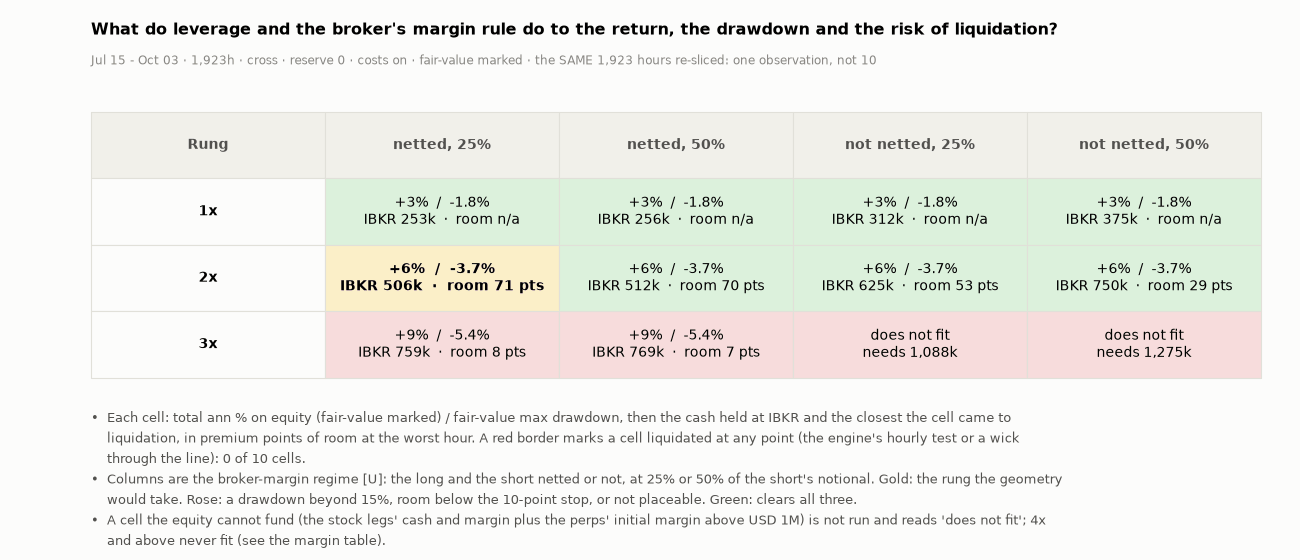

In [45]:
# ---- A: the grid, drawn (information; one window re-sliced, not 12 observations) ----
fig = plt.figure(figsize=(13, 5.6))
bm = figstyle.bullets(fig, [f"Each cell: total ann % on equity (fair-value marked) / fair-value max drawdown, then the cash held at IBKR and the closest the cell came to liquidation, in premium points of room at the worst hour. A red border marks a cell liquidated at any point (the engine's hourly test or a wick through the line): {ST6['grid']['liquidated_cells']} of {len(GRM)} cells.",
                            f"Columns are the broker-margin regime [U]: the long and the short netted or not, at 25% or 50% of the short's notional. Gold: the rung the geometry would take. Rose: a drawdown beyond {DD_LIMIT_PCT:.0f}%, room below the {STOP_PTS:.0f}-point stop, or not placeable. Green: clears all three.",
                            "A cell the equity cannot fund (the stock legs' cash and margin plus the perps' initial margin above USD 1M) is not run and reads 'does not fit'; 4x and above never fit (see the margin table)."])
gs = fig.add_gridspec(1, 1, left=0.07, right=0.97, top=0.80, bottom=bm + 0.03); axt = fig.add_subplot(gs[0]); axt.axis("off")
cells = [[f"{L}x"] + [(f"does not fit" + chr(10) + f"needs {NOFIT[(L, nm_)] / 1e3:,.0f}k") if (L, nm_) in NOFIT else
                      (f"{fv_ann(GRM[(L, nm_)]):+.0f}%  /  {fvdd(GRM[(L, nm_)]):.1f}%" + chr(10) + f"IBKR {IBC[(L, nm_)] / 1e3:,.0f}k  ·  " + ("LIQUIDATED" if LIQM[(L, nm_)] else ("room n/a" if WRM[(L, nm_)] is None else f"room {WRM[(L, nm_)]:.0f} pts"))) for nm_, _n, _f in REGS] for L in LEVS]
tb = axt.table(cellText=cells, colLabels=["Rung"] + [nm_ for nm_, _n, _f in REGS], cellLoc="center", loc="center", bbox=[0, 0, 1, 1]); tb.auto_set_font_size(False); tb.set_fontsize(10); figstyle.style_table(tb)
for i_, L in enumerate(LEVS, 1):
    tb[(i_, 0)].set_text_props(weight="bold")
    for j_, (nm_, _n, _f) in enumerate(REGS, 1):
        if (L, nm_) in NOFIT:
            tint(tb, i_, j_, "rose"); continue
        r_ = GRM[(L, nm_)]
        bad = (fvdd(r_) <= -DD_LIMIT_PCT) or (not r_["venue_feasible"]["book_feasible"]) or (WRM[(L, nm_)] is not None and WRM[(L, nm_)] < STOP_PTS)
        tint(tb, i_, j_, "rose" if bad else "green")
        if L == SHOWN and nm_ == REGS[0][0]: gold(tb, i_, j_)
        if LIQM[(L, nm_)]:
            tb[(i_, j_)].set_edgecolor(CRIT); tb[(i_, j_)].set_linewidth(3.2); tb[(i_, j_)].set_zorder(6); tb[(i_, j_)].set_text_props(color=CRIT, weight="bold")
fig.suptitle("What do leverage and the broker's margin rule do to the return, the drawdown and the risk of liquidation?", x=0.07, ha="left", fontsize=11.5, fontweight="bold", y=0.96)
fig.text(0.07, 0.885, f"{WSB} · fair-value marked · the SAME {len(df):,} hours re-sliced: one observation, not {len(GRM)}", color=MUTED, fontsize=8.5)
figstyle.show(fig, "fig:s6-grid", []); assert any(f["id"] == "fig:s6-grid" for f in FIGURES)

## Research summary

The card the Research room will show, as a separate part at the bottom: the question, the answer, the numbers that matter.

In [46]:
# ---- the research summary: the card was built in S7 and rides in the manifest's summary; this is the same card, drawn ----
display(HTML(summary_card.render(CARD)))

Size,Return,Max DD,Liq buffer,Verdict
1x,+2.9%,-1.8%,none,INFO
2x,+5.8%,-3.7%,70.6 pts,INFO
3x,+8.7%,-5.4%,8.2 pts,FAIL
